In [1]:
!pip install opencv-python numpy pywavelets torch snntorch matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 30.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 42.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 31.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.6/125.6 kB 5.5 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12


In [ ]:
import os
import json
import urllib.request
import zipfile
import shutil
from pathlib import Path
import cv2
import numpy as np
import pywt
import torch
import snntorch as snn
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score
import seaborn as sns
from sklearn.model_selection import train_test_split
from torch.nn.functional import softmax

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 71.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.6/125.6 kB 10.4 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12

In [ ]:
# --- Data Loading Functions  ---
def download_json(url):
    """Download and load JSON file from URL."""
    try:
        print(f"Downloading JSON description from {url}...")
        response = urllib.request.urlopen(url)
        data = json.loads(response.read().decode('utf-8'))
        return data
    except Exception as e:
        print(f"Error downloading JSON: {str(e)}")
        return None

def create_sequence_prefix(seq):
    """Create standardized prefix for file naming."""
    return f"{seq['name']}_{seq['fps']}_{seq['length']}_{seq['width']}_{seq['height']}"

def process_sequence(seq, base_url_annotations="https://data.votchallenge.net/vot2015/dataset/",
                    base_url_images="https://data.votchallenge.net/sequences/"):
    """Process a single sequence, organizing files in a sequence-specific folder."""
    sequence_name = seq['name']
    prefix = create_sequence_prefix(seq)

    # Create sequence directory
    sequence_dir = os.path.join("sequences", sequence_name)
    os.makedirs(sequence_dir, exist_ok=True)

    # Create temp directory
    temp_dir = os.path.join("temp", sequence_name)
    os.makedirs(temp_dir, exist_ok=True)

    # Process groundtruth file
    try:
        # Download annotation zip
        zip_url = f"{base_url_annotations}{seq['annotations']['url']}"
        zip_path = os.path.join(temp_dir, f"{sequence_name}_annotations.zip")

        print(f"Downloading annotations for {sequence_name}...")
        urllib.request.urlretrieve(zip_url, zip_path)

        # Extract groundtruth file
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extract("groundtruth.txt", temp_dir)

        # Rename and move groundtruth file
        new_groundtruth_name = f"{prefix}_groundtruth.txt"
        os.rename(
            os.path.join(temp_dir, "groundtruth.txt"),
            os.path.join(sequence_dir, new_groundtruth_name)
        )

        print(f"Processed groundtruth for {sequence_name}")

    except Exception as e:
        print(f"Error processing groundtruth for {sequence_name}: {str(e)}")

    # Process image files
    try:
        # Download images zip
        color_info = seq['channels']['color']
        zip_url = f"{base_url_images}{color_info['uid']}.zip"
        zip_path = os.path.join(temp_dir, f"{sequence_name}_images.zip")

        print(f"Downloading images for {sequence_name}...")
        urllib.request.urlretrieve(zip_url, zip_path)

        # Extract and rename image files
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            for file_info in zip_ref.filelist:
                if file_info.filename.endswith('.jpg'):
                    # Extract file
                    zip_ref.extract(file_info, temp_dir)

                    # Rename with prefix and move to sequence directory
                    old_path = os.path.join(temp_dir, file_info.filename)
                    new_name = f"{prefix}_{file_info.filename}"
                    new_path = os.path.join(sequence_dir, new_name)

                    os.rename(old_path, new_path)

        print(f"Processed images for {sequence_name}")

    except Exception as e:
        print(f"Error processing images for {sequence_name}: {str(e)}")

    # Clean up temporary files for this sequence
    try:
        shutil.rmtree(temp_dir)
        print(f"Cleaned up temporary files for {sequence_name}")
    except Exception as e:
        print(f"Error cleaning up temporary files for {sequence_name}: {str(e)}")

def process_vot_dataset(data):
    """Process entire VOT dataset, organizing by sequence."""
    # Process each sequence
    for i, seq in enumerate(data['sequences']):
        print(f"\nProcessing sequence {i+1}/{len(data['sequences'])}: {seq['name']}")
        process_sequence(seq)

    # Final cleanup
    try:
        shutil.rmtree("temp")
        print("Cleaned up all temporary files")
    except Exception as e:
        print(f"Error during final cleanup: {str(e)}")

sequence_names=['bag', 'ball1', 'ball2', 'basketball', 'birds1', 'birds2', 'blanket', 'bmx', 'bolt1', 'bolt2', 'book', 'butterfly', 'car1', 'car2', 'crossing', 'dinosaur', 'fernando', 'fish1', 'fish2', 'fish3', 'fish4', 'girl', 'glove', 'godfather', 'graduate', 'gymnastics1', 'gymnastics2', 'gymnastics3', 'gymnastics4', 'hand', 'handball1', 'handball2', 'helicopter', 'iceskater1', 'iceskater2', 'leaves', 'marching', 'matrix', 'motocross1', 'motocross2', 'nature', 'octopus', 'pedestrian1', 'pedestrian2', 'rabbit', 'racing', 'road', 'shaking', 'sheep', 'singer1', 'singer2', 'singer3', 'soccer1', 'soccer2', 'soldier', 'sphere', 'tiger', 'traffic', 'tunnel', 'wiper']
Found 60 sequences to process

[1/60] Processing sequence: bag
Processed groundtruth for bag
Processed images for bag
Cleaned up temporary files for bag
max 0.9076923727989197
Loaded 195 frames and 196 groundtruth entries
Created 190 mini-videos of 5 frames each
Label distribution:
  Up: 43 (22.6%)
  Down: 58 (30.5%)
  Left: 4

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.3907, Train Acc: 23.44%, Val Loss: 1.3918, Val Acc: 21.43%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3344, Train Acc: 35.94%, Val Loss: 1.3191, Val Acc: 42.86%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2922, Train Acc: 39.06%, Val Loss: 1.3460, Val Acc: 42.86%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2112, Train Acc: 54.69%, Val Loss: 1.2233, Val Acc: 67.86%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1879, Train Acc: 60.94%, Val Loss: 1.1896, Val Acc: 64.29%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1282, Train Acc: 65.62%, Val Loss: 1.1769, Val Acc: 67.86%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1231, Train Acc: 65.62%, Val Loss: 1.1486, Val Acc: 71.43%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0777, Train Acc: 71.09%, Val Loss: 1.1857, Val Acc: 67.86%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0772, Train Acc: 70.31%, Val Loss: 1.1730, Val Acc: 71.43%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0454, Train Acc: 75.00%, Val Loss: 1.2154, Val Acc: 67.86%, LR: 0

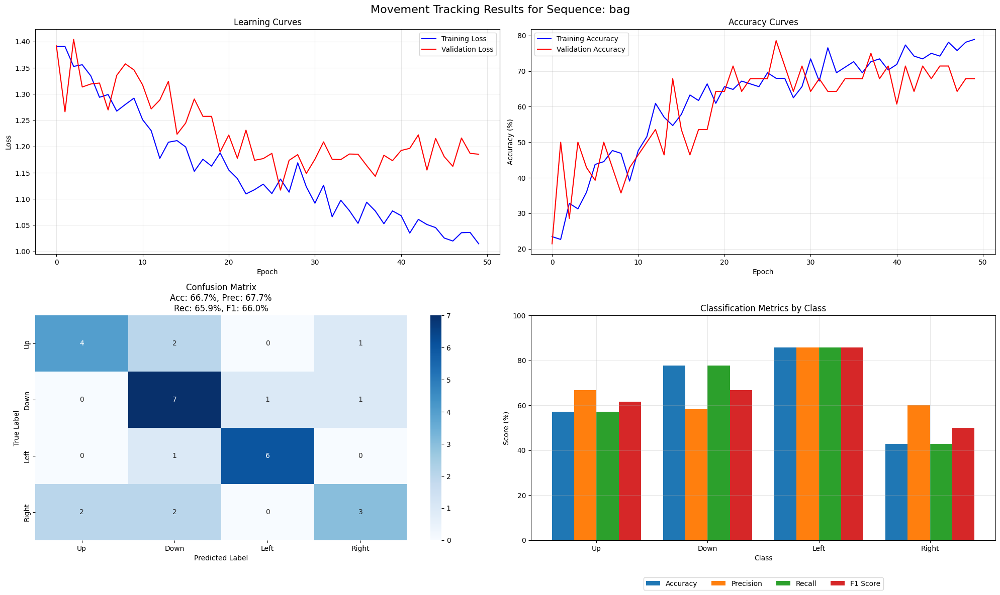

<ipython-input-35-fd02dd47f2ba>:692: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results_df = pd.concat([results_df, pd.DataFrame([sequence_results])], ignore_index=True)


Sequence bag completed with accuracy: 66.67%

[2/60] Processing sequence: ball1
Processed groundtruth for ball1
Processed images for ball1
Cleaned up temporary files for ball1
max 0.9125913381576538
Loaded 104 frames and 105 groundtruth entries
Created 99 mini-videos of 5 frames each
Label distribution:
  Up: 43 (43.4%)
  Down: 43 (43.4%)
  Left: 6 (6.1%)
  Right: 7 (7.1%)
Dataset split: 69 train, 14 val, 16 test
Created SNN model
Training on cpu
Dataset sizes - Train: 69, Val: 14, Test: 16
Consider reducing batch size or using different train/val split ratios.
Epoch 1/50 - Train Loss: 1.7364, Train Acc: 42.19%, Val Loss: 1.6989, Val Acc: 42.86%, LR: 0.070000


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 5/50 - Train Loss: 1.6619, Train Acc: 45.31%, Val Loss: 1.6516, Val Acc: 50.00%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.6564, Train Acc: 45.31%, Val Loss: 1.8038, Val Acc: 35.71%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.5856, Train Acc: 46.88%, Val Loss: 1.7250, Val Acc: 28.57%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.6177, Train Acc: 54.69%, Val Loss: 1.8327, Val Acc: 28.57%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.5204, Train Acc: 60.94%, Val Loss: 1.8888, Val Acc: 35.71%, LR: 0.052500
Epoch 30/50 - Train Loss: 1.6060, Train Acc: 53.12%, Val Loss: 1.6907, Val Acc: 35.71%, LR: 0.052500
Epoch 35/50 - Train Loss: 1.4939, Train Acc: 53.12%, Val Loss: 1.8327, Val Acc: 28.57%, LR: 0.052500
Epoch 40/50 - Train Loss: 1.4774, Train Acc: 65.62%, Val Loss: 1.8430, Val Acc: 28.57%, LR: 0.039375
Epoch 45/50 - Train Loss: 1.5333, Train Acc: 67.19%, Val Loss: 1.7212, Val Acc: 35.71%, LR: 0.039375
Epoch 50/50 - Train Loss: 1.5252, Train Acc: 70.31%, Val Loss: 1.8215, Val Acc: 35.71%, LR: 

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


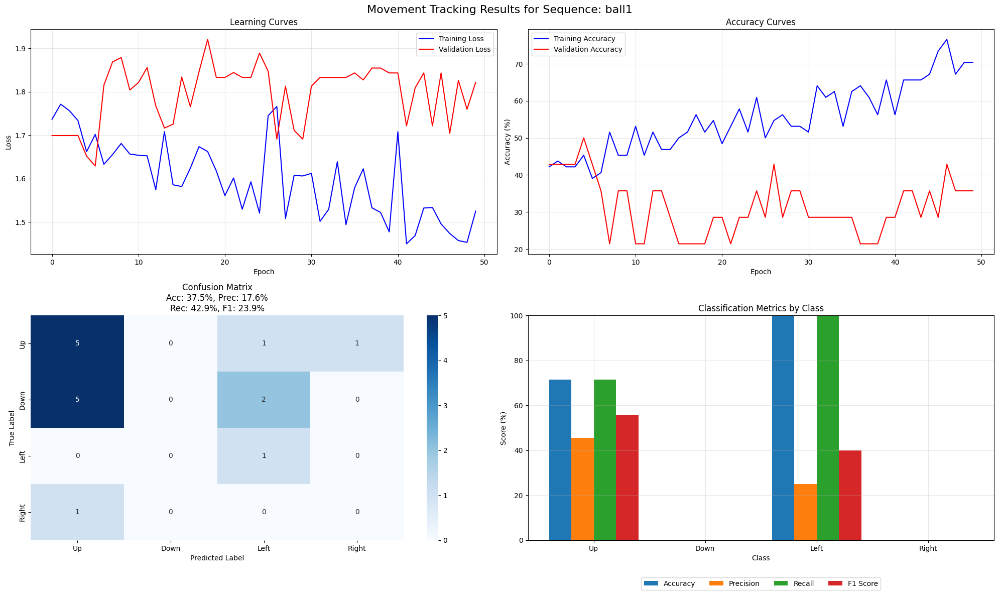

Sequence ball1 completed with accuracy: 37.50%

[3/60] Processing sequence: ball2
Processed groundtruth for ball2
Processed images for ball2
Cleaned up temporary files for ball2
max 0.8019511699676514
Loaded 40 frames and 41 groundtruth entries
Created 35 mini-videos of 5 frames each
Label distribution:
  Down: 19 (54.3%)
  Right: 16 (45.7%)
Dataset split: 24 train, 5 val, 6 test
Created SNN model
Training on cpu
Dataset sizes - Train: 24, Val: 5, Test: 6
Consider reducing batch size or using different train/val split ratios.


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1634971.5000, Train Acc: 0.00%, Val Loss: 1680002.3750, Val Acc: 0.00%, LR: 0.070000
Epoch 5/50 - Train Loss: 1652002.3750, Train Acc: 0.00%, Val Loss: 1680002.3750, Val Acc: 0.00%, LR: 0.070000
Epoch 10/50 - Train Loss: 1652002.3750, Train Acc: 0.00%, Val Loss: 1680002.3750, Val Acc: 0.00%, LR: 0.070000
Epoch 15/50 - Train Loss: 1634971.5000, Train Acc: 0.00%, Val Loss: 1680002.3750, Val Acc: 0.00%, LR: 0.070000
Epoch 20/50 - Train Loss: 1669391.7500, Train Acc: 0.00%, Val Loss: 1738227.1250, Val Acc: 20.00%, LR: 0.052500
Epoch 25/50 - Train Loss: 1658657.3750, Train Acc: 0.00%, Val Loss: 1680002.3750, Val Acc: 0.00%, LR: 0.052500
Epoch 30/50 - Train Loss: 1658657.1250, Train Acc: 0.00%, Val Loss: 1645433.5000, Val Acc: 0.00%, LR: 0.052500
Epoch 35/50 - Train Loss: 1652002.3750, Train Acc: 0.00%, Val Loss: 1680002.3750, Val Acc: 0.00%, LR: 0.052500
Epoch 40/50 - Train Loss: 1613945.1250, Train Acc: 0.00%, Val Loss: 1709114.6250, Val Acc: 0.00%, LR: 0.052500
Ep

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


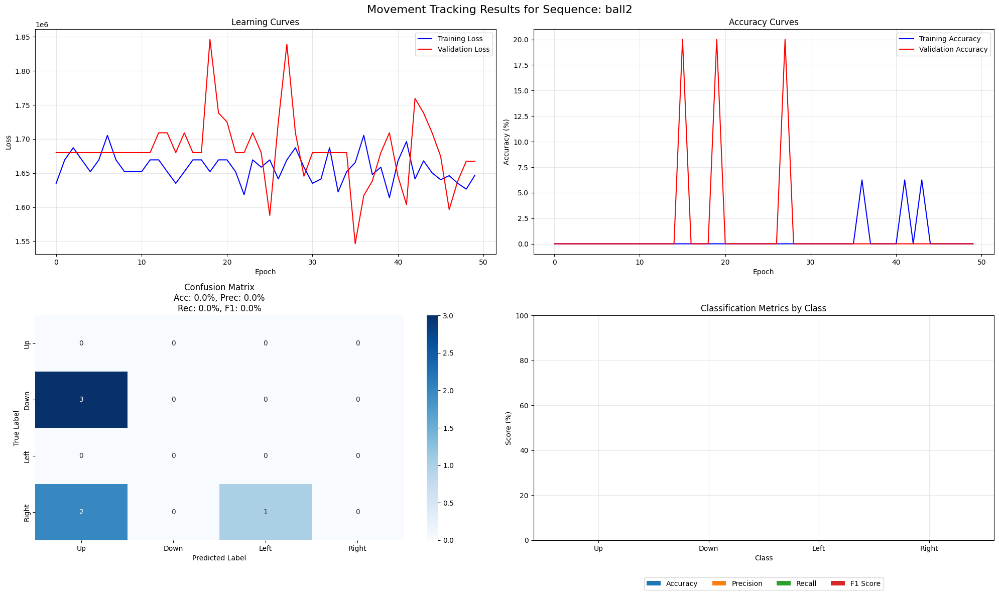

Sequence ball2 completed with accuracy: 0.00%

[4/60] Processing sequence: basketball
Processed groundtruth for basketball
Processed images for basketball
Cleaned up temporary files for basketball
max 0.9056793451309204
Loaded 724 frames and 725 groundtruth entries
Created 719 mini-videos of 5 frames each
Label distribution:
  Up: 104 (14.5%)
  Down: 129 (17.9%)
  Left: 222 (30.9%)
  Right: 264 (36.7%)
Dataset split: 503 train, 107 val, 109 test
Created SNN model
Training on cpu
Dataset sizes - Train: 503, Val: 107, Test: 109


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4176, Train Acc: 15.32%, Val Loss: 1.4179, Val Acc: 23.36%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.1854, Train Acc: 52.02%, Val Loss: 1.1908, Val Acc: 54.21%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.0716, Train Acc: 76.81%, Val Loss: 1.1350, Val Acc: 73.83%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.0330, Train Acc: 82.86%, Val Loss: 1.0819, Val Acc: 77.57%, LR: 0.070000
Epoch 20/50 - Train Loss: 0.9946, Train Acc: 90.52%, Val Loss: 1.0634, Val Acc: 84.11%, LR: 0.070000
Epoch 25/50 - Train Loss: 0.9810, Train Acc: 93.75%, Val Loss: 1.0452, Val Acc: 85.98%, LR: 0.070000
Epoch 30/50 - Train Loss: 0.9922, Train Acc: 90.32%, Val Loss: 1.0671, Val Acc: 81.31%, LR: 0.070000
Epoch 35/50 - Train Loss: 0.9846, Train Acc: 93.55%, Val Loss: 1.0606, Val Acc: 87.85%, LR: 0.070000
Epoch 40/50 - Train Loss: 0.9803, Train Acc: 95.16%, Val Loss: 1.0438, Val Acc: 85.05%, LR: 0.070000
Epoch 45/50 - Train Loss: 0.9732, Train Acc: 96.37%, Val Loss: 1.0519, Val Acc: 86.92%, LR: 0

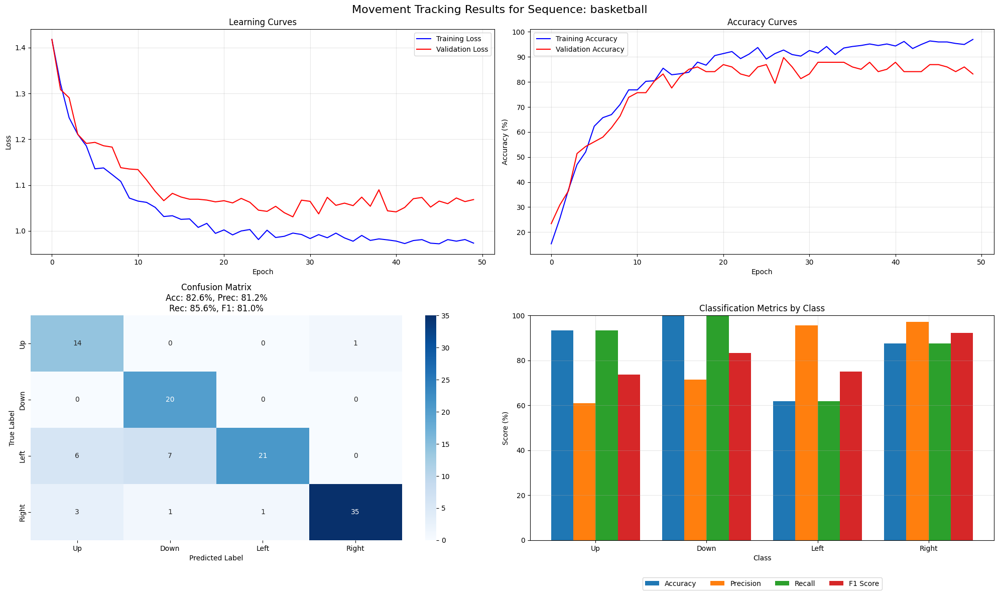

Sequence basketball completed with accuracy: 82.57%

[5/60] Processing sequence: birds1
Processed groundtruth for birds1
Processed images for birds1
Cleaned up temporary files for birds1
max 1.0
Loaded 338 frames and 339 groundtruth entries
Created 333 mini-videos of 5 frames each
Label distribution:
  Up: 102 (30.6%)
  Down: 129 (38.7%)
  Left: 51 (15.3%)
  Right: 51 (15.3%)
Dataset split: 233 train, 49 val, 51 test
Created SNN model
Training on cpu
Dataset sizes - Train: 233, Val: 49, Test: 51


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4393, Train Acc: 30.36%, Val Loss: 1.4176, Val Acc: 44.90%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3393, Train Acc: 45.98%, Val Loss: 1.4344, Val Acc: 36.73%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2734, Train Acc: 55.80%, Val Loss: 1.2916, Val Acc: 59.18%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.1879, Train Acc: 70.09%, Val Loss: 1.2644, Val Acc: 61.22%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1748, Train Acc: 69.20%, Val Loss: 1.2645, Val Acc: 63.27%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1437, Train Acc: 74.55%, Val Loss: 1.2319, Val Acc: 71.43%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1313, Train Acc: 76.79%, Val Loss: 1.2158, Val Acc: 71.43%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1312, Train Acc: 75.89%, Val Loss: 1.2243, Val Acc: 71.43%, LR: 0.052500
Epoch 40/50 - Train Loss: 1.1013, Train Acc: 76.79%, Val Loss: 1.2344, Val Acc: 67.35%, LR: 0.052500
Epoch 45/50 - Train Loss: 1.1164, Train Acc: 77.23%, Val Loss: 1.2293, Val Acc: 71.43%, LR: 0

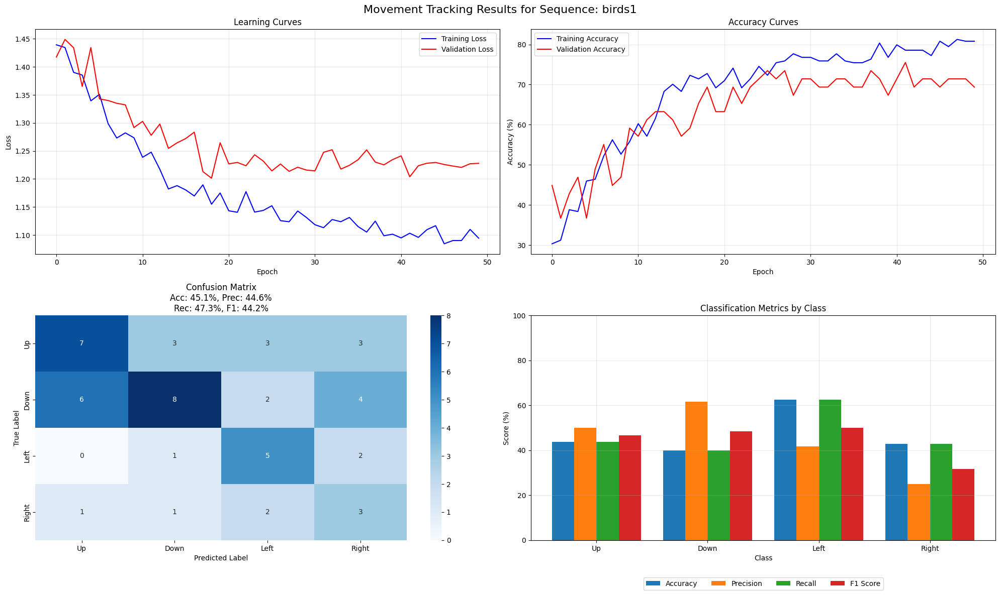

Sequence birds1 completed with accuracy: 45.10%

[6/60] Processing sequence: birds2
Processed groundtruth for birds2
Processed images for birds2
Cleaned up temporary files for birds2
max 1.0
Loaded 538 frames and 539 groundtruth entries
Created 533 mini-videos of 5 frames each
Label distribution:
  Up: 70 (13.1%)
  Down: 60 (11.3%)
  Left: 196 (36.8%)
  Right: 207 (38.8%)
Dataset split: 373 train, 79 val, 81 test
Created SNN model
Training on cpu
Dataset sizes - Train: 373, Val: 79, Test: 81


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4969, Train Acc: 13.32%, Val Loss: 1.5371, Val Acc: 8.86%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.4060, Train Acc: 32.34%, Val Loss: 1.3851, Val Acc: 27.85%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.3226, Train Acc: 48.91%, Val Loss: 1.3370, Val Acc: 34.18%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2848, Train Acc: 56.52%, Val Loss: 1.3046, Val Acc: 54.43%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2500, Train Acc: 63.32%, Val Loss: 1.3130, Val Acc: 55.70%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1957, Train Acc: 73.37%, Val Loss: 1.2867, Val Acc: 62.03%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1783, Train Acc: 70.65%, Val Loss: 1.2664, Val Acc: 65.82%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1561, Train Acc: 74.46%, Val Loss: 1.3183, Val Acc: 67.09%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1610, Train Acc: 77.45%, Val Loss: 1.2814, Val Acc: 67.09%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1508, Train Acc: 80.43%, Val Loss: 1.3126, Val Acc: 67.09%, LR: 0.

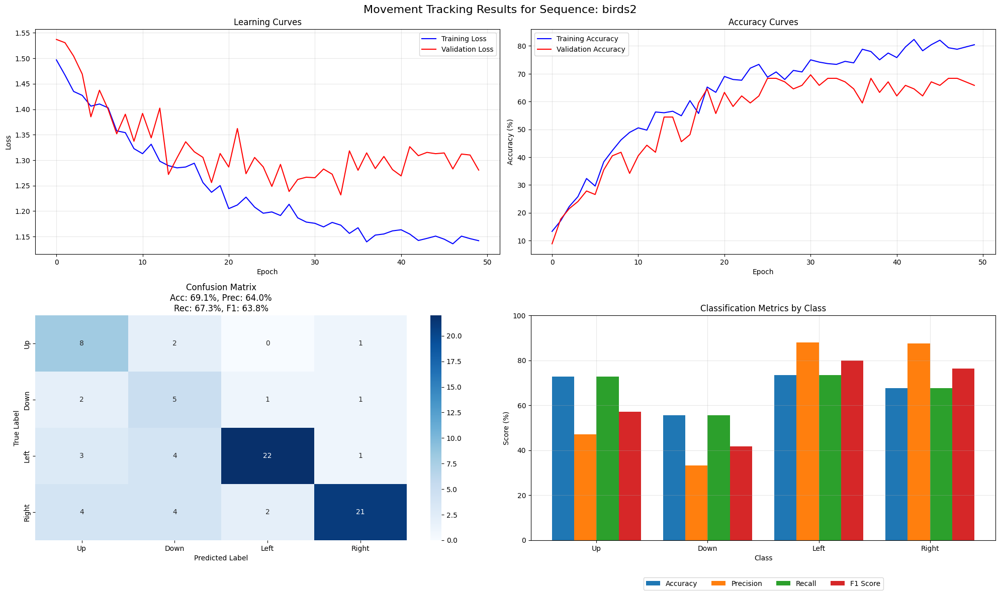

Sequence birds2 completed with accuracy: 69.14%

[7/60] Processing sequence: blanket
Processed groundtruth for blanket
Processed images for blanket
Cleaned up temporary files for blanket
max 1.0
Loaded 224 frames and 225 groundtruth entries
Created 219 mini-videos of 5 frames each
Label distribution:
  Up: 74 (33.8%)
  Down: 81 (37.0%)
  Left: 46 (21.0%)
  Right: 18 (8.2%)
Dataset split: 153 train, 32 val, 34 test
Created SNN model
Training on cpu
Dataset sizes - Train: 153, Val: 32, Test: 34


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.5121, Train Acc: 34.03%, Val Loss: 1.4938, Val Acc: 34.38%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3653, Train Acc: 55.56%, Val Loss: 1.4696, Val Acc: 40.62%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.3525, Train Acc: 54.17%, Val Loss: 1.4091, Val Acc: 56.25%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.3039, Train Acc: 65.97%, Val Loss: 1.3512, Val Acc: 59.38%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2636, Train Acc: 67.36%, Val Loss: 1.4144, Val Acc: 56.25%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2736, Train Acc: 72.22%, Val Loss: 1.3434, Val Acc: 65.62%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.2046, Train Acc: 81.94%, Val Loss: 1.3871, Val Acc: 56.25%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.2033, Train Acc: 79.17%, Val Loss: 1.3706, Val Acc: 62.50%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.2066, Train Acc: 79.86%, Val Loss: 1.3566, Val Acc: 62.50%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1646, Train Acc: 86.11%, Val Loss: 1.3880, Val Acc: 56.25%, LR: 0

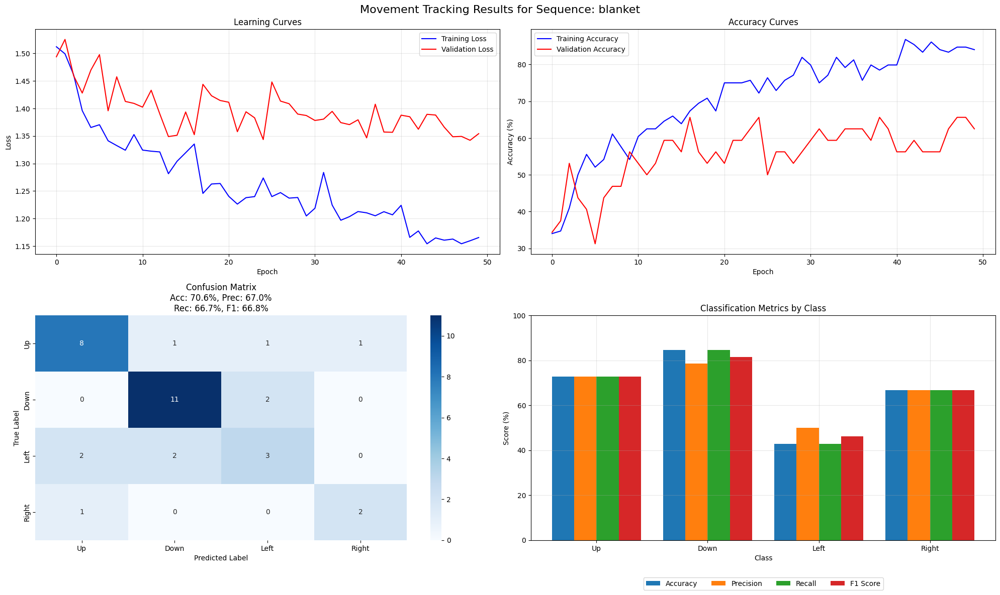

Sequence blanket completed with accuracy: 70.59%

[8/60] Processing sequence: bmx
Processed groundtruth for bmx
Processed images for bmx
Cleaned up temporary files for bmx
max 0.8151480555534363
Loaded 75 frames and 76 groundtruth entries
Created 70 mini-videos of 5 frames each
Label distribution:
  Up: 9 (12.9%)
  Down: 3 (4.3%)
  Left: 43 (61.4%)
  Right: 15 (21.4%)
Error training/evaluating sequence bmx: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.. Skipping.

[9/60] Processing sequence: bolt1
Processed groundtruth for bolt1
Processed images for bolt1
Cleaned up temporary files for bolt1
max 0.9453319907188416
Loaded 349 frames and 350 groundtruth entries
Created 344 mini-videos of 5 frames each
Label distribution:
  Up: 76 (22.1%)
  Down: 47 (13.7%)
  Left: 113 (32.8%)
  Right: 108 (31.4%)
Dataset split: 240 train, 51 val, 53 test
Created SNN model
Training on cpu
Dataset sizes - Train: 240, Va

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4218, Train Acc: 22.50%, Val Loss: 1.4914, Val Acc: 23.53%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3001, Train Acc: 52.92%, Val Loss: 1.3846, Val Acc: 45.10%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.3163, Train Acc: 47.92%, Val Loss: 1.3931, Val Acc: 37.25%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2513, Train Acc: 55.83%, Val Loss: 1.3935, Val Acc: 43.14%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2486, Train Acc: 50.42%, Val Loss: 1.3594, Val Acc: 39.22%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2346, Train Acc: 55.83%, Val Loss: 1.3788, Val Acc: 35.29%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1747, Train Acc: 57.50%, Val Loss: 1.3372, Val Acc: 47.06%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1432, Train Acc: 65.00%, Val Loss: 1.3570, Val Acc: 43.14%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1678, Train Acc: 62.92%, Val Loss: 1.3740, Val Acc: 41.18%, LR: 0.052500
Epoch 45/50 - Train Loss: 1.1363, Train Acc: 66.67%, Val Loss: 1.3233, Val Acc: 45.10%, LR: 0

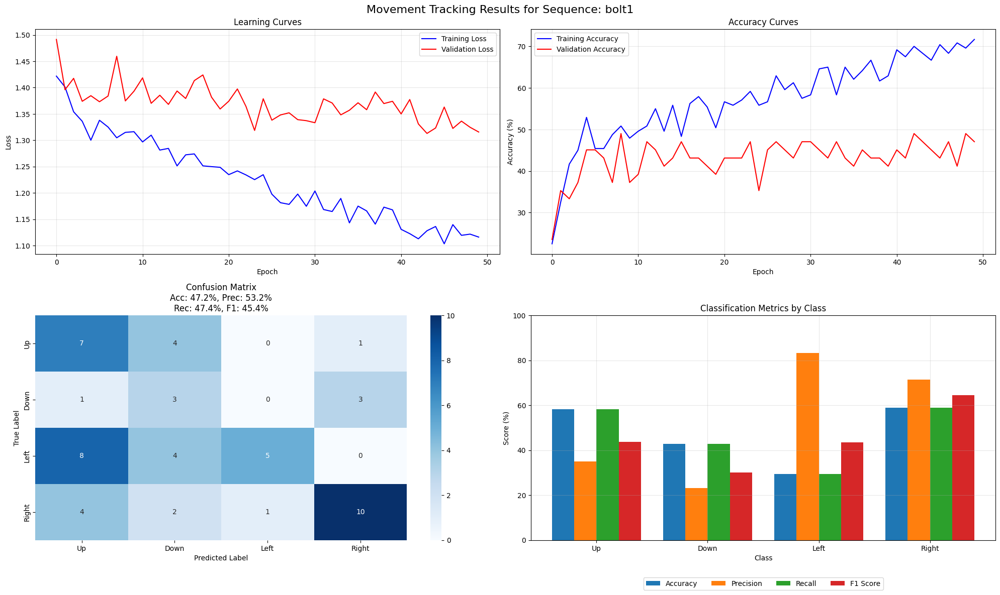

Sequence bolt1 completed with accuracy: 47.17%

[10/60] Processing sequence: bolt2
Processed groundtruth for bolt2
Processed images for bolt2
Cleaned up temporary files for bolt2
max 0.8866044878959656
Loaded 292 frames and 293 groundtruth entries
Created 287 mini-videos of 5 frames each
Label distribution:
  Up: 17 (5.9%)
  Down: 42 (14.6%)
  Left: 83 (28.9%)
  Right: 145 (50.5%)
Dataset split: 200 train, 43 val, 44 test
Created SNN model
Training on cpu
Dataset sizes - Train: 200, Val: 43, Test: 44


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.6294, Train Acc: 6.25%, Val Loss: 1.6589, Val Acc: 9.30%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.5642, Train Acc: 26.56%, Val Loss: 1.6747, Val Acc: 16.28%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.4518, Train Acc: 39.58%, Val Loss: 1.5300, Val Acc: 25.58%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.4094, Train Acc: 48.44%, Val Loss: 1.5308, Val Acc: 32.56%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.4203, Train Acc: 51.56%, Val Loss: 1.5308, Val Acc: 32.56%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.3545, Train Acc: 58.33%, Val Loss: 1.5230, Val Acc: 41.86%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.3893, Train Acc: 60.42%, Val Loss: 1.4945, Val Acc: 46.51%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.3306, Train Acc: 54.17%, Val Loss: 1.4060, Val Acc: 37.21%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.3013, Train Acc: 52.08%, Val Loss: 1.4156, Val Acc: 30.23%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.3262, Train Acc: 55.21%, Val Loss: 1.3948, Val Acc: 25.58%, LR: 0.0

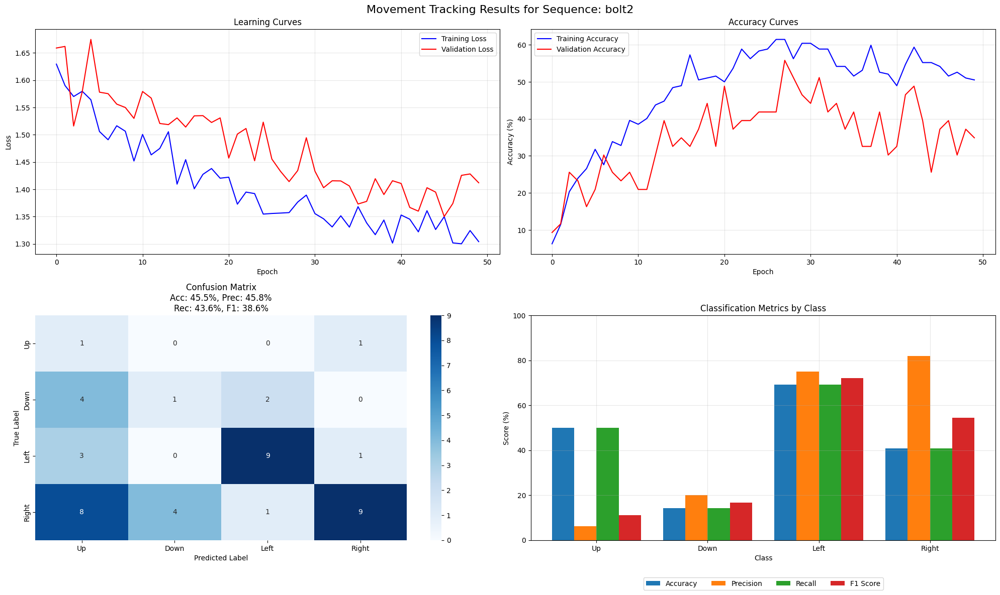

Sequence bolt2 completed with accuracy: 45.45%

[11/60] Processing sequence: book
Processed groundtruth for book
Processed images for book
Cleaned up temporary files for book
max 0.7800294756889343
Loaded 174 frames and 175 groundtruth entries
Created 169 mini-videos of 5 frames each
Label distribution:
  Up: 25 (14.8%)
  Down: 18 (10.7%)
  Left: 57 (33.7%)
  Right: 69 (40.8%)
Dataset split: 118 train, 25 val, 26 test
Created SNN model
Training on cpu
Dataset sizes - Train: 118, Val: 25, Test: 26


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4926, Train Acc: 14.29%, Val Loss: 1.4698, Val Acc: 16.00%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.4092, Train Acc: 30.36%, Val Loss: 1.4802, Val Acc: 28.00%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.3592, Train Acc: 36.61%, Val Loss: 1.4185, Val Acc: 24.00%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.3413, Train Acc: 41.96%, Val Loss: 1.4854, Val Acc: 28.00%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2748, Train Acc: 55.36%, Val Loss: 1.4561, Val Acc: 40.00%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2038, Train Acc: 58.93%, Val Loss: 1.3841, Val Acc: 32.00%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.2252, Train Acc: 60.71%, Val Loss: 1.4004, Val Acc: 36.00%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1992, Train Acc: 63.39%, Val Loss: 1.4421, Val Acc: 36.00%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1709, Train Acc: 70.54%, Val Loss: 1.4656, Val Acc: 36.00%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1355, Train Acc: 71.43%, Val Loss: 1.4114, Val Acc: 44.00%, LR: 0

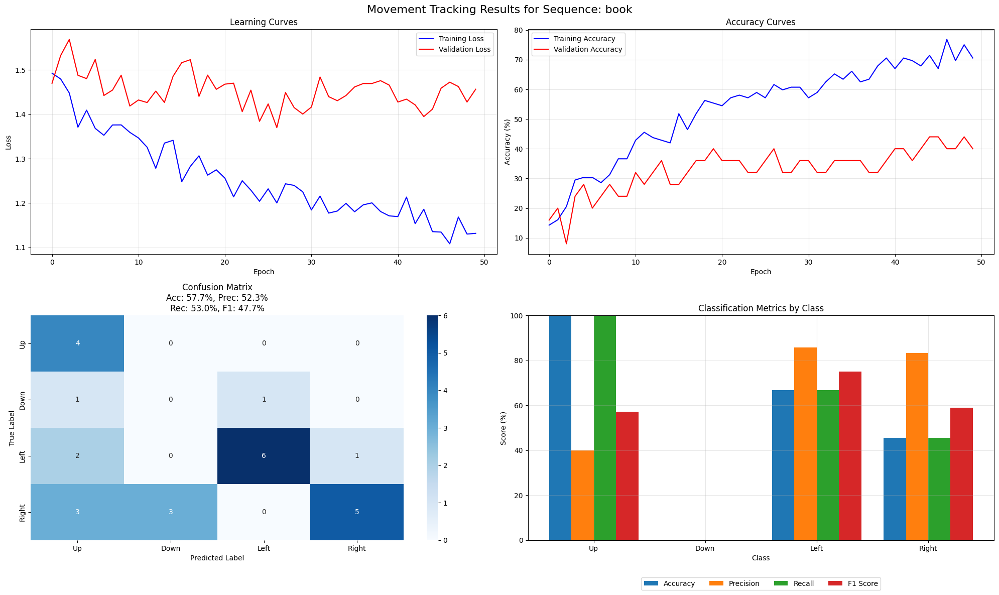

Sequence book completed with accuracy: 57.69%

[12/60] Processing sequence: butterfly
Processed groundtruth for butterfly
Processed images for butterfly
Cleaned up temporary files for butterfly
max 1.0
Loaded 150 frames and 151 groundtruth entries
Created 145 mini-videos of 5 frames each
Label distribution:
  Up: 39 (26.9%)
  Down: 52 (35.9%)
  Left: 11 (7.6%)
  Right: 43 (29.7%)
Dataset split: 101 train, 21 val, 23 test
Created SNN model
Training on cpu
Dataset sizes - Train: 101, Val: 21, Test: 23


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.5046, Train Acc: 26.04%, Val Loss: 1.5337, Val Acc: 28.57%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.4532, Train Acc: 34.38%, Val Loss: 1.4917, Val Acc: 47.62%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.3575, Train Acc: 47.92%, Val Loss: 1.3951, Val Acc: 52.38%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2672, Train Acc: 59.38%, Val Loss: 1.3430, Val Acc: 57.14%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.3151, Train Acc: 52.08%, Val Loss: 1.3156, Val Acc: 61.90%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2867, Train Acc: 62.50%, Val Loss: 1.3179, Val Acc: 66.67%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1898, Train Acc: 72.92%, Val Loss: 1.3089, Val Acc: 66.67%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.2225, Train Acc: 68.75%, Val Loss: 1.3126, Val Acc: 66.67%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.2530, Train Acc: 70.83%, Val Loss: 1.3171, Val Acc: 61.90%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.2044, Train Acc: 75.00%, Val Loss: 1.3080, Val Acc: 61.90%, LR: 0

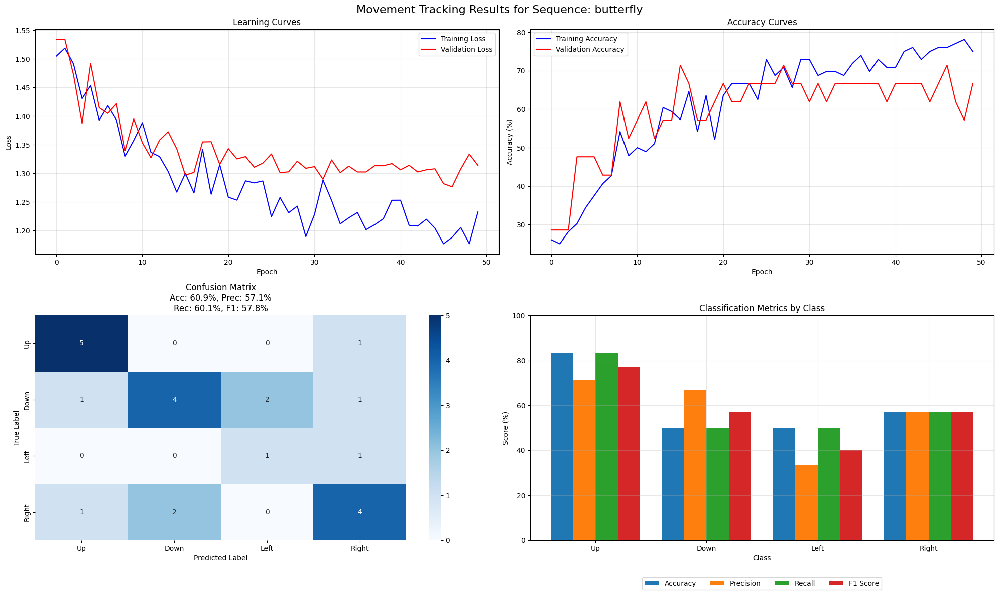

Sequence butterfly completed with accuracy: 60.87%

[13/60] Processing sequence: car1
Processed groundtruth for car1
Processed images for car1
Cleaned up temporary files for car1
max 0.96137934923172
Loaded 741 frames and 742 groundtruth entries
Created 736 mini-videos of 5 frames each
Label distribution:
  Up: 174 (23.6%)
  Down: 172 (23.4%)
  Left: 191 (26.0%)
  Right: 199 (27.0%)
Dataset split: 515 train, 110 val, 111 test
Created SNN model
Training on cpu
Dataset sizes - Train: 515, Val: 110, Test: 111


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.3874, Train Acc: 24.22%, Val Loss: 1.3947, Val Acc: 30.00%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3343, Train Acc: 37.11%, Val Loss: 1.3757, Val Acc: 33.64%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2764, Train Acc: 46.29%, Val Loss: 1.3857, Val Acc: 31.82%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2325, Train Acc: 53.32%, Val Loss: 1.3056, Val Acc: 41.82%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2053, Train Acc: 55.08%, Val Loss: 1.2936, Val Acc: 40.00%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1901, Train Acc: 56.05%, Val Loss: 1.3442, Val Acc: 39.09%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1474, Train Acc: 61.33%, Val Loss: 1.2633, Val Acc: 45.45%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1368, Train Acc: 63.28%, Val Loss: 1.2776, Val Acc: 49.09%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1316, Train Acc: 62.30%, Val Loss: 1.2867, Val Acc: 42.73%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1022, Train Acc: 67.19%, Val Loss: 1.2487, Val Acc: 50.00%, LR: 0

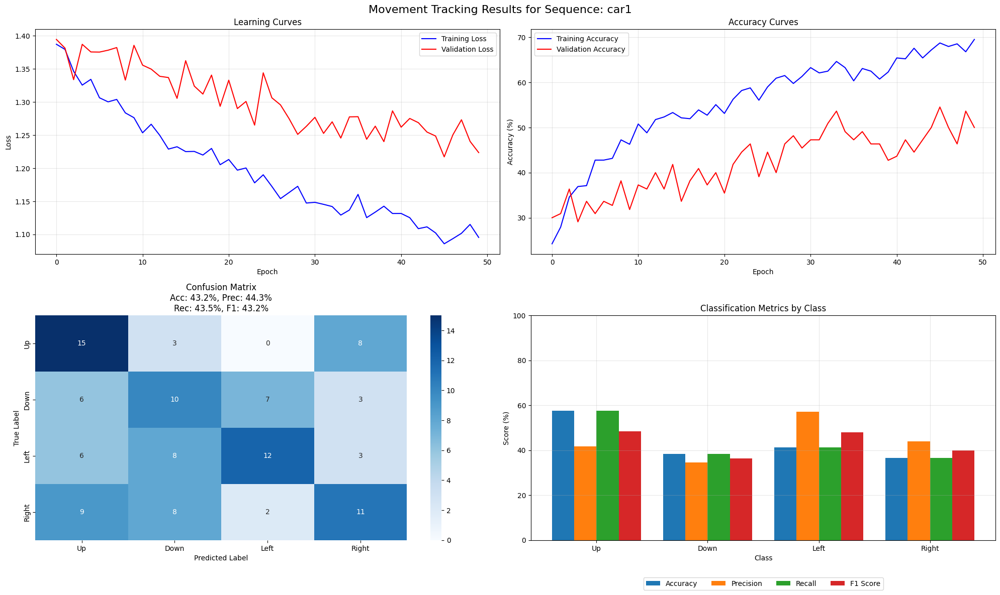

Sequence car1 completed with accuracy: 43.24%

[14/60] Processing sequence: car2
Processed groundtruth for car2
Processed images for car2
Cleaned up temporary files for car2
max 0.9210977554321289
Loaded 392 frames and 393 groundtruth entries
Created 387 mini-videos of 5 frames each
Label distribution:
  Up: 53 (13.7%)
  Down: 62 (16.0%)
  Left: 102 (26.4%)
  Right: 170 (43.9%)
Dataset split: 270 train, 58 val, 59 test
Created SNN model
Training on cpu
Dataset sizes - Train: 270, Val: 58, Test: 59


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4540, Train Acc: 14.06%, Val Loss: 1.4361, Val Acc: 13.79%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3245, Train Acc: 37.50%, Val Loss: 1.3912, Val Acc: 31.03%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2738, Train Acc: 48.44%, Val Loss: 1.3764, Val Acc: 32.76%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2748, Train Acc: 51.56%, Val Loss: 1.3607, Val Acc: 39.66%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2216, Train Acc: 58.20%, Val Loss: 1.3514, Val Acc: 44.83%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2283, Train Acc: 55.86%, Val Loss: 1.3409, Val Acc: 48.28%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1969, Train Acc: 61.72%, Val Loss: 1.3317, Val Acc: 48.28%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1611, Train Acc: 63.28%, Val Loss: 1.3307, Val Acc: 44.83%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1816, Train Acc: 64.45%, Val Loss: 1.3560, Val Acc: 48.28%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1780, Train Acc: 62.89%, Val Loss: 1.3170, Val Acc: 50.00%, LR: 0

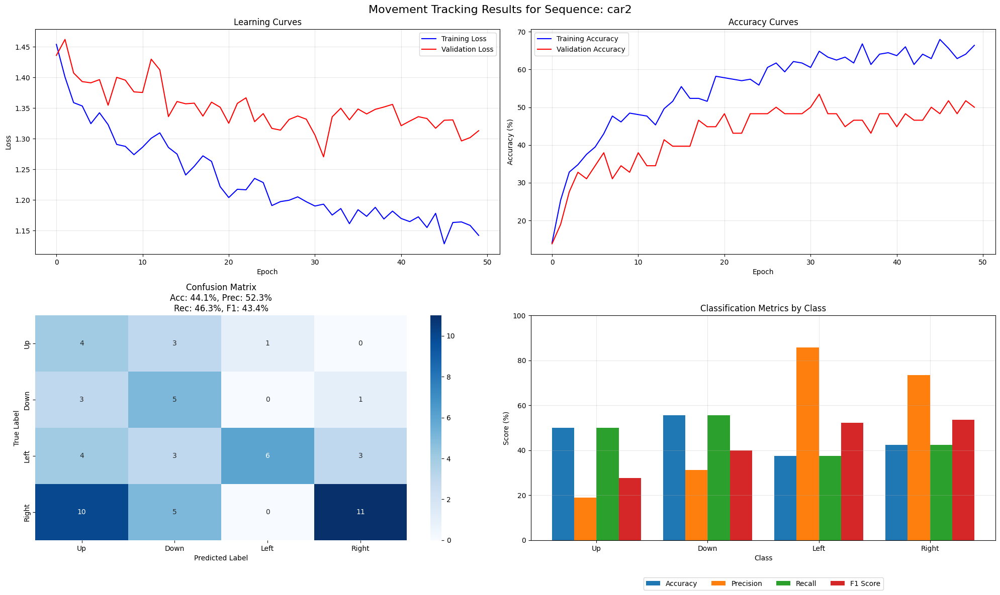

Sequence car2 completed with accuracy: 44.07%

[15/60] Processing sequence: crossing
Processed groundtruth for crossing
Processed images for crossing
Cleaned up temporary files for crossing
max 0.8800000548362732
Loaded 130 frames and 131 groundtruth entries
Created 125 mini-videos of 5 frames each
Label distribution:
  Up: 47 (37.6%)
  Down: 34 (27.2%)
  Left: 21 (16.8%)
  Right: 23 (18.4%)
Dataset split: 87 train, 18 val, 20 test
Created SNN model
Training on cpu
Dataset sizes - Train: 87, Val: 18, Test: 20
Epoch 1/50 - Train Loss: 1.4184, Train Acc: 37.50%, Val Loss: 1.4222, Val Acc: 38.89%, LR: 0.070000


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 5/50 - Train Loss: 1.3449, Train Acc: 52.50%, Val Loss: 1.3368, Val Acc: 44.44%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2464, Train Acc: 62.50%, Val Loss: 1.2445, Val Acc: 72.22%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2544, Train Acc: 65.00%, Val Loss: 1.1841, Val Acc: 77.78%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2286, Train Acc: 63.75%, Val Loss: 1.3357, Val Acc: 61.11%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1973, Train Acc: 65.00%, Val Loss: 1.2394, Val Acc: 61.11%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1211, Train Acc: 73.75%, Val Loss: 1.1874, Val Acc: 61.11%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0939, Train Acc: 77.50%, Val Loss: 1.1913, Val Acc: 72.22%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0973, Train Acc: 76.25%, Val Loss: 1.1736, Val Acc: 77.78%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0650, Train Acc: 83.75%, Val Loss: 1.2045, Val Acc: 72.22%, LR: 0.070000
Epoch 50/50 - Train Loss: 1.0696, Train Acc: 80.00%, Val Loss: 1.2052, Val Acc: 72.22%, LR: 

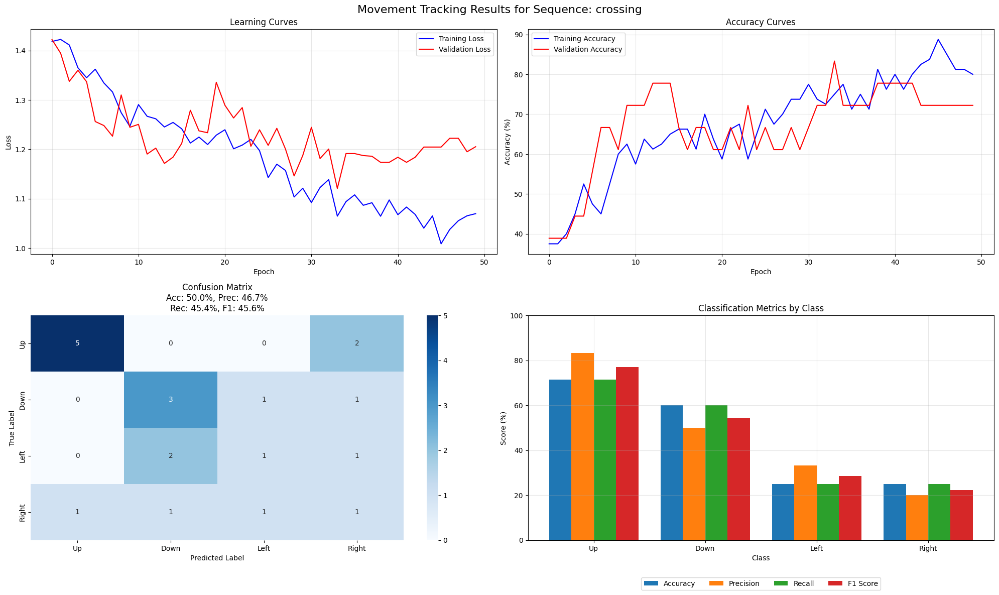

Sequence crossing completed with accuracy: 50.00%

[16/60] Processing sequence: dinosaur
Processed groundtruth for dinosaur
Processed images for dinosaur
Cleaned up temporary files for dinosaur
max 1.0
Loaded 325 frames and 326 groundtruth entries
Created 320 mini-videos of 5 frames each
Label distribution:
  Up: 39 (12.2%)
  Down: 76 (23.8%)
  Left: 112 (35.0%)
  Right: 93 (29.1%)
Dataset split: 223 train, 48 val, 49 test
Created SNN model
Training on cpu
Dataset sizes - Train: 223, Val: 48, Test: 49


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4392, Train Acc: 12.02%, Val Loss: 1.3745, Val Acc: 16.67%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2822, Train Acc: 42.31%, Val Loss: 1.3586, Val Acc: 27.08%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.1961, Train Acc: 55.77%, Val Loss: 1.2826, Val Acc: 43.75%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.1658, Train Acc: 62.02%, Val Loss: 1.2763, Val Acc: 47.92%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1143, Train Acc: 73.08%, Val Loss: 1.1786, Val Acc: 60.42%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1058, Train Acc: 70.67%, Val Loss: 1.1488, Val Acc: 60.42%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.0934, Train Acc: 75.00%, Val Loss: 1.2105, Val Acc: 58.33%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0966, Train Acc: 77.40%, Val Loss: 1.2158, Val Acc: 62.50%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0790, Train Acc: 81.25%, Val Loss: 1.1720, Val Acc: 68.75%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0350, Train Acc: 86.54%, Val Loss: 1.1879, Val Acc: 66.67%, LR: 0

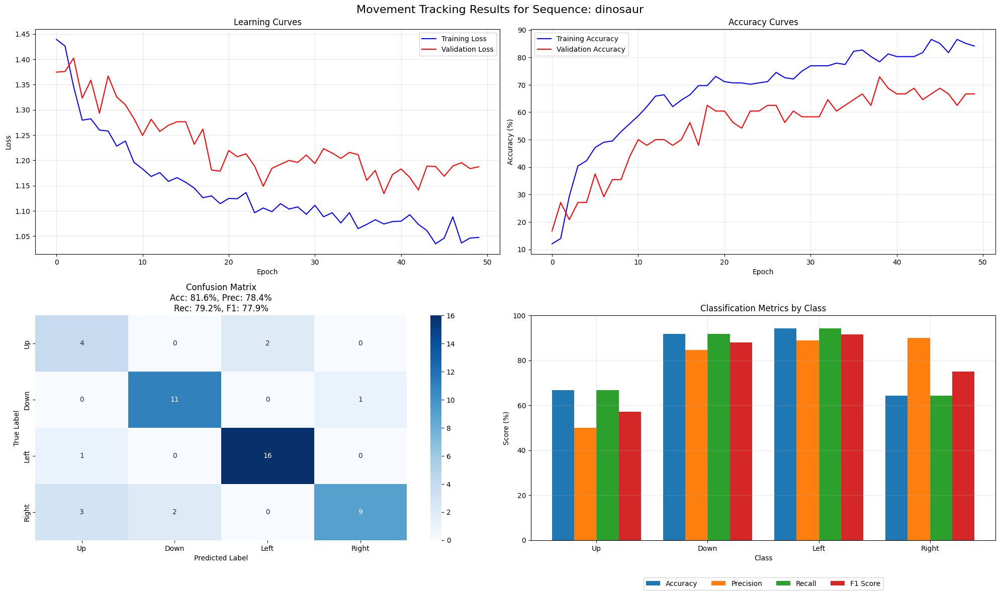

Sequence dinosaur completed with accuracy: 81.63%

[17/60] Processing sequence: fernando
Processed groundtruth for fernando
Processed images for fernando
Cleaned up temporary files for fernando
max 1.0
Loaded 291 frames and 292 groundtruth entries
Created 286 mini-videos of 5 frames each
Label distribution:
  Up: 73 (25.5%)
  Down: 60 (21.0%)
  Left: 75 (26.2%)
  Right: 78 (27.3%)
Dataset split: 200 train, 42 val, 44 test
Created SNN model
Training on cpu
Dataset sizes - Train: 200, Val: 42, Test: 44


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.3893, Train Acc: 26.56%, Val Loss: 1.3888, Val Acc: 26.19%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2721, Train Acc: 48.44%, Val Loss: 1.3250, Val Acc: 38.10%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2311, Train Acc: 54.17%, Val Loss: 1.3146, Val Acc: 42.86%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.1486, Train Acc: 63.54%, Val Loss: 1.2913, Val Acc: 45.24%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1116, Train Acc: 69.27%, Val Loss: 1.2481, Val Acc: 50.00%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1167, Train Acc: 65.62%, Val Loss: 1.2521, Val Acc: 52.38%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.0894, Train Acc: 71.88%, Val Loss: 1.2236, Val Acc: 54.76%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0907, Train Acc: 71.88%, Val Loss: 1.1722, Val Acc: 61.90%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0853, Train Acc: 71.35%, Val Loss: 1.1919, Val Acc: 59.52%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0992, Train Acc: 70.31%, Val Loss: 1.1265, Val Acc: 66.67%, LR: 0

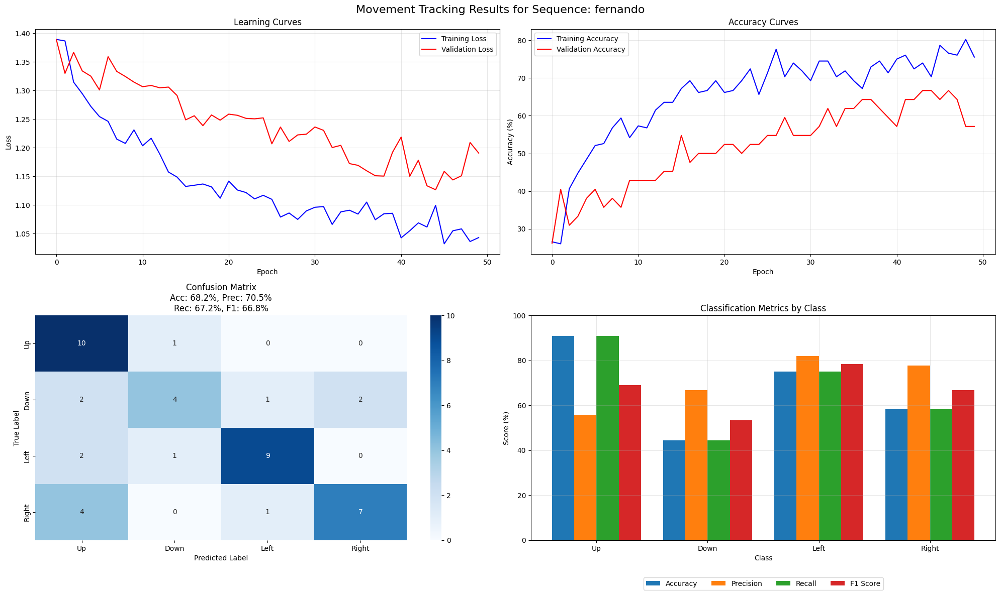

Sequence fernando completed with accuracy: 68.18%

[18/60] Processing sequence: fish1
Processed groundtruth for fish1
Processed images for fish1
Cleaned up temporary files for fish1
max 0.9415282607078552
Loaded 365 frames and 366 groundtruth entries
Created 360 mini-videos of 5 frames each
Label distribution:
  Up: 46 (12.8%)
  Down: 90 (25.0%)
  Left: 74 (20.6%)
  Right: 150 (41.7%)
Dataset split: 251 train, 54 val, 55 test
Created SNN model
Training on cpu
Dataset sizes - Train: 251, Val: 54, Test: 55


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4394, Train Acc: 13.33%, Val Loss: 1.2704, Val Acc: 31.48%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.1079, Train Acc: 68.75%, Val Loss: 1.0826, Val Acc: 74.07%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.0626, Train Acc: 80.83%, Val Loss: 1.0297, Val Acc: 87.04%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.0330, Train Acc: 87.08%, Val Loss: 1.0152, Val Acc: 92.59%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.0170, Train Acc: 90.83%, Val Loss: 1.0126, Val Acc: 92.59%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.0059, Train Acc: 91.67%, Val Loss: 1.0255, Val Acc: 92.59%, LR: 0.052500
Epoch 30/50 - Train Loss: 1.0110, Train Acc: 92.08%, Val Loss: 1.0001, Val Acc: 92.59%, LR: 0.052500
Epoch 35/50 - Train Loss: 0.9918, Train Acc: 92.92%, Val Loss: 1.0237, Val Acc: 94.44%, LR: 0.052500
Epoch 40/50 - Train Loss: 0.9883, Train Acc: 95.83%, Val Loss: 1.0031, Val Acc: 92.59%, LR: 0.052500
Epoch 45/50 - Train Loss: 0.9942, Train Acc: 93.75%, Val Loss: 1.0037, Val Acc: 94.44%, LR: 0

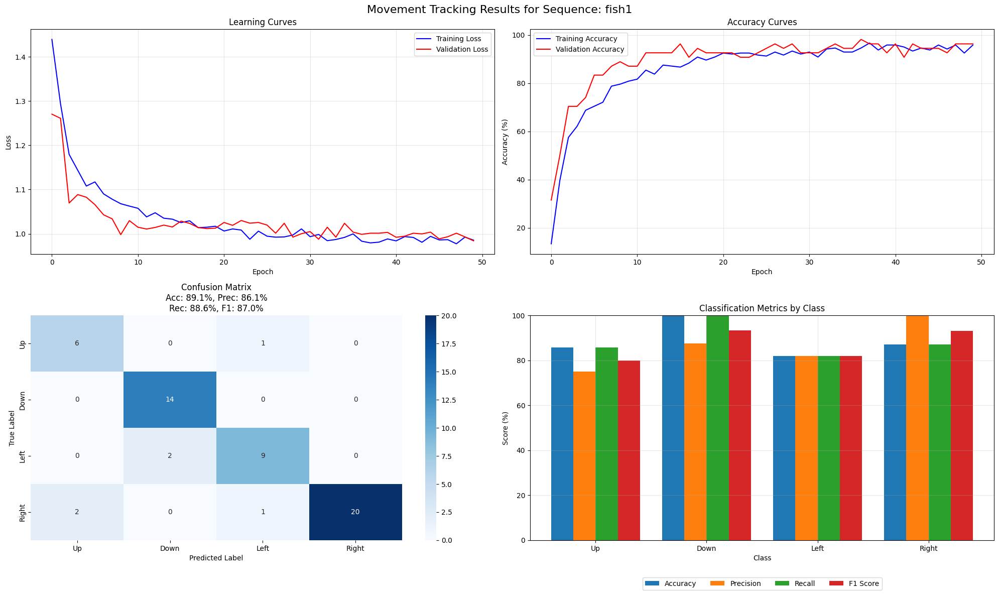

Sequence fish1 completed with accuracy: 89.09%

[19/60] Processing sequence: fish2
Processed groundtruth for fish2
Processed images for fish2
Cleaned up temporary files for fish2
max 0.9636363983154297
Loaded 309 frames and 310 groundtruth entries
Created 304 mini-videos of 5 frames each
Label distribution:
  Up: 37 (12.2%)
  Down: 78 (25.7%)
  Left: 80 (26.3%)
  Right: 109 (35.9%)
Dataset split: 212 train, 45 val, 47 test
Created SNN model
Training on cpu
Dataset sizes - Train: 212, Val: 45, Test: 47


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4363, Train Acc: 12.02%, Val Loss: 1.4514, Val Acc: 22.22%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3185, Train Acc: 37.98%, Val Loss: 1.4045, Val Acc: 28.89%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2851, Train Acc: 50.00%, Val Loss: 1.3887, Val Acc: 33.33%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2176, Train Acc: 56.73%, Val Loss: 1.3295, Val Acc: 42.22%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2047, Train Acc: 58.65%, Val Loss: 1.3721, Val Acc: 42.22%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1907, Train Acc: 63.94%, Val Loss: 1.3460, Val Acc: 51.11%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1997, Train Acc: 63.46%, Val Loss: 1.3261, Val Acc: 51.11%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1555, Train Acc: 70.67%, Val Loss: 1.2970, Val Acc: 51.11%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1575, Train Acc: 70.19%, Val Loss: 1.3380, Val Acc: 46.67%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1592, Train Acc: 66.35%, Val Loss: 1.3129, Val Acc: 48.89%, LR: 0

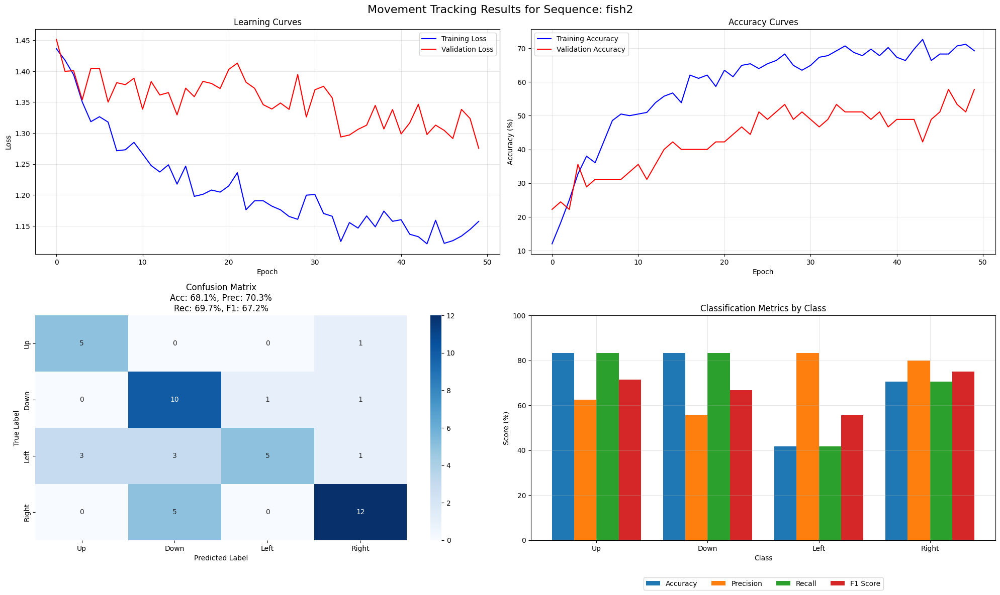

Sequence fish2 completed with accuracy: 68.09%

[20/60] Processing sequence: fish3
Processed groundtruth for fish3
Processed images for fish3
Cleaned up temporary files for fish3
max 1.0
Loaded 518 frames and 519 groundtruth entries
Created 513 mini-videos of 5 frames each
Label distribution:
  Up: 77 (15.0%)
  Down: 76 (14.8%)
  Left: 133 (25.9%)
  Right: 227 (44.2%)
Dataset split: 359 train, 76 val, 78 test
Created SNN model
Training on cpu
Dataset sizes - Train: 359, Val: 76, Test: 78


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4503, Train Acc: 15.06%, Val Loss: 1.5181, Val Acc: 17.11%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3431, Train Acc: 39.77%, Val Loss: 1.3449, Val Acc: 38.16%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2910, Train Acc: 46.59%, Val Loss: 1.3298, Val Acc: 40.79%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2535, Train Acc: 51.70%, Val Loss: 1.3261, Val Acc: 35.53%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2444, Train Acc: 57.39%, Val Loss: 1.3261, Val Acc: 46.05%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1943, Train Acc: 62.78%, Val Loss: 1.2883, Val Acc: 44.74%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1941, Train Acc: 57.95%, Val Loss: 1.2512, Val Acc: 48.68%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1630, Train Acc: 64.20%, Val Loss: 1.2535, Val Acc: 57.89%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1592, Train Acc: 68.18%, Val Loss: 1.2898, Val Acc: 51.32%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1297, Train Acc: 70.17%, Val Loss: 1.2524, Val Acc: 53.95%, LR: 0

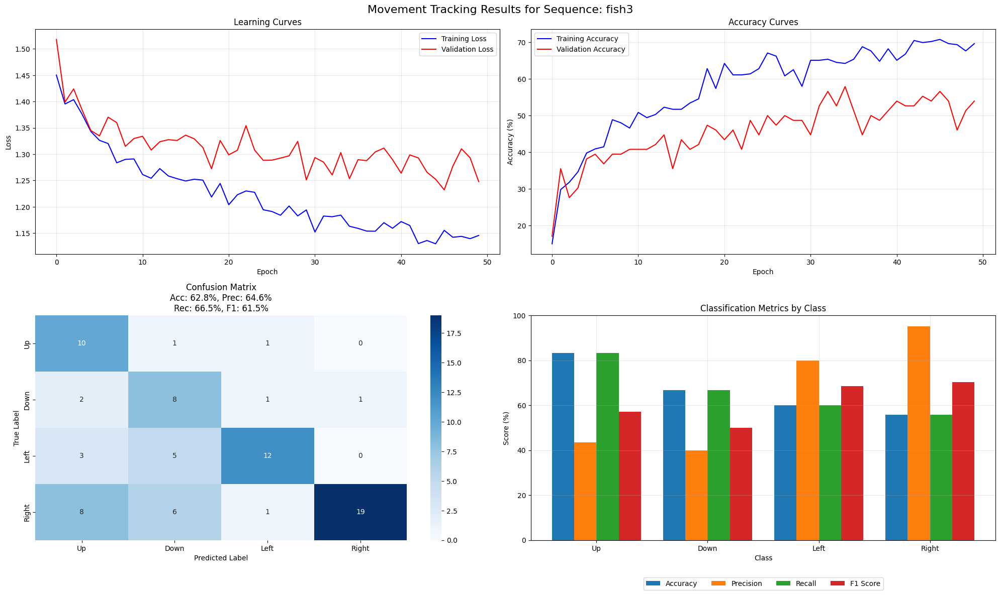

Sequence fish3 completed with accuracy: 62.82%

[21/60] Processing sequence: fish4
Processed groundtruth for fish4
Processed images for fish4
Cleaned up temporary files for fish4
max 1.0
Loaded 681 frames and 682 groundtruth entries
Created 676 mini-videos of 5 frames each
Label distribution:
  Up: 73 (10.8%)
  Down: 119 (17.6%)
  Left: 296 (43.8%)
  Right: 188 (27.8%)
Dataset split: 473 train, 101 val, 102 test
Created SNN model
Training on cpu
Dataset sizes - Train: 473, Val: 101, Test: 102


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4654, Train Acc: 13.58%, Val Loss: 1.4832, Val Acc: 11.88%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2847, Train Acc: 42.67%, Val Loss: 1.2814, Val Acc: 44.55%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.1617, Train Acc: 69.83%, Val Loss: 1.1450, Val Acc: 76.24%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.1288, Train Acc: 76.94%, Val Loss: 1.1069, Val Acc: 80.20%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.0815, Train Acc: 85.13%, Val Loss: 1.0925, Val Acc: 89.11%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.0604, Train Acc: 87.50%, Val Loss: 1.0649, Val Acc: 80.20%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.0586, Train Acc: 87.93%, Val Loss: 1.0640, Val Acc: 91.09%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0501, Train Acc: 91.59%, Val Loss: 1.0583, Val Acc: 91.09%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0399, Train Acc: 92.67%, Val Loss: 1.0685, Val Acc: 92.08%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0364, Train Acc: 92.67%, Val Loss: 1.0402, Val Acc: 94.06%, LR: 0

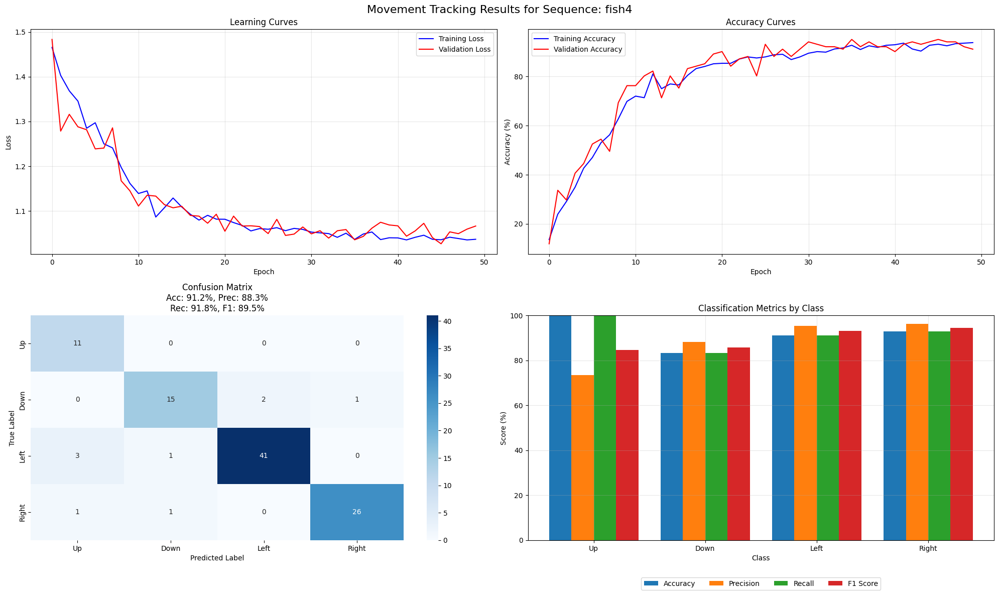

Sequence fish4 completed with accuracy: 91.18%

[22/60] Processing sequence: girl
Processed groundtruth for girl
Processed images for girl
Cleaned up temporary files for girl
max 0.9783439636230469
Loaded 1499 frames and 1500 groundtruth entries
Created 1494 mini-videos of 5 frames each
Label distribution:
  Up: 275 (18.4%)
  Down: 324 (21.7%)
  Left: 464 (31.1%)
  Right: 431 (28.8%)
Dataset split: 1045 train, 224 val, 225 test
Created SNN model
Training on cpu
Dataset sizes - Train: 1045, Val: 224, Test: 225


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.3858, Train Acc: 21.54%, Val Loss: 1.3414, Val Acc: 35.71%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2241, Train Acc: 55.19%, Val Loss: 1.1932, Val Acc: 58.48%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.1041, Train Acc: 69.71%, Val Loss: 1.1260, Val Acc: 70.98%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.0337, Train Acc: 79.13%, Val Loss: 1.0915, Val Acc: 75.89%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.0050, Train Acc: 83.75%, Val Loss: 1.0494, Val Acc: 79.91%, LR: 0.070000
Epoch 25/50 - Train Loss: 0.9929, Train Acc: 87.02%, Val Loss: 1.0581, Val Acc: 78.57%, LR: 0.070000
Epoch 30/50 - Train Loss: 0.9855, Train Acc: 88.46%, Val Loss: 1.0638, Val Acc: 83.48%, LR: 0.070000
Epoch 35/50 - Train Loss: 0.9769, Train Acc: 89.81%, Val Loss: 1.0262, Val Acc: 85.71%, LR: 0.070000
Epoch 40/50 - Train Loss: 0.9601, Train Acc: 92.02%, Val Loss: 1.0220, Val Acc: 87.50%, LR: 0.070000
Epoch 45/50 - Train Loss: 0.9534, Train Acc: 93.17%, Val Loss: 1.0250, Val Acc: 86.16%, LR: 0

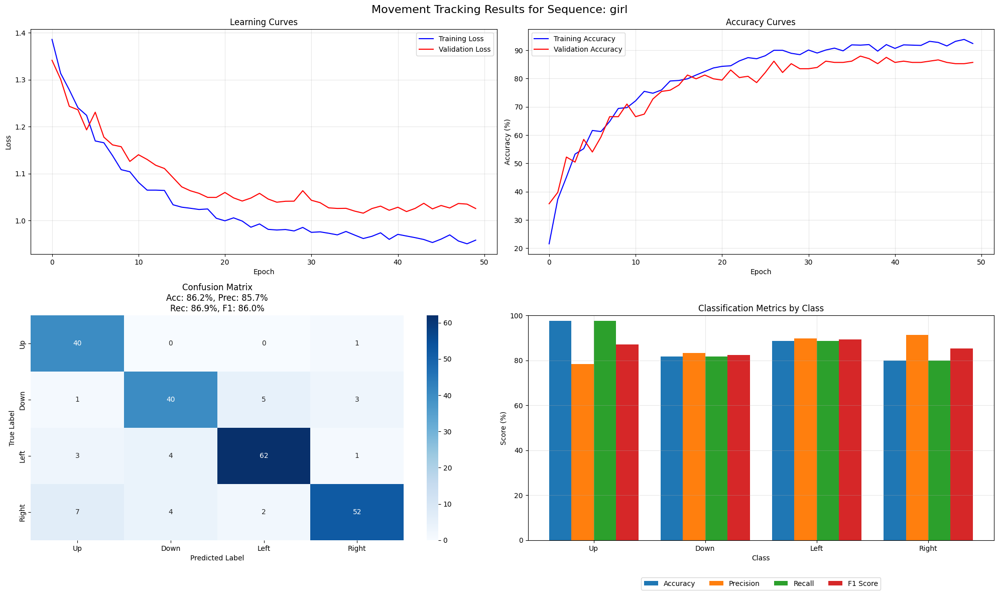

Sequence girl completed with accuracy: 86.22%

[23/60] Processing sequence: glove
Processed groundtruth for glove
Processed images for glove
Cleaned up temporary files for glove
max 0.8157362341880798
Loaded 119 frames and 120 groundtruth entries
Created 114 mini-videos of 5 frames each
Label distribution:
  Up: 8 (7.0%)
  Down: 24 (21.1%)
  Left: 44 (38.6%)
  Right: 38 (33.3%)
Dataset split: 79 train, 17 val, 18 test
Created SNN model
Training on cpu
Dataset sizes - Train: 79, Val: 17, Test: 18
Epoch 1/50 - Train Loss: 1.5319, Train Acc: 7.81%, Val Loss: 1.5464, Val Acc: 5.88%, LR: 0.070000


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 5/50 - Train Loss: 1.4836, Train Acc: 23.44%, Val Loss: 1.4257, Val Acc: 23.53%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.3665, Train Acc: 40.62%, Val Loss: 1.5817, Val Acc: 23.53%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.3889, Train Acc: 40.62%, Val Loss: 1.3587, Val Acc: 47.06%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2274, Train Acc: 65.62%, Val Loss: 1.5460, Val Acc: 35.29%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2259, Train Acc: 67.19%, Val Loss: 1.5898, Val Acc: 23.53%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.2798, Train Acc: 59.38%, Val Loss: 1.5606, Val Acc: 29.41%, LR: 0.052500
Epoch 35/50 - Train Loss: 1.1901, Train Acc: 64.06%, Val Loss: 1.3661, Val Acc: 41.18%, LR: 0.052500
Epoch 40/50 - Train Loss: 1.1791, Train Acc: 65.62%, Val Loss: 1.5189, Val Acc: 41.18%, LR: 0.052500
Epoch 45/50 - Train Loss: 1.2438, Train Acc: 68.75%, Val Loss: 1.4164, Val Acc: 47.06%, LR: 0.039375
Epoch 50/50 - Train Loss: 1.1500, Train Acc: 73.44%, Val Loss: 1.4478, Val Acc: 41.18%, LR: 

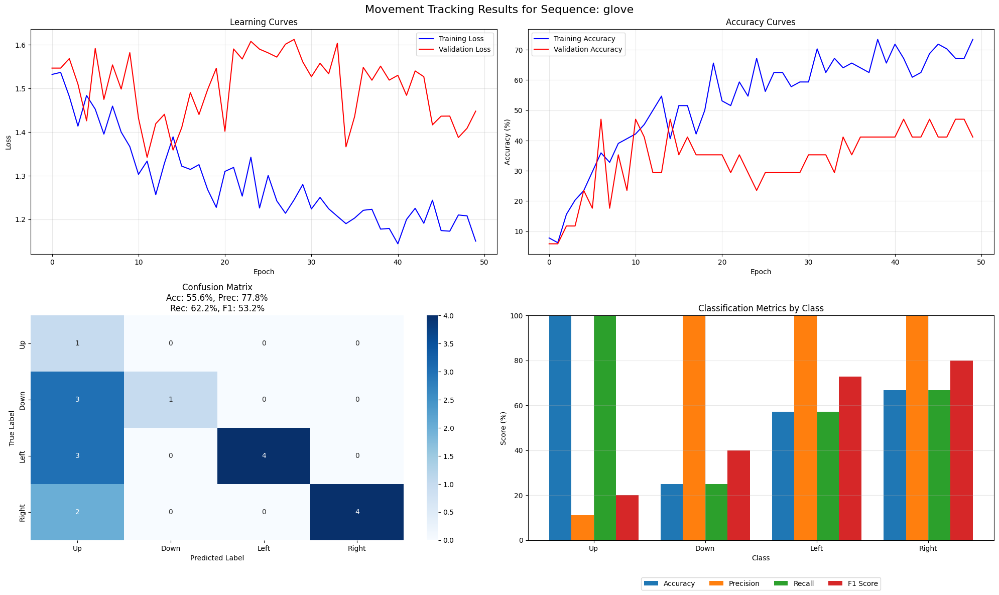

Sequence glove completed with accuracy: 55.56%

[24/60] Processing sequence: godfather
Processed groundtruth for godfather
Processed images for godfather
Cleaned up temporary files for godfather
max 0.9174182415008545
Loaded 365 frames and 366 groundtruth entries
Created 360 mini-videos of 5 frames each
Label distribution:
  Up: 96 (26.7%)
  Down: 93 (25.8%)
  Left: 71 (19.7%)
  Right: 100 (27.8%)
Dataset split: 251 train, 54 val, 55 test
Created SNN model
Training on cpu
Dataset sizes - Train: 251, Val: 54, Test: 55


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.3932, Train Acc: 25.83%, Val Loss: 1.3026, Val Acc: 25.93%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.1565, Train Acc: 62.08%, Val Loss: 1.1506, Val Acc: 64.81%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.0449, Train Acc: 77.50%, Val Loss: 1.0698, Val Acc: 77.78%, LR: 0.070000
Epoch 15/50 - Train Loss: 0.9962, Train Acc: 83.75%, Val Loss: 1.0277, Val Acc: 83.33%, LR: 0.070000
Epoch 20/50 - Train Loss: 0.9954, Train Acc: 82.50%, Val Loss: 1.0018, Val Acc: 88.89%, LR: 0.070000
Epoch 25/50 - Train Loss: 0.9758, Train Acc: 87.50%, Val Loss: 0.9767, Val Acc: 88.89%, LR: 0.070000
Epoch 30/50 - Train Loss: 0.9530, Train Acc: 92.50%, Val Loss: 0.9947, Val Acc: 88.89%, LR: 0.070000
Epoch 35/50 - Train Loss: 0.9507, Train Acc: 93.75%, Val Loss: 0.9767, Val Acc: 88.89%, LR: 0.070000
Epoch 40/50 - Train Loss: 0.9474, Train Acc: 92.92%, Val Loss: 0.9665, Val Acc: 90.74%, LR: 0.070000
Epoch 45/50 - Train Loss: 0.9298, Train Acc: 94.58%, Val Loss: 1.0043, Val Acc: 83.33%, LR: 0

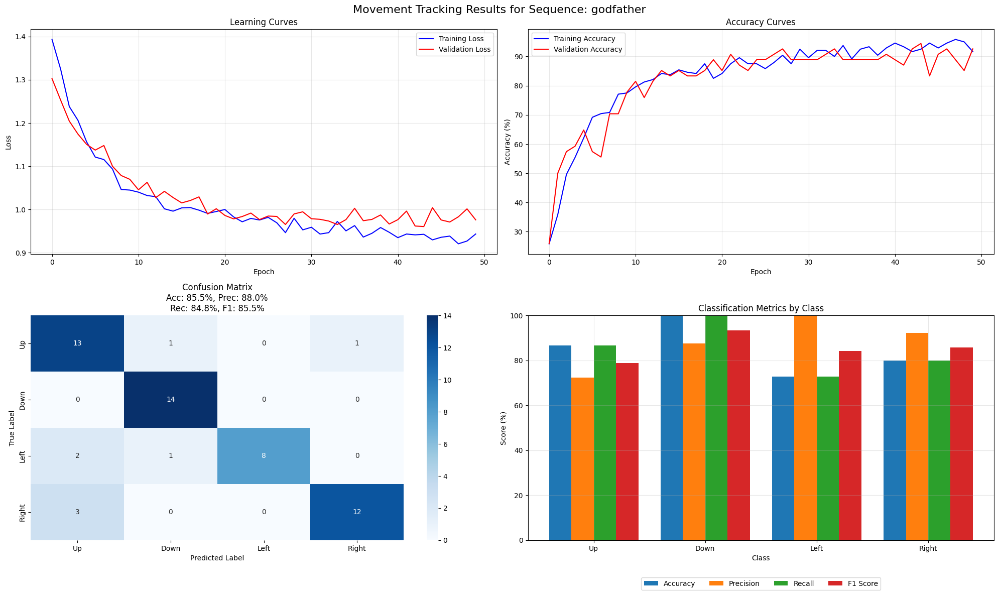

Sequence godfather completed with accuracy: 85.45%

[25/60] Processing sequence: graduate
Processed groundtruth for graduate
Processed images for graduate
Cleaned up temporary files for graduate
max 1.0
Loaded 843 frames and 844 groundtruth entries
Created 838 mini-videos of 5 frames each
Label distribution:
  Up: 140 (16.7%)
  Down: 149 (17.8%)
  Left: 236 (28.2%)
  Right: 313 (37.4%)
Dataset split: 586 train, 125 val, 127 test
Created SNN model
Training on cpu
Dataset sizes - Train: 586, Val: 125, Test: 127


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4237, Train Acc: 17.19%, Val Loss: 1.3911, Val Acc: 21.60%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2972, Train Acc: 40.62%, Val Loss: 1.2414, Val Acc: 46.40%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2573, Train Acc: 51.39%, Val Loss: 1.2660, Val Acc: 56.80%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2068, Train Acc: 57.99%, Val Loss: 1.2337, Val Acc: 60.00%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1624, Train Acc: 64.93%, Val Loss: 1.1850, Val Acc: 60.80%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1457, Train Acc: 68.92%, Val Loss: 1.1865, Val Acc: 65.60%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1322, Train Acc: 70.14%, Val Loss: 1.1795, Val Acc: 62.40%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0864, Train Acc: 75.52%, Val Loss: 1.1425, Val Acc: 71.20%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1051, Train Acc: 73.26%, Val Loss: 1.1651, Val Acc: 65.60%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0766, Train Acc: 80.03%, Val Loss: 1.1404, Val Acc: 70.40%, LR: 0

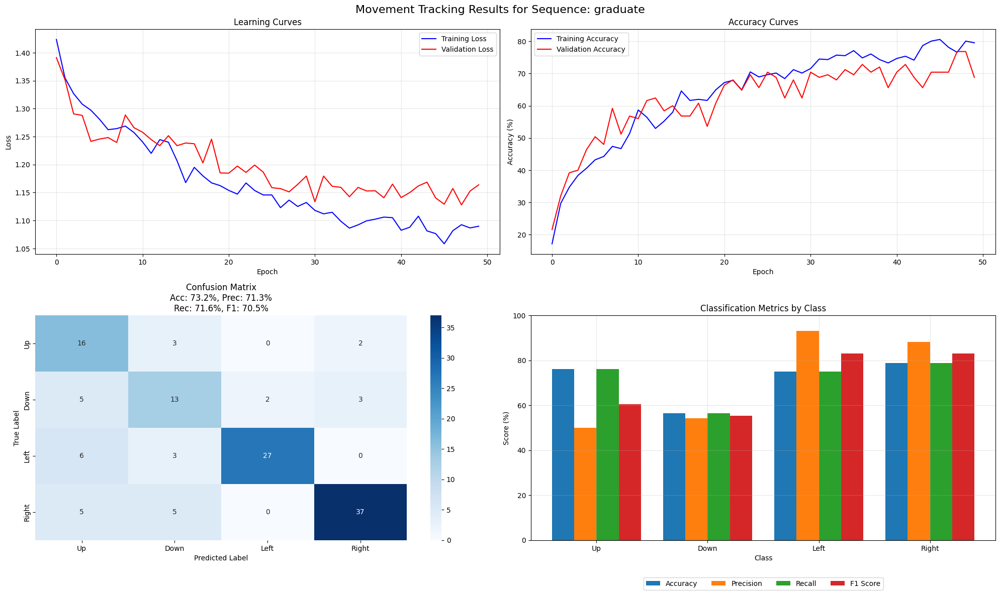

Sequence graduate completed with accuracy: 73.23%

[26/60] Processing sequence: gymnastics1
Processed groundtruth for gymnastics1
Processed images for gymnastics1
Cleaned up temporary files for gymnastics1
max 1.0
Loaded 566 frames and 567 groundtruth entries
Created 561 mini-videos of 5 frames each
Label distribution:
  Up: 87 (15.5%)
  Down: 188 (33.5%)
  Left: 135 (24.1%)
  Right: 151 (26.9%)
Dataset split: 392 train, 84 val, 85 test
Created SNN model
Training on cpu
Dataset sizes - Train: 392, Val: 84, Test: 85


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4065, Train Acc: 17.97%, Val Loss: 1.4367, Val Acc: 33.33%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2802, Train Acc: 47.14%, Val Loss: 1.2900, Val Acc: 44.05%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.1888, Train Acc: 58.85%, Val Loss: 1.2511, Val Acc: 53.57%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.1068, Train Acc: 67.71%, Val Loss: 1.1973, Val Acc: 55.95%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.0738, Train Acc: 73.70%, Val Loss: 1.1325, Val Acc: 70.24%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.0240, Train Acc: 84.64%, Val Loss: 1.1590, Val Acc: 63.10%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.0245, Train Acc: 84.90%, Val Loss: 1.1268, Val Acc: 70.24%, LR: 0.070000
Epoch 35/50 - Train Loss: 0.9983, Train Acc: 86.46%, Val Loss: 1.1341, Val Acc: 72.62%, LR: 0.070000
Epoch 40/50 - Train Loss: 0.9943, Train Acc: 89.84%, Val Loss: 1.1225, Val Acc: 72.62%, LR: 0.070000
Epoch 45/50 - Train Loss: 0.9872, Train Acc: 90.89%, Val Loss: 1.1290, Val Acc: 73.81%, LR: 0

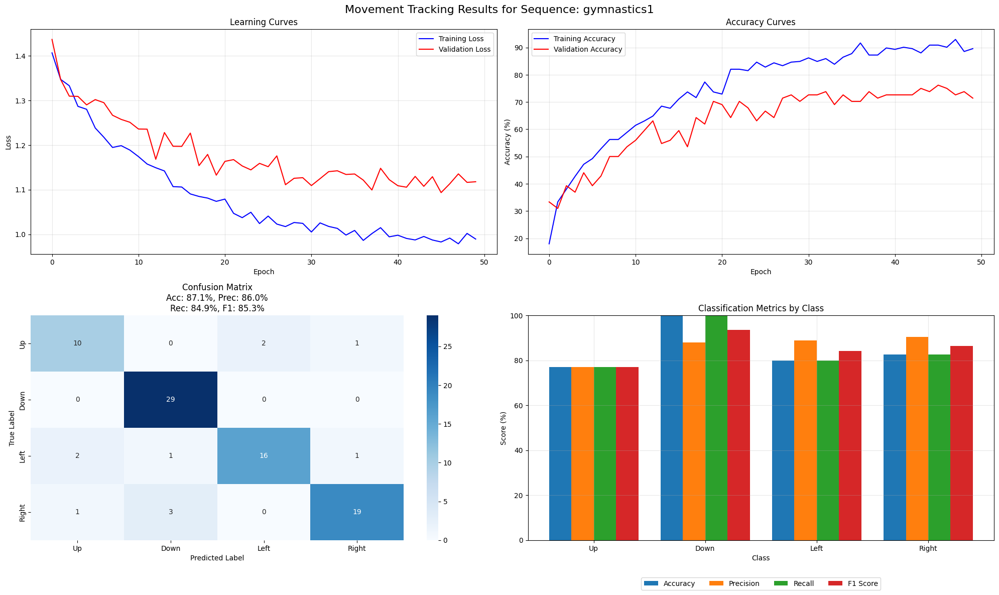

Sequence gymnastics1 completed with accuracy: 87.06%

[27/60] Processing sequence: gymnastics2
Processed groundtruth for gymnastics2
Processed images for gymnastics2
Cleaned up temporary files for gymnastics2
max 0.9531819224357605
Loaded 239 frames and 240 groundtruth entries
Created 234 mini-videos of 5 frames each
Label distribution:
  Up: 59 (25.2%)
  Down: 58 (24.8%)
  Left: 42 (17.9%)
  Right: 75 (32.1%)
Dataset split: 163 train, 35 val, 36 test
Created SNN model
Training on cpu
Dataset sizes - Train: 163, Val: 35, Test: 36


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4009, Train Acc: 25.00%, Val Loss: 1.4403, Val Acc: 25.71%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2779, Train Acc: 53.12%, Val Loss: 1.3258, Val Acc: 37.14%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2778, Train Acc: 46.25%, Val Loss: 1.2971, Val Acc: 45.71%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2116, Train Acc: 62.50%, Val Loss: 1.2677, Val Acc: 51.43%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1272, Train Acc: 70.00%, Val Loss: 1.2635, Val Acc: 48.57%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1094, Train Acc: 68.12%, Val Loss: 1.2618, Val Acc: 51.43%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.0964, Train Acc: 71.88%, Val Loss: 1.2105, Val Acc: 62.86%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0718, Train Acc: 70.00%, Val Loss: 1.2203, Val Acc: 62.86%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0784, Train Acc: 74.38%, Val Loss: 1.2514, Val Acc: 54.29%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0548, Train Acc: 76.88%, Val Loss: 1.2296, Val Acc: 57.14%, LR: 0

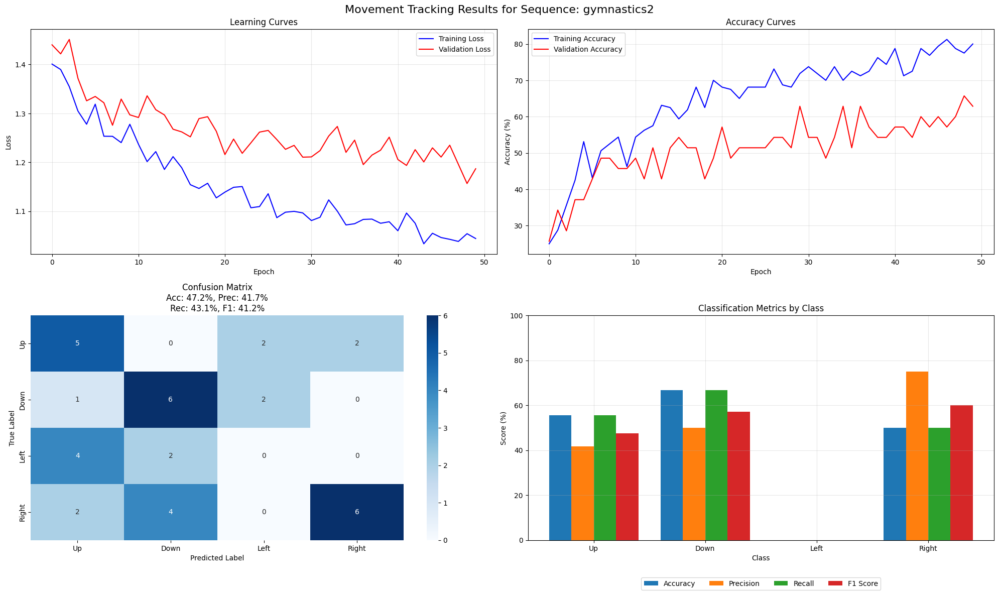

Sequence gymnastics2 completed with accuracy: 47.22%

[28/60] Processing sequence: gymnastics3
Processed groundtruth for gymnastics3
Processed images for gymnastics3
Cleaned up temporary files for gymnastics3
max 0.8365057110786438
Loaded 117 frames and 118 groundtruth entries
Created 112 mini-videos of 5 frames each
Label distribution:
  Up: 34 (30.4%)
  Down: 14 (12.5%)
  Left: 14 (12.5%)
  Right: 50 (44.6%)
Dataset split: 78 train, 16 val, 18 test
Created SNN model
Training on cpu
Dataset sizes - Train: 78, Val: 16, Test: 18
Epoch 1/50 - Train Loss: 1.4643, Train Acc: 31.25%, Val Loss: 1.4782, Val Acc: 31.25%, LR: 0.070000


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 5/50 - Train Loss: 1.4006, Train Acc: 39.06%, Val Loss: 1.3572, Val Acc: 50.00%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2547, Train Acc: 56.25%, Val Loss: 1.1257, Val Acc: 68.75%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2463, Train Acc: 54.69%, Val Loss: 1.1972, Val Acc: 81.25%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2274, Train Acc: 64.06%, Val Loss: 1.0813, Val Acc: 93.75%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1984, Train Acc: 78.12%, Val Loss: 1.0804, Val Acc: 87.50%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1952, Train Acc: 73.44%, Val Loss: 1.0333, Val Acc: 100.00%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.2121, Train Acc: 68.75%, Val Loss: 1.0852, Val Acc: 87.50%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1476, Train Acc: 75.00%, Val Loss: 1.0621, Val Acc: 93.75%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1017, Train Acc: 79.69%, Val Loss: 1.0962, Val Acc: 81.25%, LR: 0.070000
Epoch 50/50 - Train Loss: 1.1390, Train Acc: 76.56%, Val Loss: 1.0483, Val Acc: 93.75%, LR:

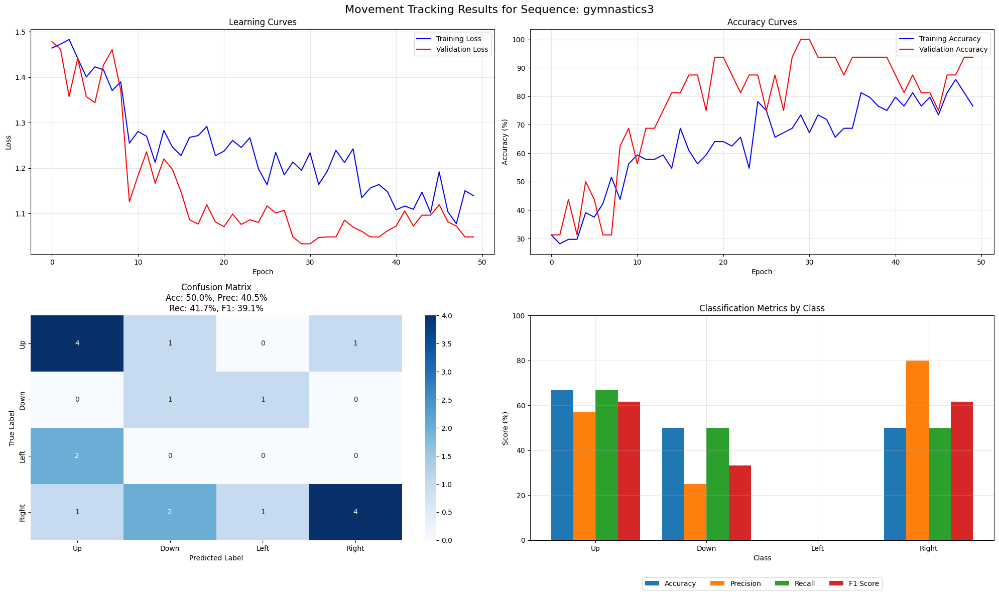

Sequence gymnastics3 completed with accuracy: 50.00%

[29/60] Processing sequence: gymnastics4
Processed groundtruth for gymnastics4
Processed images for gymnastics4
Cleaned up temporary files for gymnastics4
max 1.0
Loaded 464 frames and 465 groundtruth entries
Created 459 mini-videos of 5 frames each
Label distribution:
  Up: 101 (22.0%)
  Down: 74 (16.1%)
  Left: 150 (32.7%)
  Right: 134 (29.2%)
Dataset split: 321 train, 68 val, 70 test
Created SNN model
Training on cpu
Dataset sizes - Train: 321, Val: 68, Test: 70


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4011, Train Acc: 23.44%, Val Loss: 1.3629, Val Acc: 30.88%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.1866, Train Acc: 60.00%, Val Loss: 1.2592, Val Acc: 52.94%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.0638, Train Acc: 78.75%, Val Loss: 1.1863, Val Acc: 64.71%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.0273, Train Acc: 80.31%, Val Loss: 1.1553, Val Acc: 70.59%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.0008, Train Acc: 88.44%, Val Loss: 1.1026, Val Acc: 77.94%, LR: 0.070000
Epoch 25/50 - Train Loss: 0.9873, Train Acc: 89.06%, Val Loss: 1.0649, Val Acc: 80.88%, LR: 0.070000
Epoch 30/50 - Train Loss: 0.9825, Train Acc: 90.62%, Val Loss: 1.0816, Val Acc: 79.41%, LR: 0.070000
Epoch 35/50 - Train Loss: 0.9746, Train Acc: 91.88%, Val Loss: 1.0385, Val Acc: 83.82%, LR: 0.070000
Epoch 40/50 - Train Loss: 0.9662, Train Acc: 92.81%, Val Loss: 1.0458, Val Acc: 82.35%, LR: 0.070000
Epoch 45/50 - Train Loss: 0.9625, Train Acc: 92.81%, Val Loss: 1.0221, Val Acc: 85.29%, LR: 0

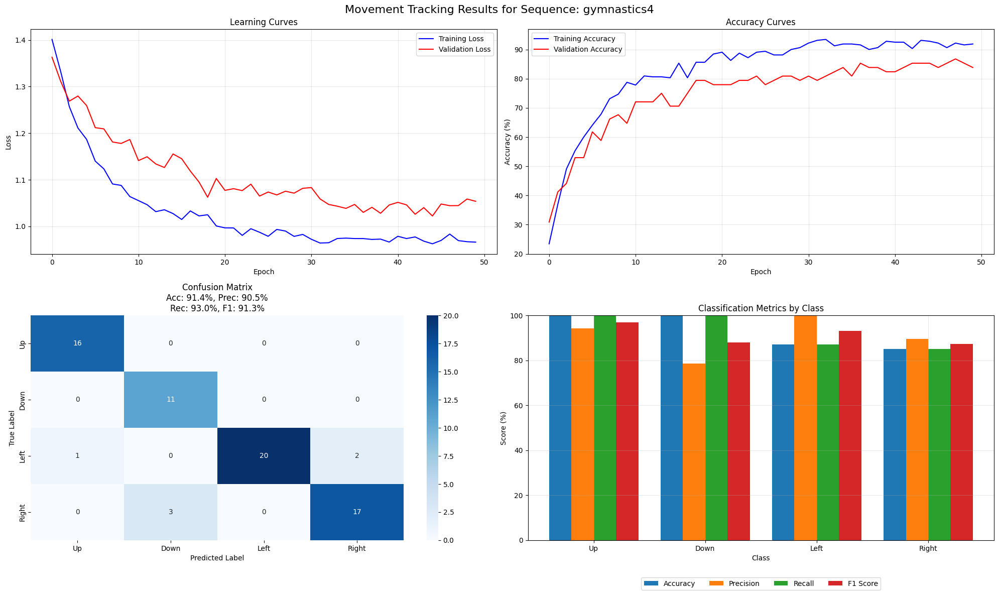

Sequence gymnastics4 completed with accuracy: 91.43%

[30/60] Processing sequence: hand
Processed groundtruth for hand
Processed images for hand
Cleaned up temporary files for hand
max 0.9444281458854675
Loaded 266 frames and 267 groundtruth entries
Created 261 mini-videos of 5 frames each
Label distribution:
  Up: 35 (13.4%)
  Down: 32 (12.3%)
  Left: 103 (39.5%)
  Right: 91 (34.9%)
Dataset split: 182 train, 39 val, 40 test
Created SNN model
Training on cpu
Dataset sizes - Train: 182, Val: 39, Test: 40


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4830, Train Acc: 12.50%, Val Loss: 1.5181, Val Acc: 20.51%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3287, Train Acc: 33.52%, Val Loss: 1.3328, Val Acc: 41.03%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2418, Train Acc: 46.02%, Val Loss: 1.2683, Val Acc: 48.72%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2118, Train Acc: 56.82%, Val Loss: 1.2466, Val Acc: 56.41%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2039, Train Acc: 58.52%, Val Loss: 1.2154, Val Acc: 71.79%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1652, Train Acc: 69.32%, Val Loss: 1.1903, Val Acc: 71.79%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1631, Train Acc: 67.05%, Val Loss: 1.2291, Val Acc: 58.97%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1482, Train Acc: 69.89%, Val Loss: 1.1813, Val Acc: 69.23%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1191, Train Acc: 80.68%, Val Loss: 1.1770, Val Acc: 74.36%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0913, Train Acc: 81.25%, Val Loss: 1.1448, Val Acc: 76.92%, LR: 0

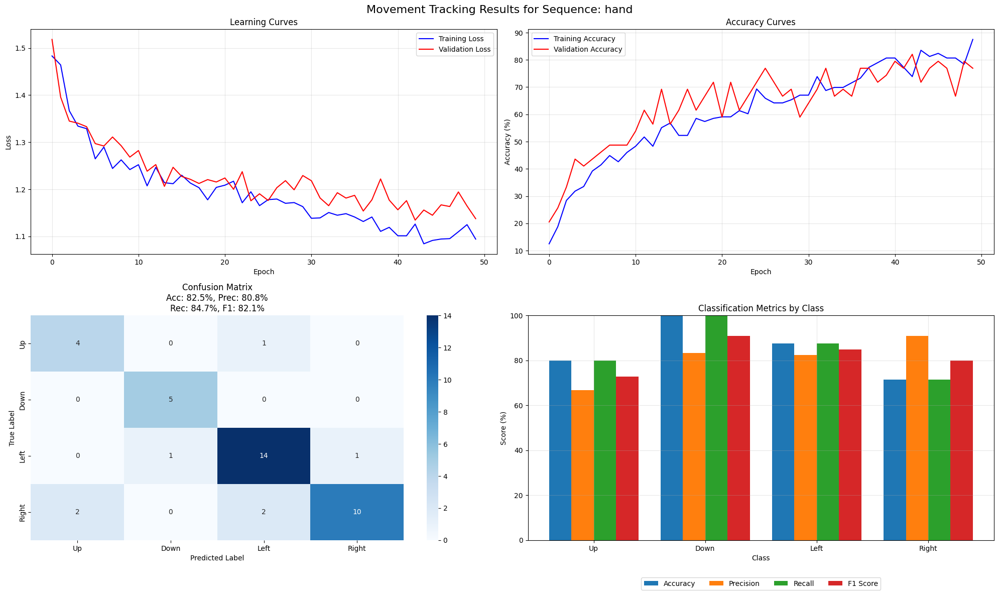

Sequence hand completed with accuracy: 82.50%

[31/60] Processing sequence: handball1
Processed groundtruth for handball1
Processed images for handball1
Cleaned up temporary files for handball1
max 0.9106208086013794
Loaded 376 frames and 377 groundtruth entries
Created 371 mini-videos of 5 frames each
Label distribution:
  Up: 62 (16.7%)
  Down: 1 (0.3%)
  Left: 216 (58.2%)
  Right: 92 (24.8%)
Error training/evaluating sequence handball1: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.. Skipping.

[32/60] Processing sequence: handball2
Processed groundtruth for handball2
Processed images for handball2
Cleaned up temporary files for handball2
max 0.9935484528541565
Loaded 401 frames and 402 groundtruth entries
Created 396 mini-videos of 5 frames each
Label distribution:
  Up: 9 (2.3%)
  Down: 15 (3.8%)
  Left: 201 (50.8%)
  Right: 171 (43.2%)
Dataset split: 277 train, 59 val, 60 test
Created SNN model

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 2.9074, Train Acc: 2.21%, Val Loss: 2.4123, Val Acc: 10.17%, LR: 0.070000
Epoch 5/50 - Train Loss: 2.7191, Train Acc: 21.32%, Val Loss: 2.3293, Val Acc: 23.73%, LR: 0.070000
Epoch 10/50 - Train Loss: 2.6156, Train Acc: 8.82%, Val Loss: 2.2695, Val Acc: 13.56%, LR: 0.070000
Epoch 15/50 - Train Loss: 2.6703, Train Acc: 13.24%, Val Loss: 2.2308, Val Acc: 10.17%, LR: 0.070000
Epoch 20/50 - Train Loss: 2.5649, Train Acc: 12.13%, Val Loss: 2.2253, Val Acc: 8.47%, LR: 0.070000
Epoch 25/50 - Train Loss: 2.3814, Train Acc: 9.56%, Val Loss: 2.2010, Val Acc: 8.47%, LR: 0.070000
Epoch 30/50 - Train Loss: 2.5742, Train Acc: 13.60%, Val Loss: 2.2293, Val Acc: 10.17%, LR: 0.070000
Epoch 35/50 - Train Loss: 2.4345, Train Acc: 7.35%, Val Loss: 2.1811, Val Acc: 6.78%, LR: 0.070000
Epoch 40/50 - Train Loss: 2.3599, Train Acc: 7.35%, Val Loss: 2.1722, Val Acc: 6.78%, LR: 0.070000
Epoch 45/50 - Train Loss: 2.4488, Train Acc: 15.81%, Val Loss: 2.1699, Val Acc: 15.25%, LR: 0.070000
E

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


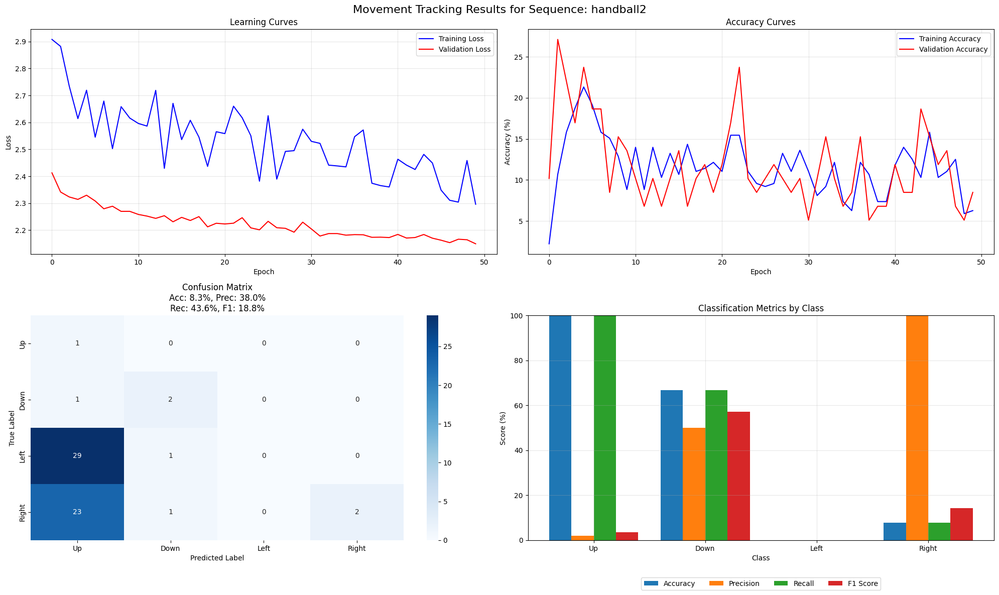

Sequence handball2 completed with accuracy: 8.33%

[33/60] Processing sequence: helicopter
Processed groundtruth for helicopter
Processed images for helicopter
Cleaned up temporary files for helicopter
max 0.915873110294342
Loaded 707 frames and 708 groundtruth entries
Created 702 mini-videos of 5 frames each
Label distribution:
  Up: 174 (24.8%)
  Down: 139 (19.8%)
  Left: 197 (28.1%)
  Right: 192 (27.4%)
Dataset split: 491 train, 105 val, 106 test
Created SNN model
Training on cpu
Dataset sizes - Train: 491, Val: 105, Test: 106


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.3801, Train Acc: 27.08%, Val Loss: 1.3577, Val Acc: 31.43%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2243, Train Acc: 50.00%, Val Loss: 1.2751, Val Acc: 43.81%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.1377, Train Acc: 64.79%, Val Loss: 1.2426, Val Acc: 50.48%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.0648, Train Acc: 75.62%, Val Loss: 1.1952, Val Acc: 55.24%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.0472, Train Acc: 76.67%, Val Loss: 1.1746, Val Acc: 60.00%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.0042, Train Acc: 83.96%, Val Loss: 1.1728, Val Acc: 61.90%, LR: 0.070000
Epoch 30/50 - Train Loss: 0.9816, Train Acc: 86.67%, Val Loss: 1.1511, Val Acc: 64.76%, LR: 0.070000
Epoch 35/50 - Train Loss: 0.9775, Train Acc: 86.67%, Val Loss: 1.1360, Val Acc: 66.67%, LR: 0.070000
Epoch 40/50 - Train Loss: 0.9666, Train Acc: 88.33%, Val Loss: 1.1392, Val Acc: 68.57%, LR: 0.070000
Epoch 45/50 - Train Loss: 0.9780, Train Acc: 87.92%, Val Loss: 1.1317, Val Acc: 66.67%, LR: 0

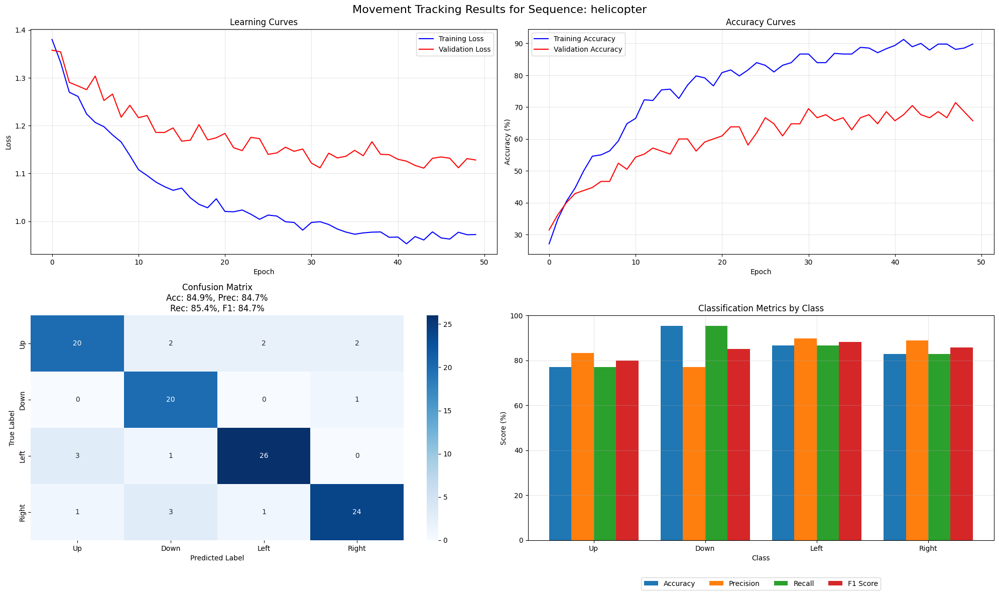

Sequence helicopter completed with accuracy: 84.91%

[34/60] Processing sequence: iceskater1
Processed groundtruth for iceskater1
Processed images for iceskater1
Cleaned up temporary files for iceskater1
max 0.9049999713897705
Loaded 660 frames and 661 groundtruth entries
Created 655 mini-videos of 5 frames each
Label distribution:
  Up: 77 (11.8%)
  Down: 110 (16.8%)
  Left: 170 (26.0%)
  Right: 298 (45.5%)
Dataset split: 458 train, 98 val, 99 test
Created SNN model
Training on cpu
Dataset sizes - Train: 458, Val: 98, Test: 99


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4573, Train Acc: 13.17%, Val Loss: 1.4697, Val Acc: 16.33%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3413, Train Acc: 41.74%, Val Loss: 1.3356, Val Acc: 33.67%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2830, Train Acc: 50.22%, Val Loss: 1.3346, Val Acc: 46.94%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2054, Train Acc: 62.50%, Val Loss: 1.2808, Val Acc: 51.02%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1732, Train Acc: 69.42%, Val Loss: 1.2483, Val Acc: 66.33%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1150, Train Acc: 76.12%, Val Loss: 1.1810, Val Acc: 73.47%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1191, Train Acc: 73.66%, Val Loss: 1.1415, Val Acc: 79.59%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0898, Train Acc: 83.48%, Val Loss: 1.1683, Val Acc: 74.49%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0802, Train Acc: 80.58%, Val Loss: 1.1700, Val Acc: 78.57%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0636, Train Acc: 83.48%, Val Loss: 1.1333, Val Acc: 79.59%, LR: 0

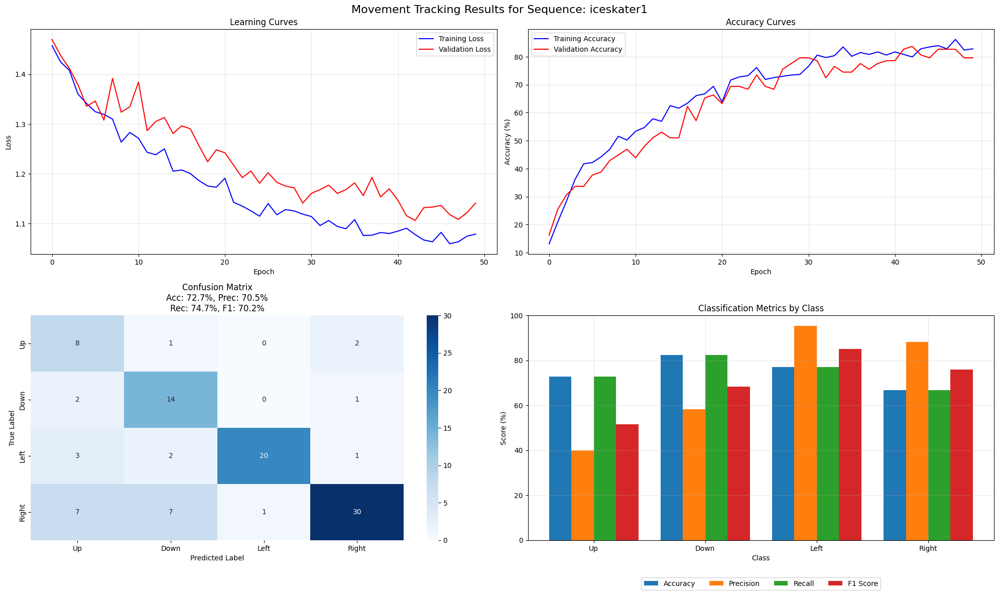

Sequence iceskater1 completed with accuracy: 72.73%

[35/60] Processing sequence: iceskater2
Processed groundtruth for iceskater2
Processed images for iceskater2
Cleaned up temporary files for iceskater2
max 0.848183274269104
Loaded 706 frames and 707 groundtruth entries
Created 701 mini-videos of 5 frames each
Label distribution:
  Up: 81 (11.6%)
  Down: 83 (11.8%)
  Left: 290 (41.4%)
  Right: 247 (35.2%)
Dataset split: 490 train, 105 val, 106 test
Created SNN model
Training on cpu
Dataset sizes - Train: 490, Val: 105, Test: 106


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.5068, Train Acc: 12.08%, Val Loss: 1.3964, Val Acc: 29.52%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3151, Train Acc: 48.33%, Val Loss: 1.2942, Val Acc: 42.86%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2179, Train Acc: 67.92%, Val Loss: 1.2445, Val Acc: 70.48%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.1850, Train Acc: 70.62%, Val Loss: 1.2176, Val Acc: 68.57%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1659, Train Acc: 77.50%, Val Loss: 1.1669, Val Acc: 69.52%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1420, Train Acc: 80.21%, Val Loss: 1.1791, Val Acc: 78.10%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1115, Train Acc: 84.58%, Val Loss: 1.1686, Val Acc: 81.90%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1164, Train Acc: 87.08%, Val Loss: 1.1476, Val Acc: 82.86%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1118, Train Acc: 86.04%, Val Loss: 1.1450, Val Acc: 82.86%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0974, Train Acc: 88.96%, Val Loss: 1.1500, Val Acc: 81.90%, LR: 0

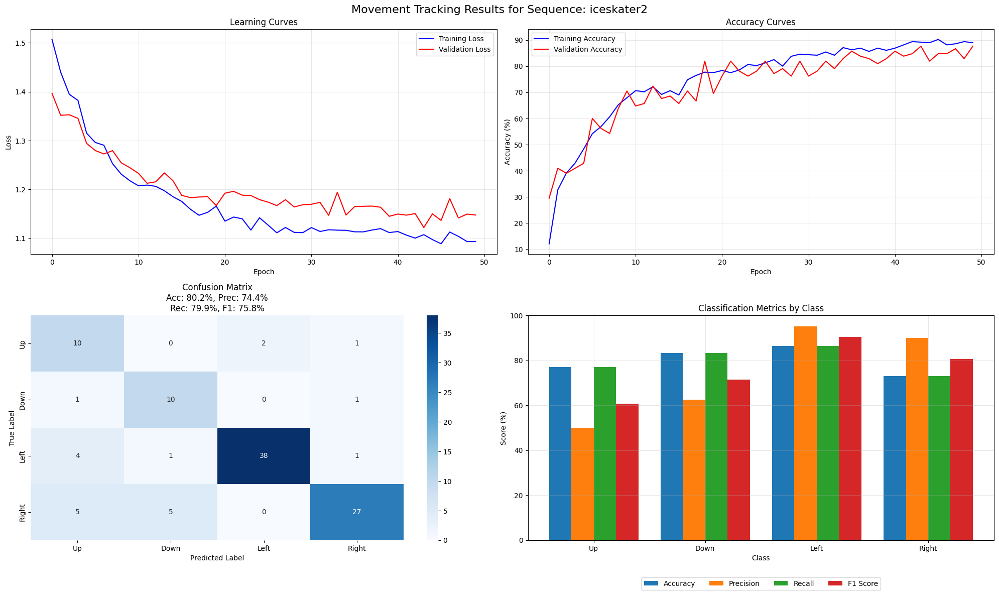

Sequence iceskater2 completed with accuracy: 80.19%

[36/60] Processing sequence: leaves
Processed groundtruth for leaves
Processed images for leaves
Cleaned up temporary files for leaves
max 0.8531915545463562
Loaded 62 frames and 63 groundtruth entries
Created 57 mini-videos of 5 frames each
Label distribution:
  Up: 8 (14.0%)
  Down: 1 (1.8%)
  Left: 46 (80.7%)
  Right: 2 (3.5%)
Error training/evaluating sequence leaves: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.. Skipping.

[37/60] Processing sequence: marching
Processed groundtruth for marching
Processed images for marching
Cleaned up temporary files for marching
max 0.876470685005188
Loaded 200 frames and 201 groundtruth entries
Created 195 mini-videos of 5 frames each
Label distribution:
  Up: 4 (2.1%)
  Down: 18 (9.2%)
  Left: 63 (32.3%)
  Right: 110 (56.4%)
Error training/evaluating sequence marching: The least populated class in y has o

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 5/50 - Train Loss: 1.3677, Train Acc: 31.25%, Val Loss: 1.4526, Val Acc: 21.43%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.3261, Train Acc: 39.06%, Val Loss: 1.2831, Val Acc: 57.14%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2670, Train Acc: 45.31%, Val Loss: 1.3477, Val Acc: 42.86%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2768, Train Acc: 48.44%, Val Loss: 1.3101, Val Acc: 57.14%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2258, Train Acc: 56.25%, Val Loss: 1.2134, Val Acc: 64.29%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1593, Train Acc: 59.38%, Val Loss: 1.2600, Val Acc: 64.29%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1478, Train Acc: 62.50%, Val Loss: 1.1768, Val Acc: 64.29%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1436, Train Acc: 65.62%, Val Loss: 1.2049, Val Acc: 64.29%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1511, Train Acc: 64.06%, Val Loss: 1.2234, Val Acc: 64.29%, LR: 0.052500
Epoch 50/50 - Train Loss: 1.0764, Train Acc: 78.12%, Val Loss: 1.2267, Val Acc: 57.14%, LR: 

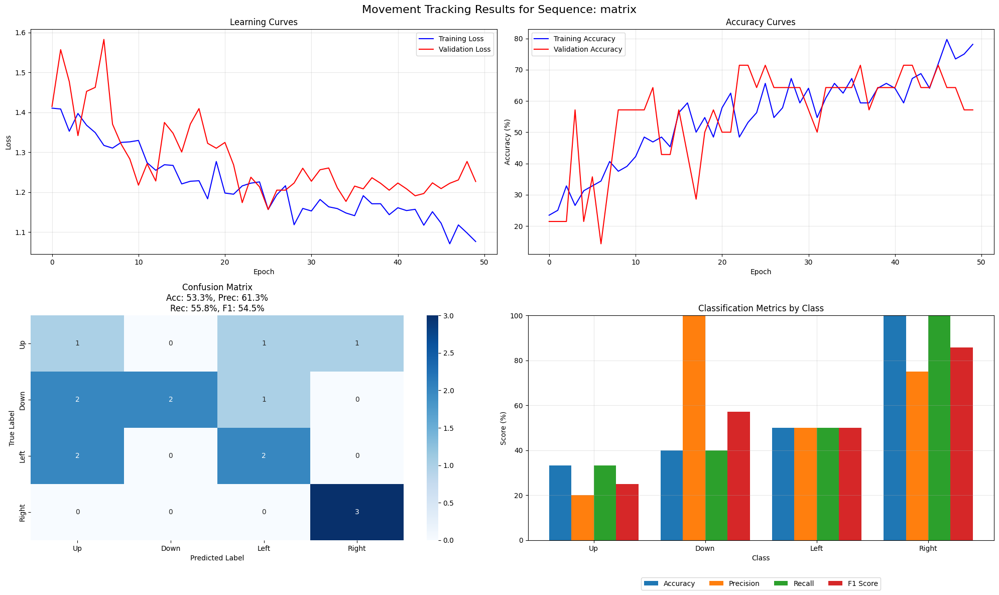

Sequence matrix completed with accuracy: 53.33%

[39/60] Processing sequence: motocross1
Processed groundtruth for motocross1
Processed images for motocross1
Cleaned up temporary files for motocross1
max 0.8610430955886841
Loaded 163 frames and 164 groundtruth entries
Created 158 mini-videos of 5 frames each
Label distribution:
  Up: 19 (12.0%)
  Down: 55 (34.8%)
  Left: 43 (27.2%)
  Right: 41 (25.9%)
Dataset split: 110 train, 23 val, 25 test
Created SNN model
Training on cpu
Dataset sizes - Train: 110, Val: 23, Test: 25


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4387, Train Acc: 11.46%, Val Loss: 1.4348, Val Acc: 13.04%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2096, Train Acc: 50.00%, Val Loss: 1.2057, Val Acc: 52.17%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.1863, Train Acc: 66.67%, Val Loss: 1.2328, Val Acc: 60.87%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.1454, Train Acc: 69.79%, Val Loss: 1.1181, Val Acc: 65.22%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.0594, Train Acc: 79.17%, Val Loss: 1.0976, Val Acc: 69.57%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.0391, Train Acc: 84.38%, Val Loss: 1.0672, Val Acc: 78.26%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.0565, Train Acc: 83.33%, Val Loss: 1.0436, Val Acc: 86.96%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0264, Train Acc: 85.42%, Val Loss: 1.0487, Val Acc: 82.61%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0082, Train Acc: 91.67%, Val Loss: 1.0308, Val Acc: 82.61%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0323, Train Acc: 84.38%, Val Loss: 1.0148, Val Acc: 86.96%, LR: 0

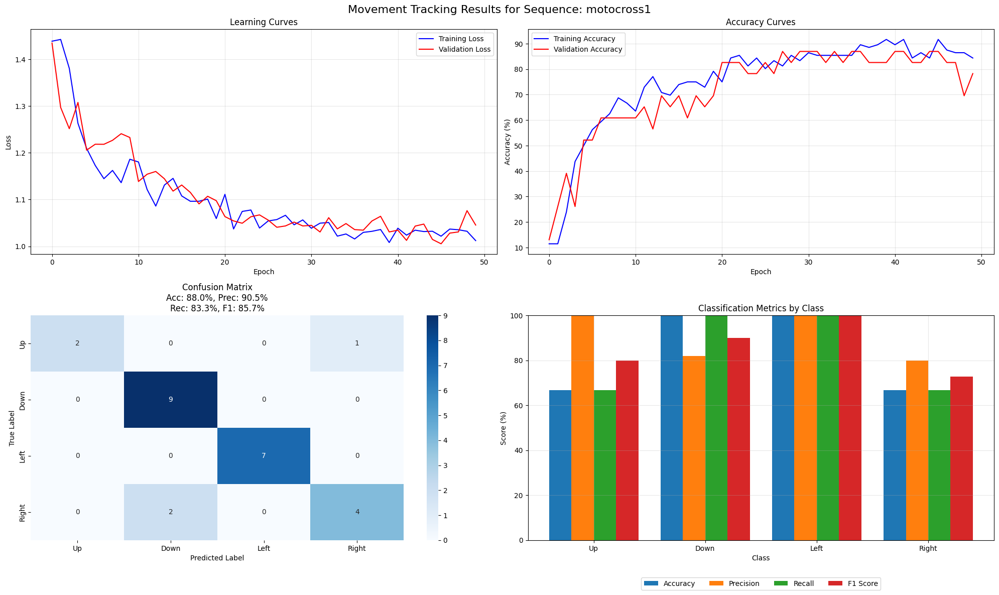

Sequence motocross1 completed with accuracy: 88.00%

[40/60] Processing sequence: motocross2
Processed groundtruth for motocross2
Processed images for motocross2
Cleaned up temporary files for motocross2
max 0.7589663863182068
Loaded 60 frames and 61 groundtruth entries
Created 55 mini-videos of 5 frames each
Label distribution:
  Up: 10 (18.2%)
  Down: 14 (25.5%)
  Left: 13 (23.6%)
  Right: 18 (32.7%)
Dataset split: 38 train, 8 val, 9 test
Created SNN model
Training on cpu
Dataset sizes - Train: 38, Val: 8, Test: 9
Consider reducing batch size or using different train/val split ratios.
Epoch 1/50 - Train Loss: 1.3928, Train Acc: 21.88%, Val Loss: 1.4065, Val Acc: 12.50%, LR: 0.070000


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 5/50 - Train Loss: 1.3689, Train Acc: 25.00%, Val Loss: 1.1642, Val Acc: 62.50%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2958, Train Acc: 50.00%, Val Loss: 1.1206, Val Acc: 50.00%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2092, Train Acc: 53.12%, Val Loss: 1.0550, Val Acc: 50.00%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1661, Train Acc: 56.25%, Val Loss: 1.0281, Val Acc: 62.50%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1336, Train Acc: 62.50%, Val Loss: 1.0281, Val Acc: 62.50%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.0931, Train Acc: 62.50%, Val Loss: 1.0677, Val Acc: 62.50%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1104, Train Acc: 65.62%, Val Loss: 1.0677, Val Acc: 62.50%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1404, Train Acc: 65.62%, Val Loss: 1.0677, Val Acc: 62.50%, LR: 0.052500
Epoch 45/50 - Train Loss: 1.0408, Train Acc: 75.00%, Val Loss: 1.1753, Val Acc: 50.00%, LR: 0.052500
Epoch 50/50 - Train Loss: 1.1067, Train Acc: 71.88%, Val Loss: 1.0677, Val Acc: 62.50%, LR: 

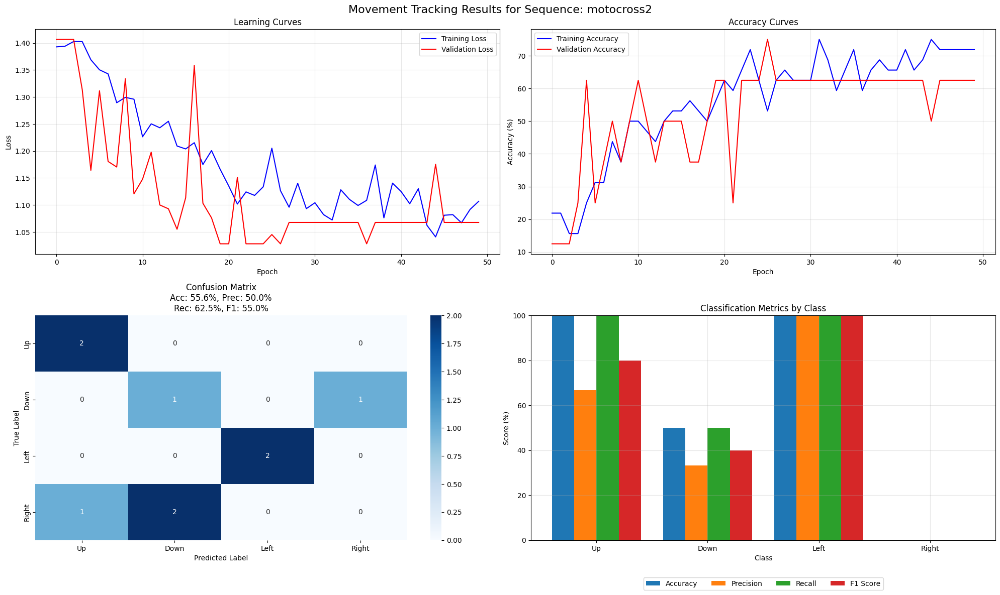

Sequence motocross2 completed with accuracy: 55.56%

[41/60] Processing sequence: nature
Processed groundtruth for nature
Processed images for nature
Cleaned up temporary files for nature
max 1.0
Loaded 998 frames and 999 groundtruth entries
Created 993 mini-videos of 5 frames each
Label distribution:
  Up: 123 (12.4%)
  Down: 127 (12.8%)
  Left: 366 (36.9%)
  Right: 377 (38.0%)
Dataset split: 695 train, 148 val, 150 test
Created SNN model
Training on cpu
Dataset sizes - Train: 695, Val: 148, Test: 150


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4513, Train Acc: 24.85%, Val Loss: 1.4336, Val Acc: 39.86%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2955, Train Acc: 50.87%, Val Loss: 1.3519, Val Acc: 46.62%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2109, Train Acc: 64.97%, Val Loss: 1.2437, Val Acc: 58.11%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.1567, Train Acc: 71.37%, Val Loss: 1.2159, Val Acc: 69.59%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1348, Train Acc: 78.05%, Val Loss: 1.1589, Val Acc: 80.41%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1114, Train Acc: 81.54%, Val Loss: 1.1530, Val Acc: 82.43%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1108, Train Acc: 84.30%, Val Loss: 1.1458, Val Acc: 82.43%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0865, Train Acc: 87.21%, Val Loss: 1.1337, Val Acc: 83.11%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0749, Train Acc: 89.97%, Val Loss: 1.1587, Val Acc: 80.41%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0723, Train Acc: 90.12%, Val Loss: 1.1315, Val Acc: 83.78%, LR: 0

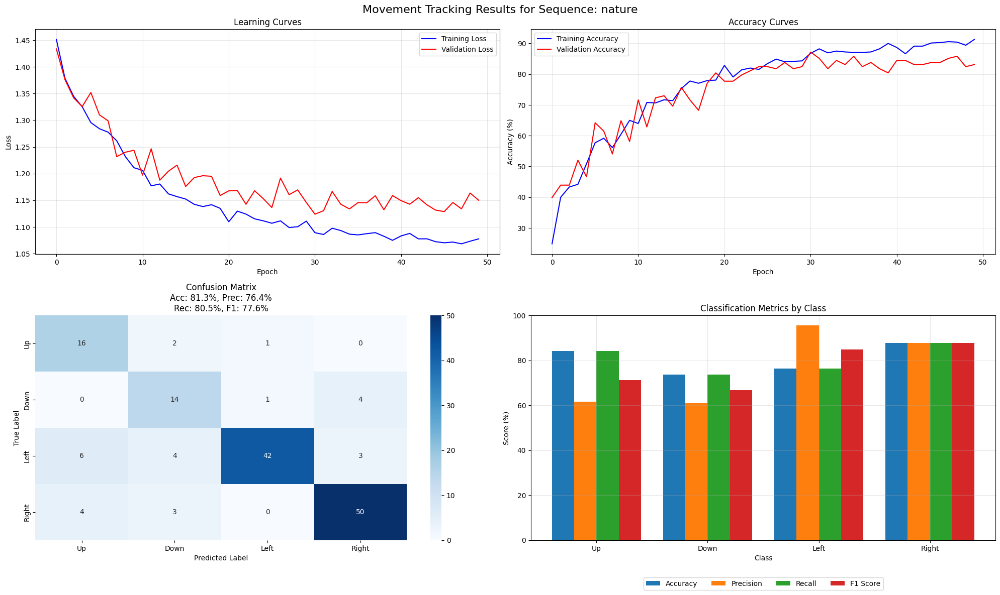

Sequence nature completed with accuracy: 81.33%

[42/60] Processing sequence: octopus
Processed groundtruth for octopus
Processed images for octopus
Cleaned up temporary files for octopus
max 0.9739130735397339
Loaded 290 frames and 291 groundtruth entries
Created 285 mini-videos of 5 frames each
Label distribution:
  Up: 47 (16.5%)
  Down: 93 (32.6%)
  Left: 73 (25.6%)
  Right: 72 (25.3%)
Dataset split: 199 train, 42 val, 44 test
Created SNN model
Training on cpu
Dataset sizes - Train: 199, Val: 42, Test: 44


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4061, Train Acc: 16.67%, Val Loss: 1.4085, Val Acc: 33.33%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2636, Train Acc: 35.42%, Val Loss: 1.2277, Val Acc: 45.24%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.1796, Train Acc: 54.17%, Val Loss: 1.1610, Val Acc: 61.90%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.1050, Train Acc: 68.75%, Val Loss: 1.0973, Val Acc: 71.43%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.0601, Train Acc: 76.56%, Val Loss: 1.0956, Val Acc: 76.19%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.0414, Train Acc: 79.69%, Val Loss: 1.0905, Val Acc: 78.57%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.0280, Train Acc: 84.90%, Val Loss: 1.0967, Val Acc: 78.57%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0078, Train Acc: 86.46%, Val Loss: 1.1107, Val Acc: 76.19%, LR: 0.070000
Epoch 40/50 - Train Loss: 0.9959, Train Acc: 86.98%, Val Loss: 1.0849, Val Acc: 78.57%, LR: 0.052500
Epoch 45/50 - Train Loss: 0.9895, Train Acc: 87.50%, Val Loss: 1.0813, Val Acc: 76.19%, LR: 0

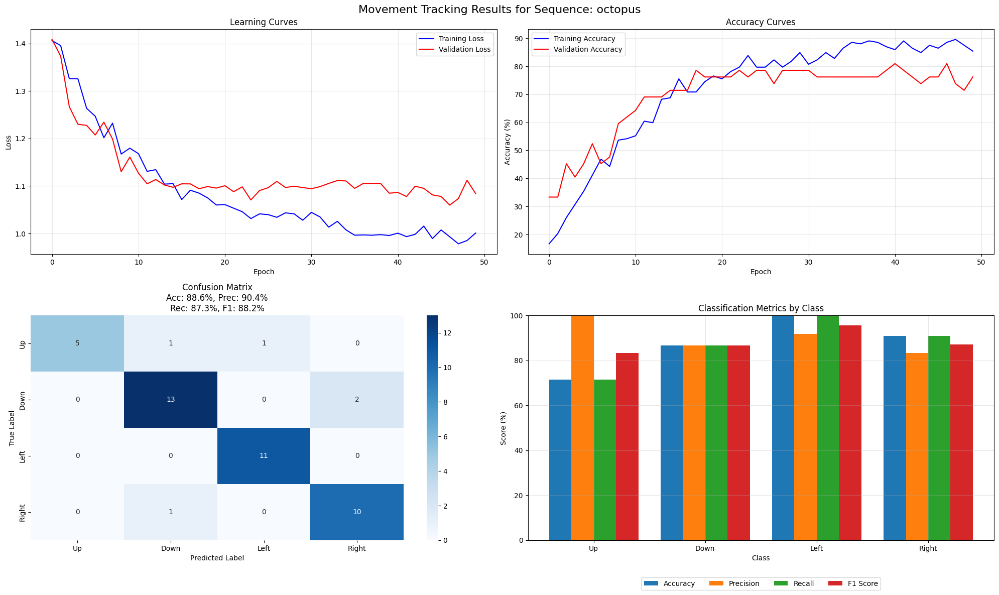

Sequence octopus completed with accuracy: 88.64%

[43/60] Processing sequence: pedestrian1
Processed groundtruth for pedestrian1
Processed images for pedestrian1
Cleaned up temporary files for pedestrian1
max 0.7863155007362366
Loaded 139 frames and 140 groundtruth entries
Created 134 mini-videos of 5 frames each
Label distribution:
  Up: 13 (9.7%)
  Down: 19 (14.2%)
  Left: 41 (30.6%)
  Right: 61 (45.5%)
Dataset split: 93 train, 20 val, 21 test
Created SNN model
Training on cpu
Dataset sizes - Train: 93, Val: 20, Test: 21


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.5310, Train Acc: 10.00%, Val Loss: 1.4998, Val Acc: 10.00%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.4594, Train Acc: 26.25%, Val Loss: 1.5002, Val Acc: 15.00%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.4289, Train Acc: 31.25%, Val Loss: 1.4643, Val Acc: 25.00%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.3763, Train Acc: 37.50%, Val Loss: 1.4197, Val Acc: 30.00%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.3532, Train Acc: 51.25%, Val Loss: 1.3934, Val Acc: 45.00%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2999, Train Acc: 51.25%, Val Loss: 1.4163, Val Acc: 35.00%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.2858, Train Acc: 53.75%, Val Loss: 1.4401, Val Acc: 35.00%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.2271, Train Acc: 61.25%, Val Loss: 1.4418, Val Acc: 40.00%, LR: 0.052500
Epoch 40/50 - Train Loss: 1.1704, Train Acc: 65.00%, Val Loss: 1.4187, Val Acc: 35.00%, LR: 0.052500
Epoch 45/50 - Train Loss: 1.2085, Train Acc: 62.50%, Val Loss: 1.3832, Val Acc: 45.00%, LR: 0

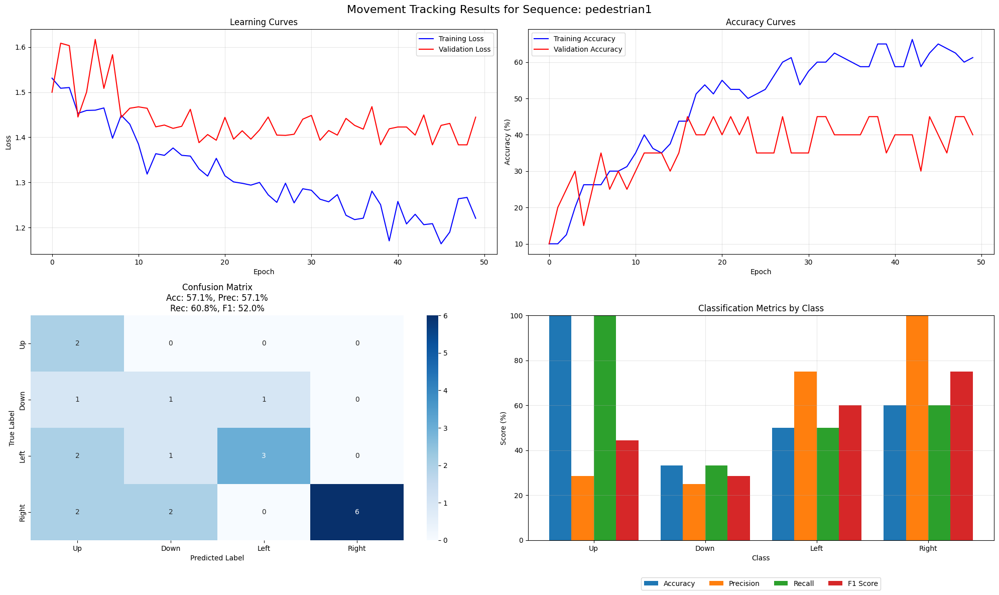

Sequence pedestrian1 completed with accuracy: 57.14%

[44/60] Processing sequence: pedestrian2
Processed groundtruth for pedestrian2
Processed images for pedestrian2
Cleaned up temporary files for pedestrian2
max 0.983492374420166
Loaded 712 frames and 713 groundtruth entries
Created 707 mini-videos of 5 frames each
Label distribution:
  Up: 158 (22.3%)
  Down: 207 (29.3%)
  Left: 171 (24.2%)
  Right: 171 (24.2%)
Dataset split: 494 train, 106 val, 107 test
Created SNN model
Training on cpu
Dataset sizes - Train: 494, Val: 106, Test: 107


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.3777, Train Acc: 24.58%, Val Loss: 1.3406, Val Acc: 31.13%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2472, Train Acc: 49.79%, Val Loss: 1.2400, Val Acc: 50.00%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.1580, Train Acc: 61.04%, Val Loss: 1.1939, Val Acc: 57.55%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.1154, Train Acc: 67.92%, Val Loss: 1.1754, Val Acc: 58.49%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.0935, Train Acc: 71.25%, Val Loss: 1.1517, Val Acc: 62.26%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.0518, Train Acc: 76.88%, Val Loss: 1.1316, Val Acc: 63.21%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.0439, Train Acc: 76.25%, Val Loss: 1.1209, Val Acc: 66.98%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0189, Train Acc: 81.88%, Val Loss: 1.1113, Val Acc: 67.92%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0067, Train Acc: 81.46%, Val Loss: 1.1054, Val Acc: 65.09%, LR: 0.070000
Epoch 45/50 - Train Loss: 0.9916, Train Acc: 83.96%, Val Loss: 1.1168, Val Acc: 66.04%, LR: 0

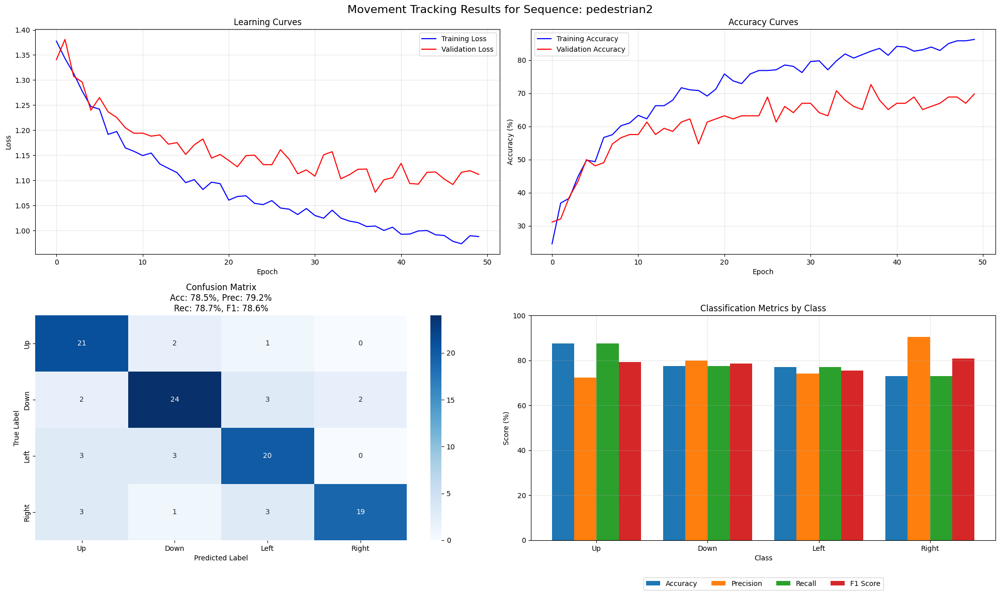

Sequence pedestrian2 completed with accuracy: 78.50%

[45/60] Processing sequence: rabbit
Processed groundtruth for rabbit
Processed images for rabbit
Cleaned up temporary files for rabbit
max 0.9205882549285889
Loaded 157 frames and 158 groundtruth entries
Created 152 mini-videos of 5 frames each
Label distribution:
  Up: 11 (7.2%)
  Down: 45 (29.6%)
  Left: 53 (34.9%)
  Right: 43 (28.3%)
Dataset split: 106 train, 22 val, 24 test
Created SNN model
Training on cpu
Dataset sizes - Train: 106, Val: 22, Test: 24


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.5303, Train Acc: 6.25%, Val Loss: 1.5136, Val Acc: 13.64%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2875, Train Acc: 48.96%, Val Loss: 1.2578, Val Acc: 54.55%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2894, Train Acc: 62.50%, Val Loss: 1.2684, Val Acc: 68.18%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2355, Train Acc: 65.62%, Val Loss: 1.2736, Val Acc: 72.73%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1991, Train Acc: 72.92%, Val Loss: 1.2694, Val Acc: 77.27%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1765, Train Acc: 77.08%, Val Loss: 1.2463, Val Acc: 77.27%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1358, Train Acc: 81.25%, Val Loss: 1.2092, Val Acc: 77.27%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1530, Train Acc: 81.25%, Val Loss: 1.2232, Val Acc: 77.27%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1147, Train Acc: 86.46%, Val Loss: 1.2133, Val Acc: 77.27%, LR: 0.052500
Epoch 45/50 - Train Loss: 1.1507, Train Acc: 84.38%, Val Loss: 1.2495, Val Acc: 77.27%, LR: 0.

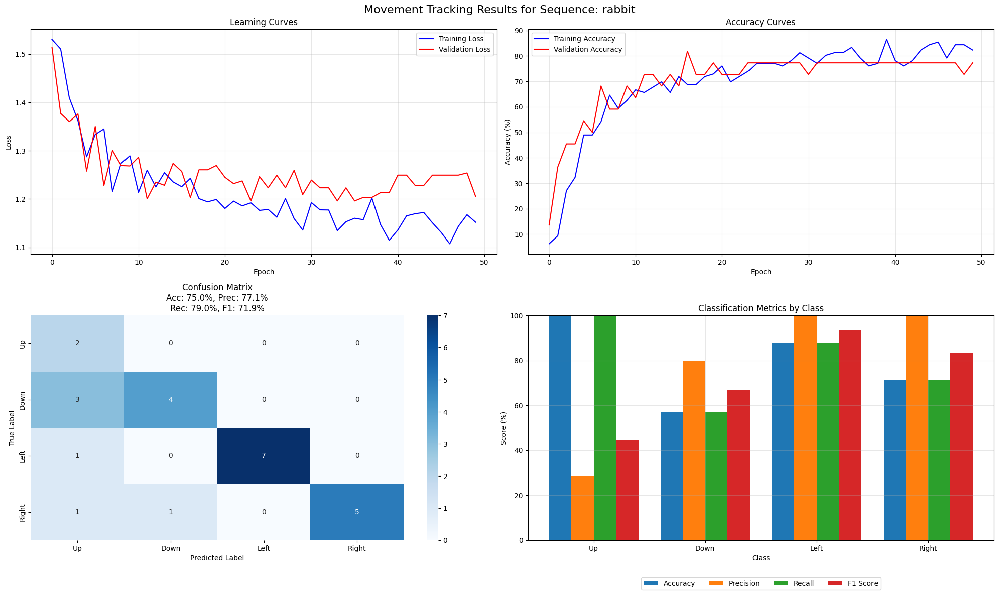

Sequence rabbit completed with accuracy: 75.00%

[46/60] Processing sequence: racing
Processed groundtruth for racing
Processed images for racing
Cleaned up temporary files for racing
max 0.8695652484893799
Loaded 155 frames and 156 groundtruth entries
Created 150 mini-videos of 5 frames each
Label distribution:
  Up: 17 (11.3%)
  Down: 41 (27.3%)
  Left: 54 (36.0%)
  Right: 38 (25.3%)
Dataset split: 104 train, 22 val, 24 test
Created SNN model
Training on cpu
Dataset sizes - Train: 104, Val: 22, Test: 24


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4409, Train Acc: 11.46%, Val Loss: 1.4503, Val Acc: 9.09%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2131, Train Acc: 46.88%, Val Loss: 1.1406, Val Acc: 72.73%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.0741, Train Acc: 76.04%, Val Loss: 1.0974, Val Acc: 77.27%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.0528, Train Acc: 81.25%, Val Loss: 1.0499, Val Acc: 95.45%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.0297, Train Acc: 86.46%, Val Loss: 1.0324, Val Acc: 90.91%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.0359, Train Acc: 89.58%, Val Loss: 1.0499, Val Acc: 95.45%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.0089, Train Acc: 89.58%, Val Loss: 0.9956, Val Acc: 100.00%, LR: 0.070000
Epoch 35/50 - Train Loss: 0.9903, Train Acc: 90.62%, Val Loss: 1.0038, Val Acc: 95.45%, LR: 0.070000
Epoch 40/50 - Train Loss: 0.9967, Train Acc: 88.54%, Val Loss: 1.0038, Val Acc: 95.45%, LR: 0.052500
Epoch 45/50 - Train Loss: 0.9984, Train Acc: 93.75%, Val Loss: 1.0038, Val Acc: 95.45%, LR: 0

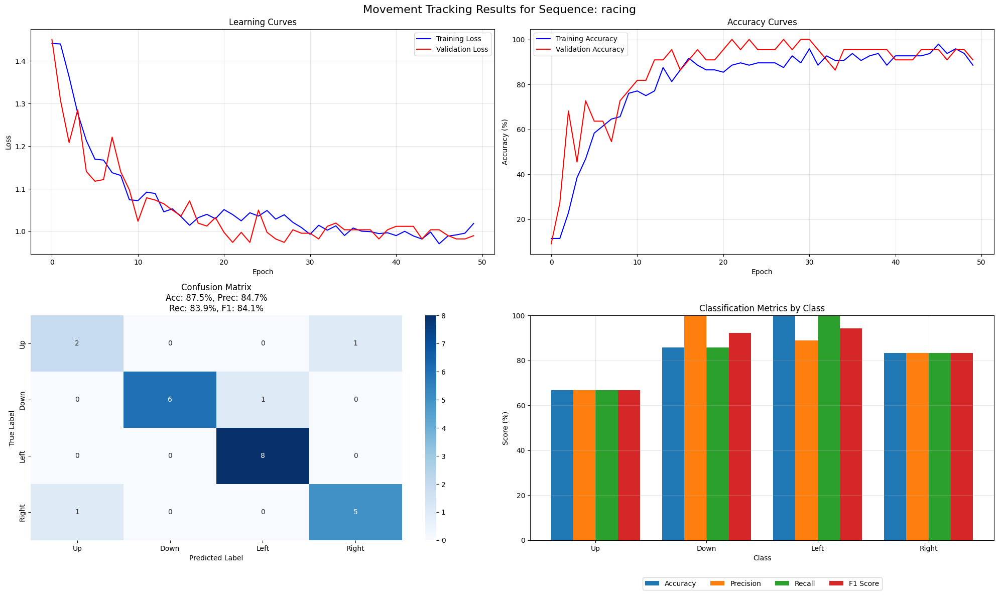

Sequence racing completed with accuracy: 87.50%

[47/60] Processing sequence: road
Processed groundtruth for road
Processed images for road
Cleaned up temporary files for road
max 1.0
Loaded 557 frames and 558 groundtruth entries
Created 552 mini-videos of 5 frames each
Label distribution:
  Up: 85 (15.4%)
  Down: 47 (8.5%)
  Left: 232 (42.0%)
  Right: 188 (34.1%)
Dataset split: 386 train, 82 val, 84 test
Created SNN model
Training on cpu
Dataset sizes - Train: 386, Val: 82, Test: 84


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.5254, Train Acc: 17.97%, Val Loss: 1.5633, Val Acc: 15.85%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3486, Train Acc: 45.57%, Val Loss: 1.4100, Val Acc: 45.12%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2441, Train Acc: 63.28%, Val Loss: 1.2711, Val Acc: 62.20%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.1885, Train Acc: 72.66%, Val Loss: 1.2464, Val Acc: 70.73%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1572, Train Acc: 78.91%, Val Loss: 1.1789, Val Acc: 81.71%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1362, Train Acc: 83.33%, Val Loss: 1.1420, Val Acc: 81.71%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1358, Train Acc: 88.54%, Val Loss: 1.1267, Val Acc: 91.46%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1177, Train Acc: 89.58%, Val Loss: 1.0944, Val Acc: 92.68%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1009, Train Acc: 92.45%, Val Loss: 1.1259, Val Acc: 86.59%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0955, Train Acc: 93.23%, Val Loss: 1.1275, Val Acc: 90.24%, LR: 0

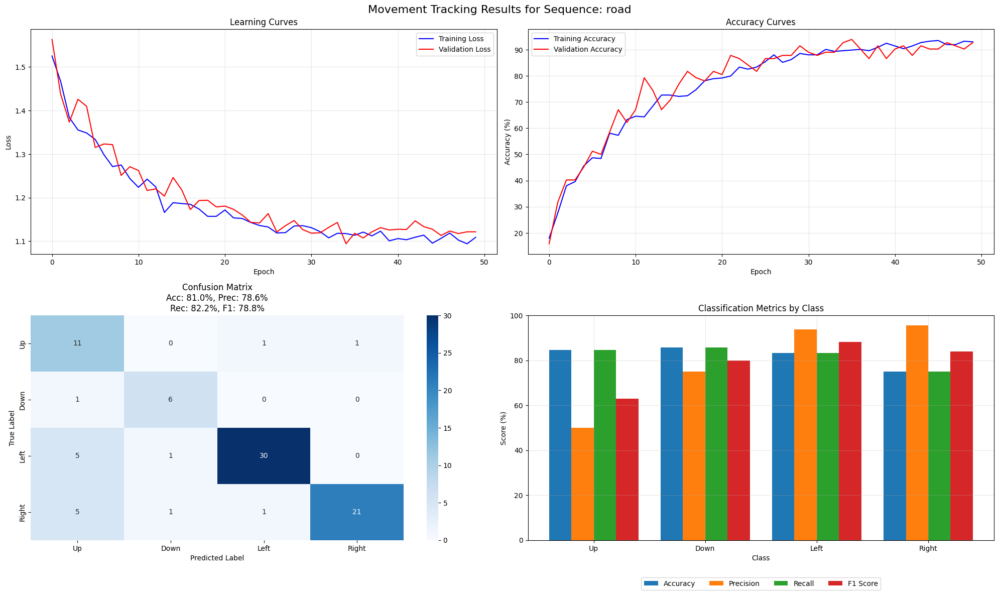

Sequence road completed with accuracy: 80.95%

[48/60] Processing sequence: shaking
Processed groundtruth for shaking
Processed images for shaking
Cleaned up temporary files for shaking
max 0.8944881558418274
Loaded 364 frames and 365 groundtruth entries
Created 359 mini-videos of 5 frames each
Label distribution:
  Up: 125 (34.8%)
  Down: 140 (39.0%)
  Left: 63 (17.5%)
  Right: 31 (8.6%)
Dataset split: 251 train, 53 val, 55 test
Created SNN model
Training on cpu
Dataset sizes - Train: 251, Val: 53, Test: 55


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.5177, Train Acc: 35.42%, Val Loss: 1.5062, Val Acc: 33.96%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3601, Train Acc: 48.33%, Val Loss: 1.3683, Val Acc: 49.06%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2625, Train Acc: 62.08%, Val Loss: 1.3785, Val Acc: 58.49%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2461, Train Acc: 67.92%, Val Loss: 1.3571, Val Acc: 56.60%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2318, Train Acc: 72.50%, Val Loss: 1.3071, Val Acc: 64.15%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2095, Train Acc: 78.75%, Val Loss: 1.2611, Val Acc: 69.81%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1645, Train Acc: 85.42%, Val Loss: 1.2692, Val Acc: 75.47%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1563, Train Acc: 84.17%, Val Loss: 1.1985, Val Acc: 83.02%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1615, Train Acc: 85.00%, Val Loss: 1.2582, Val Acc: 79.25%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1217, Train Acc: 86.25%, Val Loss: 1.2073, Val Acc: 81.13%, LR: 0

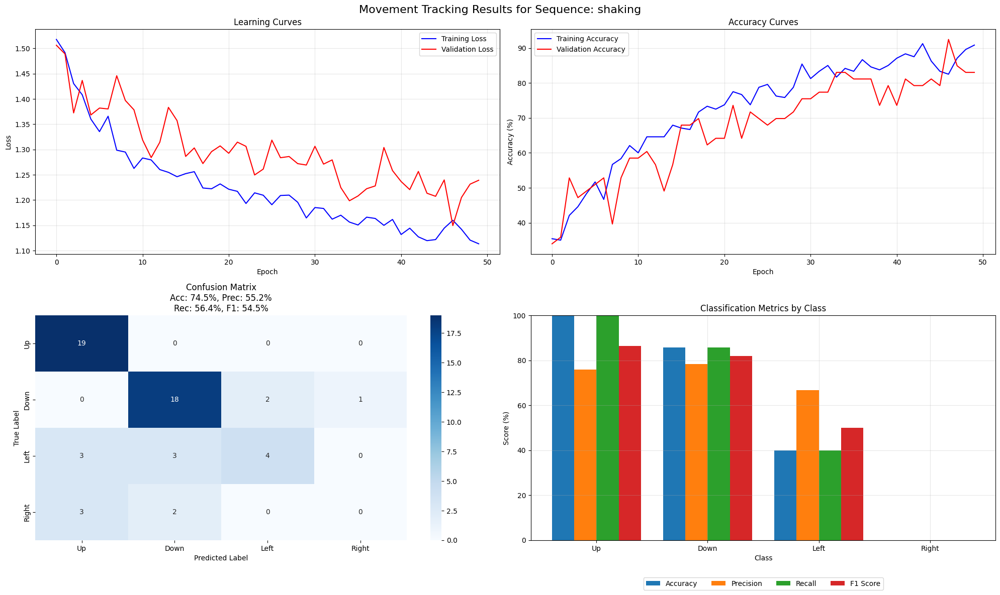

Sequence shaking completed with accuracy: 74.55%

[49/60] Processing sequence: sheep
Processed groundtruth for sheep
Processed images for sheep
Cleaned up temporary files for sheep
max 1.0
Loaded 250 frames and 251 groundtruth entries
Created 245 mini-videos of 5 frames each
Label distribution:
  Up: 14 (5.7%)
  Down: 9 (3.7%)
  Left: 211 (86.1%)
  Right: 11 (4.5%)
Dataset split: 171 train, 36 val, 38 test
Created SNN model
Training on cpu
Dataset sizes - Train: 171, Val: 36, Test: 38


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 2.6296, Train Acc: 5.62%, Val Loss: 3.6487, Val Acc: 5.56%, LR: 0.070000
Epoch 5/50 - Train Loss: 2.2125, Train Acc: 14.38%, Val Loss: 3.5576, Val Acc: 30.56%, LR: 0.070000
Epoch 10/50 - Train Loss: 2.1966, Train Acc: 18.12%, Val Loss: 3.5458, Val Acc: 22.22%, LR: 0.070000
Epoch 15/50 - Train Loss: 2.6096, Train Acc: 17.50%, Val Loss: 3.5204, Val Acc: 13.89%, LR: 0.070000
Epoch 20/50 - Train Loss: 2.6136, Train Acc: 18.75%, Val Loss: 3.4927, Val Acc: 13.89%, LR: 0.070000
Epoch 25/50 - Train Loss: 2.2133, Train Acc: 15.00%, Val Loss: 3.4720, Val Acc: 13.89%, LR: 0.070000
Epoch 30/50 - Train Loss: 2.5432, Train Acc: 18.12%, Val Loss: 3.4917, Val Acc: 13.89%, LR: 0.070000
Epoch 35/50 - Train Loss: 2.2944, Train Acc: 15.62%, Val Loss: 3.4812, Val Acc: 19.44%, LR: 0.070000
Epoch 40/50 - Train Loss: 2.5114, Train Acc: 15.62%, Val Loss: 3.4805, Val Acc: 13.89%, LR: 0.052500
Epoch 45/50 - Train Loss: 2.3182, Train Acc: 15.00%, Val Loss: 3.4980, Val Acc: 13.89%, LR: 0.0

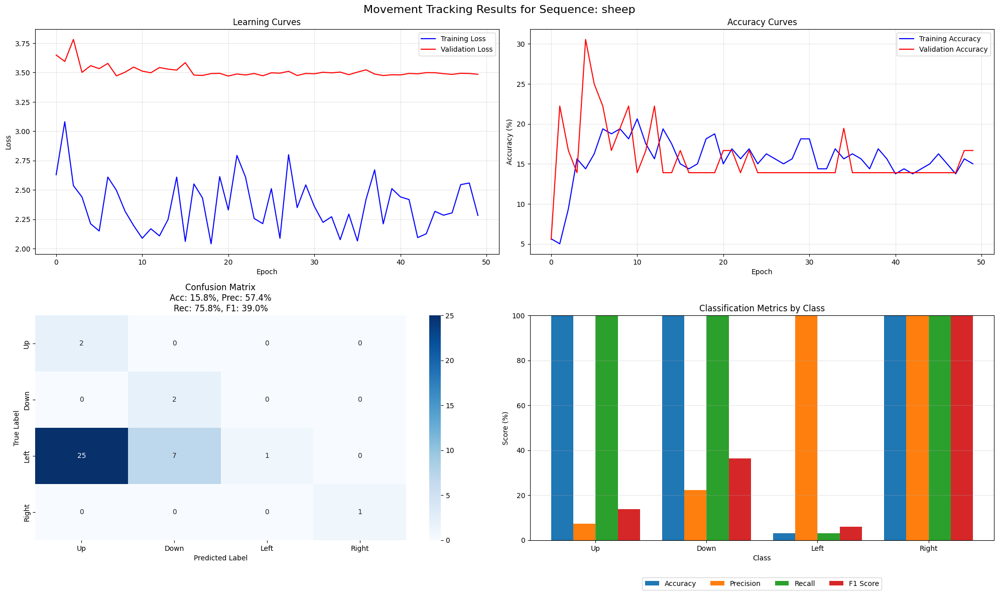

Sequence sheep completed with accuracy: 15.79%

[50/60] Processing sequence: singer1
Processed groundtruth for singer1
Processed images for singer1
Cleaned up temporary files for singer1
max 0.9000865817070007
Loaded 350 frames and 351 groundtruth entries
Created 345 mini-videos of 5 frames each
Label distribution:
  Up: 80 (23.2%)
  Down: 3 (0.9%)
  Left: 24 (7.0%)
  Right: 238 (69.0%)
Error training/evaluating sequence singer1: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.. Skipping.

[51/60] Processing sequence: singer2
Processed groundtruth for singer2
Processed images for singer2
Cleaned up temporary files for singer2
max 0.8925373554229736
Loaded 365 frames and 366 groundtruth entries
Created 360 mini-videos of 5 frames each
Label distribution:
  Up: 54 (15.0%)
  Down: 47 (13.1%)
  Left: 115 (31.9%)
  Right: 144 (40.0%)
Dataset split: 251 train, 54 val, 55 test
Created SNN model
Training on cp

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.4562, Train Acc: 15.42%, Val Loss: 1.4205, Val Acc: 14.81%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3532, Train Acc: 32.50%, Val Loss: 1.3888, Val Acc: 33.33%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2778, Train Acc: 49.58%, Val Loss: 1.2754, Val Acc: 40.74%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2034, Train Acc: 57.08%, Val Loss: 1.2769, Val Acc: 42.59%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1763, Train Acc: 61.67%, Val Loss: 1.1925, Val Acc: 62.96%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.0972, Train Acc: 69.58%, Val Loss: 1.1246, Val Acc: 68.52%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.0835, Train Acc: 75.83%, Val Loss: 1.0801, Val Acc: 81.48%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0776, Train Acc: 77.50%, Val Loss: 1.0859, Val Acc: 77.78%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0727, Train Acc: 81.25%, Val Loss: 1.0702, Val Acc: 77.78%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0424, Train Acc: 85.00%, Val Loss: 1.1165, Val Acc: 74.07%, LR: 0

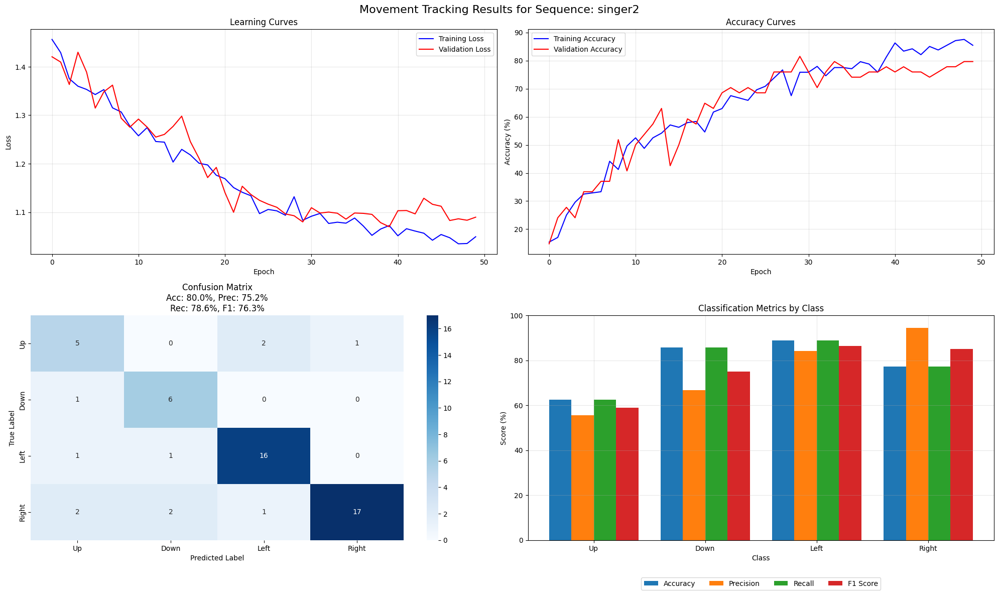

Sequence singer2 completed with accuracy: 80.00%

[52/60] Processing sequence: singer3
Processed groundtruth for singer3
Processed images for singer3
Cleaned up temporary files for singer3
max 0.7347522974014282
Loaded 130 frames and 131 groundtruth entries
Created 125 mini-videos of 5 frames each
Label distribution:
  Up: 14 (11.2%)
  Down: 14 (11.2%)
  Left: 52 (41.6%)
  Right: 45 (36.0%)
Dataset split: 87 train, 18 val, 20 test
Created SNN model
Training on cpu
Dataset sizes - Train: 87, Val: 18, Test: 20
Epoch 1/50 - Train Loss: 1.5137, Train Acc: 12.50%, Val Loss: 1.5130, Val Acc: 11.11%, LR: 0.070000


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 5/50 - Train Loss: 1.3927, Train Acc: 36.25%, Val Loss: 1.3678, Val Acc: 38.89%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.3021, Train Acc: 42.50%, Val Loss: 1.4013, Val Acc: 44.44%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2204, Train Acc: 53.75%, Val Loss: 1.2541, Val Acc: 66.67%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1789, Train Acc: 62.50%, Val Loss: 1.2351, Val Acc: 66.67%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2119, Train Acc: 62.50%, Val Loss: 1.2272, Val Acc: 72.22%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.2004, Train Acc: 67.50%, Val Loss: 1.2143, Val Acc: 77.78%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1264, Train Acc: 81.25%, Val Loss: 1.1276, Val Acc: 88.89%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0801, Train Acc: 85.00%, Val Loss: 1.1169, Val Acc: 83.33%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1330, Train Acc: 77.50%, Val Loss: 1.2242, Val Acc: 77.78%, LR: 0.070000
Epoch 50/50 - Train Loss: 1.0494, Train Acc: 88.75%, Val Loss: 1.0842, Val Acc: 88.89%, LR: 

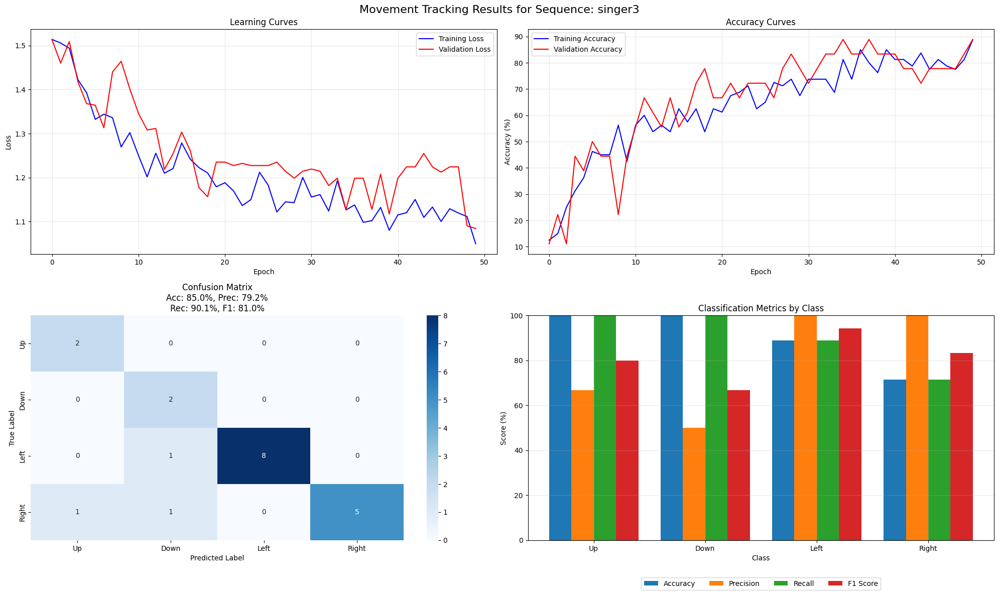

Sequence singer3 completed with accuracy: 85.00%

[53/60] Processing sequence: soccer1
Processed groundtruth for soccer1
Processed images for soccer1
Cleaned up temporary files for soccer1
max 0.9140785336494446
Loaded 391 frames and 392 groundtruth entries
Created 386 mini-videos of 5 frames each
Label distribution:
  Up: 103 (26.7%)
  Down: 103 (26.7%)
  Left: 69 (17.9%)
  Right: 111 (28.8%)
Dataset split: 270 train, 57 val, 59 test
Created SNN model
Training on cpu
Dataset sizes - Train: 270, Val: 57, Test: 59


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.3950, Train Acc: 27.73%, Val Loss: 1.3604, Val Acc: 36.84%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2815, Train Acc: 46.48%, Val Loss: 1.2580, Val Acc: 50.88%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2195, Train Acc: 54.30%, Val Loss: 1.1930, Val Acc: 61.40%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.1610, Train Acc: 64.45%, Val Loss: 1.2274, Val Acc: 57.89%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1379, Train Acc: 69.14%, Val Loss: 1.1794, Val Acc: 64.91%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1202, Train Acc: 70.31%, Val Loss: 1.1654, Val Acc: 66.67%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1190, Train Acc: 73.05%, Val Loss: 1.1372, Val Acc: 71.93%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.0805, Train Acc: 76.56%, Val Loss: 1.1446, Val Acc: 71.93%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.0598, Train Acc: 78.91%, Val Loss: 1.1245, Val Acc: 71.93%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.0536, Train Acc: 78.12%, Val Loss: 1.0823, Val Acc: 77.19%, LR: 0

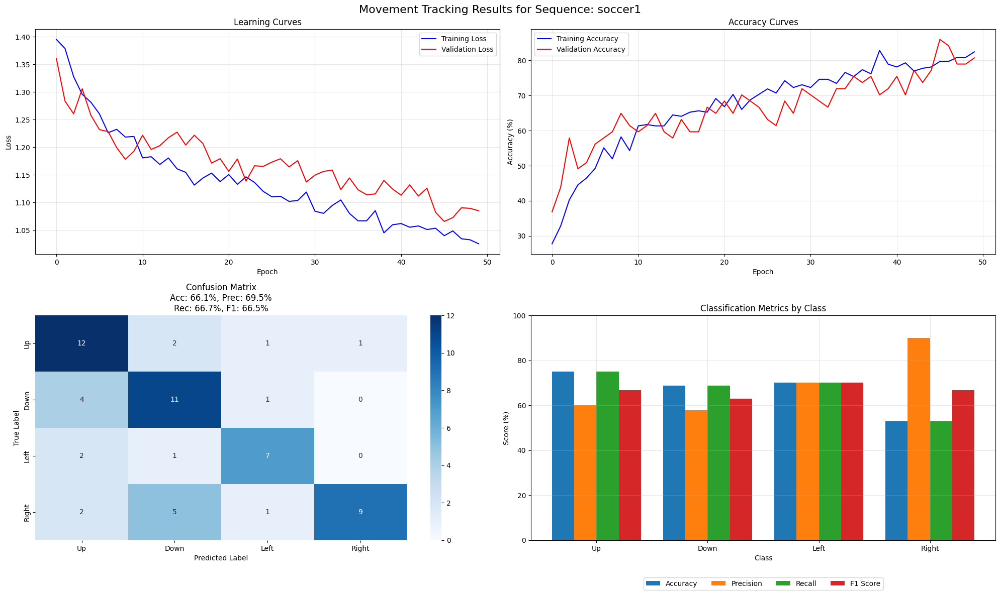

Sequence soccer1 completed with accuracy: 66.10%

[54/60] Processing sequence: soccer2
Processed groundtruth for soccer2
Processed images for soccer2
Cleaned up temporary files for soccer2
max 0.7633048892021179
Loaded 128 frames and 129 groundtruth entries
Created 123 mini-videos of 5 frames each
Label distribution:
  Up: 37 (30.1%)
  Down: 15 (12.2%)
  Left: 23 (18.7%)
  Right: 48 (39.0%)
Dataset split: 86 train, 18 val, 19 test
Created SNN model
Training on cpu
Dataset sizes - Train: 86, Val: 18, Test: 19
Epoch 1/50 - Train Loss: 1.4613, Train Acc: 31.25%, Val Loss: 1.4440, Val Acc: 27.78%, LR: 0.070000


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 5/50 - Train Loss: 1.3391, Train Acc: 45.00%, Val Loss: 1.3264, Val Acc: 33.33%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2345, Train Acc: 57.50%, Val Loss: 1.2529, Val Acc: 61.11%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2079, Train Acc: 65.00%, Val Loss: 1.2318, Val Acc: 66.67%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.1848, Train Acc: 66.25%, Val Loss: 1.2206, Val Acc: 66.67%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1731, Train Acc: 67.50%, Val Loss: 1.1718, Val Acc: 66.67%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1508, Train Acc: 73.75%, Val Loss: 1.2017, Val Acc: 66.67%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.2043, Train Acc: 68.75%, Val Loss: 1.2573, Val Acc: 66.67%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1179, Train Acc: 80.00%, Val Loss: 1.1571, Val Acc: 77.78%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1556, Train Acc: 75.00%, Val Loss: 1.2129, Val Acc: 66.67%, LR: 0.070000
Epoch 50/50 - Train Loss: 1.1301, Train Acc: 77.50%, Val Loss: 1.1740, Val Acc: 72.22%, LR: 

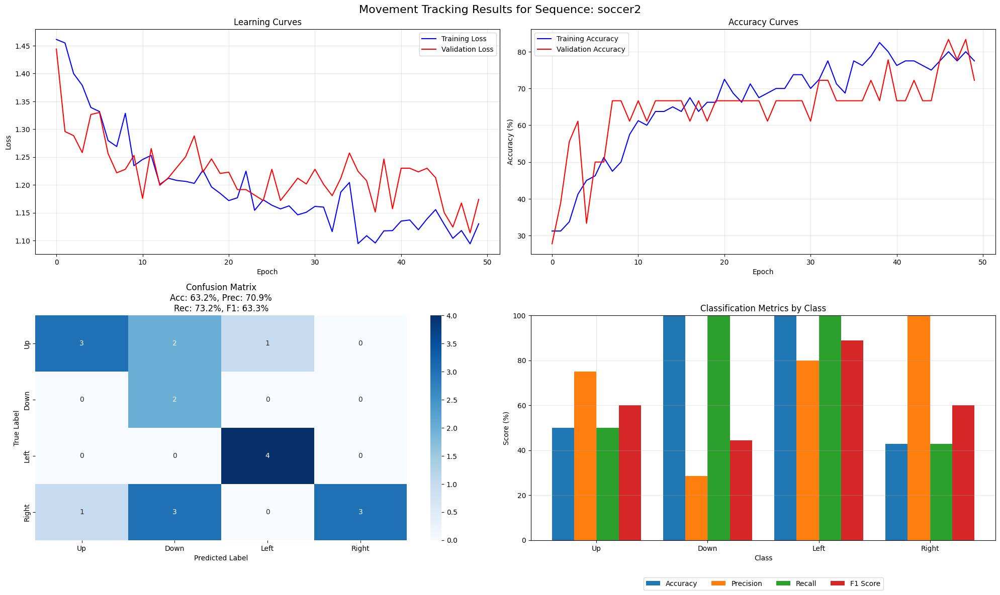

Sequence soccer2 completed with accuracy: 63.16%

[55/60] Processing sequence: soldier
Processed groundtruth for soldier
Processed images for soldier
Cleaned up temporary files for soldier
max 1.0
Loaded 137 frames and 138 groundtruth entries
Created 132 mini-videos of 5 frames each
Label distribution:
  Up: 10 (7.6%)
  Down: 50 (37.9%)
  Left: 19 (14.4%)
  Right: 53 (40.2%)
Dataset split: 92 train, 19 val, 21 test
Created SNN model
Training on cpu
Dataset sizes - Train: 92, Val: 19, Test: 21


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.5662, Train Acc: 6.25%, Val Loss: 1.5821, Val Acc: 5.26%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.4052, Train Acc: 22.50%, Val Loss: 1.5879, Val Acc: 26.32%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.3587, Train Acc: 40.00%, Val Loss: 1.2135, Val Acc: 68.42%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2808, Train Acc: 52.50%, Val Loss: 1.2519, Val Acc: 52.63%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2906, Train Acc: 57.50%, Val Loss: 1.2219, Val Acc: 84.21%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2592, Train Acc: 65.00%, Val Loss: 1.2537, Val Acc: 63.16%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1914, Train Acc: 76.25%, Val Loss: 1.2296, Val Acc: 68.42%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1561, Train Acc: 77.50%, Val Loss: 1.2327, Val Acc: 78.95%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1549, Train Acc: 83.75%, Val Loss: 1.2288, Val Acc: 84.21%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.2035, Train Acc: 76.25%, Val Loss: 1.2288, Val Acc: 84.21%, LR: 0.0

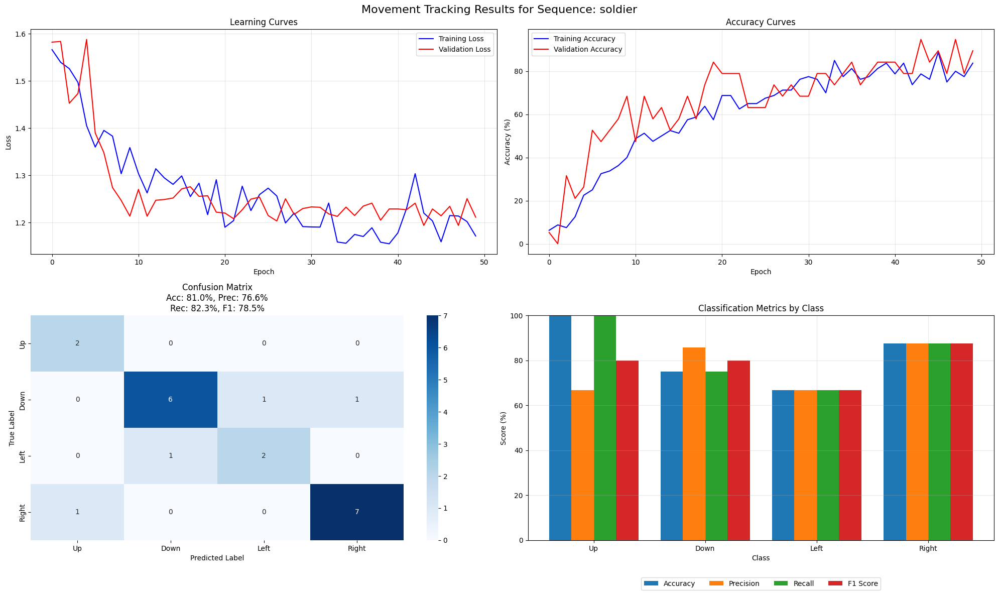

Sequence soldier completed with accuracy: 80.95%

[56/60] Processing sequence: sphere
Processed groundtruth for sphere
Processed images for sphere
Cleaned up temporary files for sphere
max 0.9091326594352722
Loaded 200 frames and 201 groundtruth entries
Created 195 mini-videos of 5 frames each
Label distribution:
  Up: 25 (12.8%)
  Down: 17 (8.7%)
  Left: 73 (37.4%)
  Right: 80 (41.0%)
Dataset split: 136 train, 29 val, 30 test
Created SNN model
Training on cpu
Dataset sizes - Train: 136, Val: 29, Test: 30


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.5465, Train Acc: 12.50%, Val Loss: 1.5432, Val Acc: 13.79%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.4155, Train Acc: 29.69%, Val Loss: 1.3116, Val Acc: 41.38%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.3207, Train Acc: 40.62%, Val Loss: 1.2745, Val Acc: 51.72%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2648, Train Acc: 51.56%, Val Loss: 1.2602, Val Acc: 58.62%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2734, Train Acc: 60.16%, Val Loss: 1.2846, Val Acc: 55.17%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2701, Train Acc: 57.81%, Val Loss: 1.2559, Val Acc: 62.07%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.2211, Train Acc: 69.53%, Val Loss: 1.2174, Val Acc: 75.86%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1565, Train Acc: 78.91%, Val Loss: 1.2119, Val Acc: 82.76%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1604, Train Acc: 76.56%, Val Loss: 1.2284, Val Acc: 82.76%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1501, Train Acc: 80.47%, Val Loss: 1.2159, Val Acc: 75.86%, LR: 0

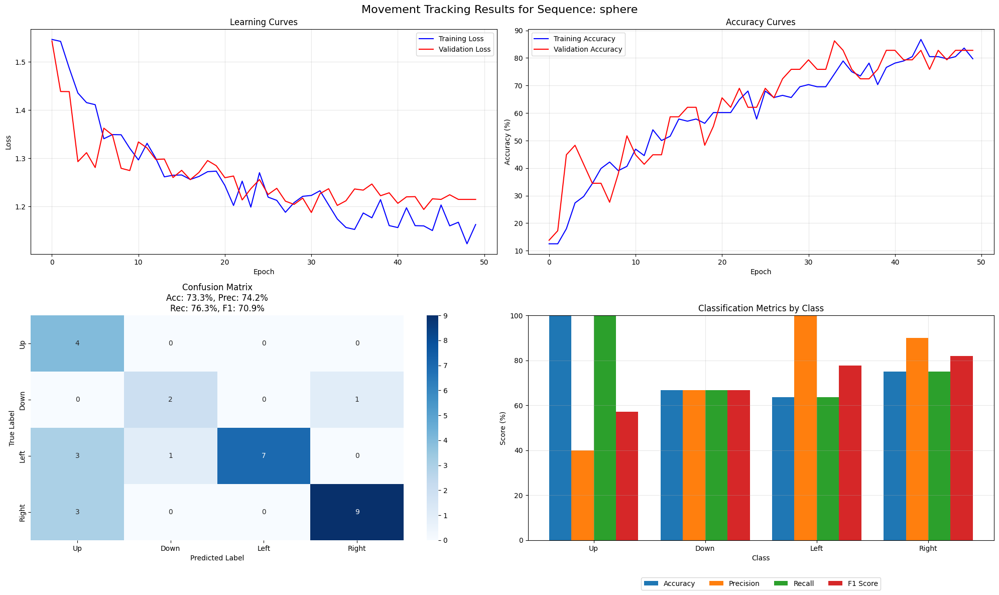

Sequence sphere completed with accuracy: 73.33%

[57/60] Processing sequence: tiger
Processed groundtruth for tiger
Processed images for tiger
Cleaned up temporary files for tiger
max 0.9273291826248169
Loaded 364 frames and 365 groundtruth entries
Created 359 mini-videos of 5 frames each
Label distribution:
  Up: 20 (5.6%)
  Down: 18 (5.0%)
  Left: 158 (44.0%)
  Right: 163 (45.4%)
Dataset split: 251 train, 53 val, 55 test
Created SNN model
Training on cpu
Dataset sizes - Train: 251, Val: 53, Test: 55


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.8993, Train Acc: 5.83%, Val Loss: 1.8184, Val Acc: 5.66%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.8616, Train Acc: 17.08%, Val Loss: 1.9634, Val Acc: 9.43%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.7612, Train Acc: 27.08%, Val Loss: 1.8303, Val Acc: 11.32%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.7926, Train Acc: 20.42%, Val Loss: 1.8924, Val Acc: 5.66%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.7642, Train Acc: 31.25%, Val Loss: 1.7989, Val Acc: 18.87%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.7270, Train Acc: 34.58%, Val Loss: 1.7818, Val Acc: 18.87%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.6930, Train Acc: 39.58%, Val Loss: 1.8277, Val Acc: 22.64%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.7113, Train Acc: 36.25%, Val Loss: 1.7798, Val Acc: 33.96%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.6859, Train Acc: 46.67%, Val Loss: 1.7564, Val Acc: 32.08%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.6023, Train Acc: 40.00%, Val Loss: 1.7399, Val Acc: 33.96%, LR: 0.070

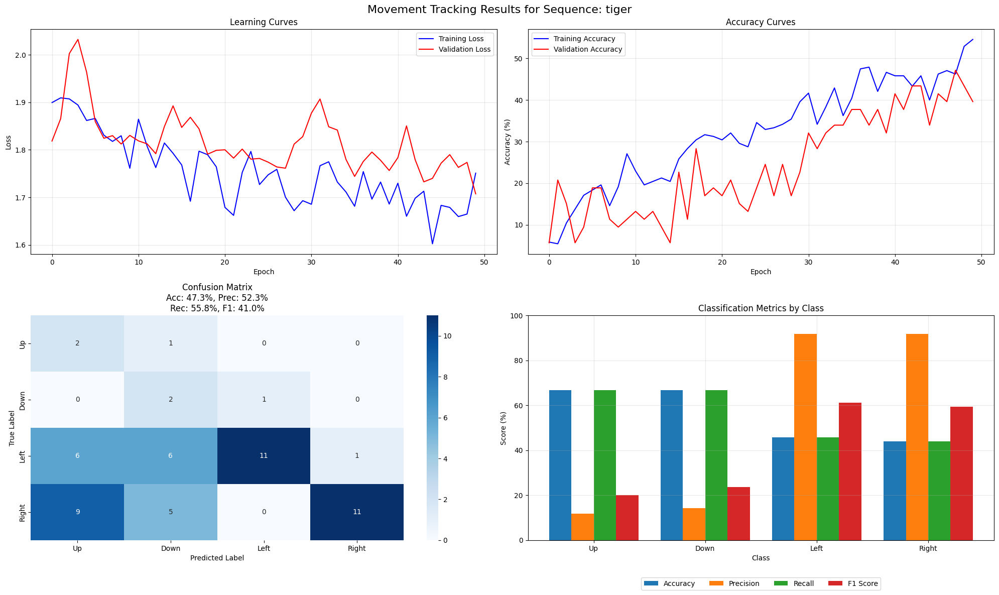

Sequence tiger completed with accuracy: 47.27%

[58/60] Processing sequence: traffic
Processed groundtruth for traffic
Processed images for traffic
Cleaned up temporary files for traffic
max 0.7837779521942139
Loaded 190 frames and 191 groundtruth entries
Created 185 mini-videos of 5 frames each
Label distribution:
  Up: 67 (36.2%)
  Down: 74 (40.0%)
  Left: 19 (10.3%)
  Right: 25 (13.5%)
Dataset split: 129 train, 27 val, 29 test
Created SNN model
Training on cpu
Dataset sizes - Train: 129, Val: 27, Test: 29


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.5081, Train Acc: 35.94%, Val Loss: 1.4794, Val Acc: 37.04%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.4083, Train Acc: 46.09%, Val Loss: 1.4821, Val Acc: 40.74%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.3592, Train Acc: 50.78%, Val Loss: 1.3505, Val Acc: 55.56%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2974, Train Acc: 63.28%, Val Loss: 1.3945, Val Acc: 44.44%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2692, Train Acc: 65.62%, Val Loss: 1.3540, Val Acc: 44.44%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2498, Train Acc: 64.84%, Val Loss: 1.2644, Val Acc: 55.56%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.2406, Train Acc: 67.97%, Val Loss: 1.2994, Val Acc: 62.96%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.2088, Train Acc: 73.44%, Val Loss: 1.3011, Val Acc: 55.56%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.2082, Train Acc: 76.56%, Val Loss: 1.3763, Val Acc: 55.56%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1897, Train Acc: 76.56%, Val Loss: 1.3785, Val Acc: 59.26%, LR: 0

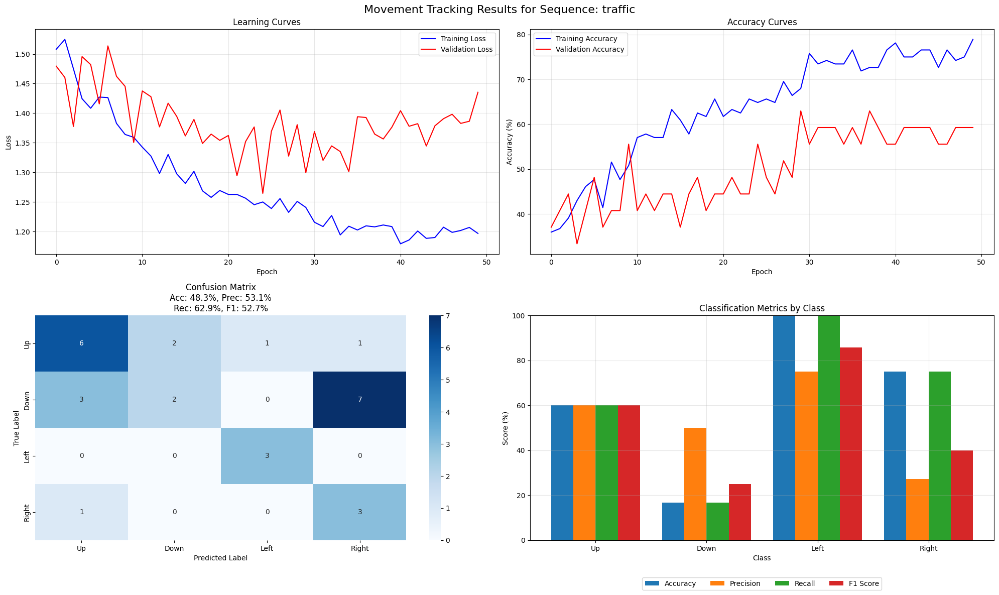

Sequence traffic completed with accuracy: 48.28%

[59/60] Processing sequence: tunnel
Processed groundtruth for tunnel
Processed images for tunnel
Cleaned up temporary files for tunnel
max 0.7047483921051025
Loaded 311 frames and 312 groundtruth entries
Created 306 mini-videos of 5 frames each
Label distribution:
  Up: 89 (29.1%)
  Down: 71 (23.2%)
  Left: 71 (23.2%)
  Right: 75 (24.5%)
Dataset split: 214 train, 45 val, 47 test
Created SNN model
Training on cpu
Dataset sizes - Train: 214, Val: 45, Test: 47


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.3890, Train Acc: 29.33%, Val Loss: 1.4353, Val Acc: 22.22%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.3772, Train Acc: 34.13%, Val Loss: 1.3957, Val Acc: 22.22%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.3550, Train Acc: 37.02%, Val Loss: 1.3986, Val Acc: 28.89%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.3231, Train Acc: 40.38%, Val Loss: 1.3991, Val Acc: 37.78%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.3194, Train Acc: 42.79%, Val Loss: 1.4012, Val Acc: 31.11%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.2905, Train Acc: 50.00%, Val Loss: 1.4592, Val Acc: 24.44%, LR: 0.052500
Epoch 30/50 - Train Loss: 1.3010, Train Acc: 44.71%, Val Loss: 1.4661, Val Acc: 24.44%, LR: 0.052500
Epoch 35/50 - Train Loss: 1.2758, Train Acc: 52.40%, Val Loss: 1.4065, Val Acc: 35.56%, LR: 0.052500
Epoch 40/50 - Train Loss: 1.2512, Train Acc: 53.37%, Val Loss: 1.3620, Val Acc: 35.56%, LR: 0.039375
Epoch 45/50 - Train Loss: 1.2479, Train Acc: 51.92%, Val Loss: 1.4391, Val Acc: 24.44%, LR: 0

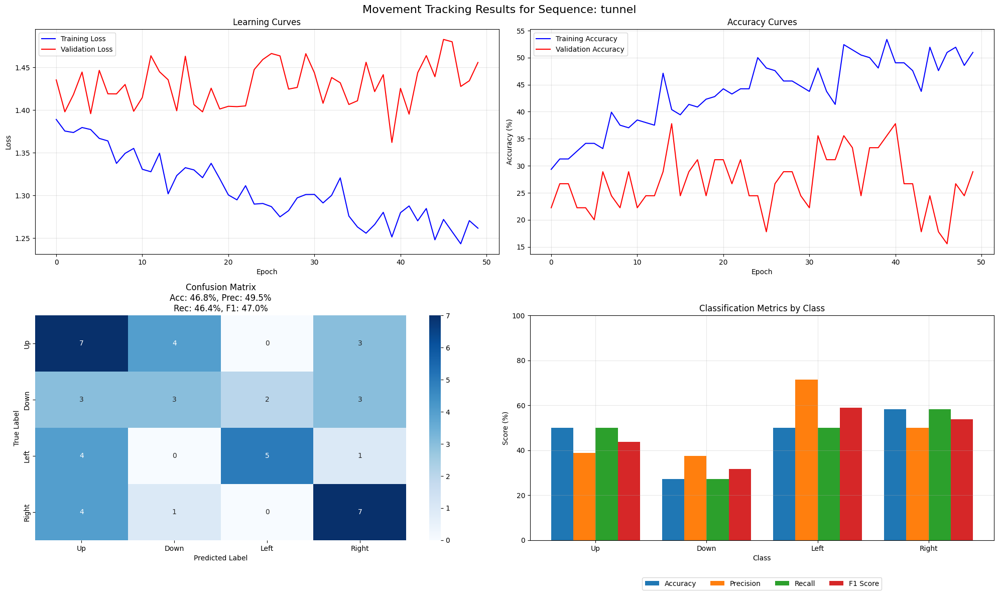

Sequence tunnel completed with accuracy: 46.81%

[60/60] Processing sequence: wiper
Processed groundtruth for wiper
Processed images for wiper
Cleaned up temporary files for wiper
max 0.9920454621315002
Loaded 340 frames and 341 groundtruth entries
Created 335 mini-videos of 5 frames each
Label distribution:
  Up: 97 (29.0%)
  Down: 62 (18.5%)
  Left: 96 (28.7%)
  Right: 80 (23.9%)
Dataset split: 234 train, 50 val, 51 test
Created SNN model
Training on cpu
Dataset sizes - Train: 234, Val: 50, Test: 51


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50 - Train Loss: 1.3960, Train Acc: 28.12%, Val Loss: 1.4101, Val Acc: 22.00%, LR: 0.070000
Epoch 5/50 - Train Loss: 1.2762, Train Acc: 46.88%, Val Loss: 1.3296, Val Acc: 44.00%, LR: 0.070000
Epoch 10/50 - Train Loss: 1.2738, Train Acc: 50.89%, Val Loss: 1.3078, Val Acc: 46.00%, LR: 0.070000
Epoch 15/50 - Train Loss: 1.2021, Train Acc: 58.48%, Val Loss: 1.2465, Val Acc: 50.00%, LR: 0.070000
Epoch 20/50 - Train Loss: 1.2008, Train Acc: 60.71%, Val Loss: 1.3171, Val Acc: 48.00%, LR: 0.070000
Epoch 25/50 - Train Loss: 1.1863, Train Acc: 62.50%, Val Loss: 1.2174, Val Acc: 58.00%, LR: 0.070000
Epoch 30/50 - Train Loss: 1.1703, Train Acc: 62.95%, Val Loss: 1.2325, Val Acc: 54.00%, LR: 0.070000
Epoch 35/50 - Train Loss: 1.1172, Train Acc: 68.30%, Val Loss: 1.2281, Val Acc: 60.00%, LR: 0.070000
Epoch 40/50 - Train Loss: 1.1271, Train Acc: 66.07%, Val Loss: 1.2240, Val Acc: 58.00%, LR: 0.070000
Epoch 45/50 - Train Loss: 1.1074, Train Acc: 70.09%, Val Loss: 1.2290, Val Acc: 56.00%, LR: 0

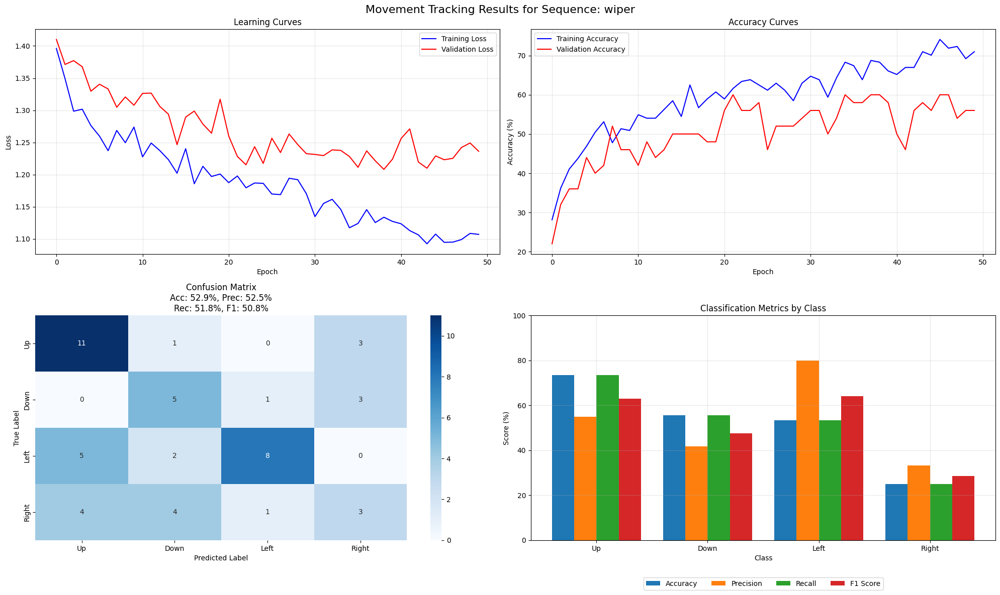

Sequence wiper completed with accuracy: 52.94%

===== FINAL RESULTS =====
        accuracy  precision_up  precision_down  precision_left  \
count  55.000000     55.000000       55.000000       55.000000   
mean   64.836446     53.276643       57.653297       75.257841   
std    20.810515     24.389555       26.944293       27.961496   
min     0.000000      0.000000        0.000000        0.000000   
25%    50.000000     40.000000       35.991379       70.714286   
50%    68.181818     55.555556       60.869565       84.210526   
75%    81.482993     71.825397       80.000000       94.375000   
max    91.428571    100.000000      100.000000      100.000000   

       precision_right   recall_up  recall_down  recall_left  recall_right  \
count        55.000000   55.000000    55.000000    55.000000     55.000000   
mean         75.103041   76.180210    66.066310    65.114925     60.633006   
std          29.005358   20.581308    28.566992    28.666312     25.849044   
min           0.000

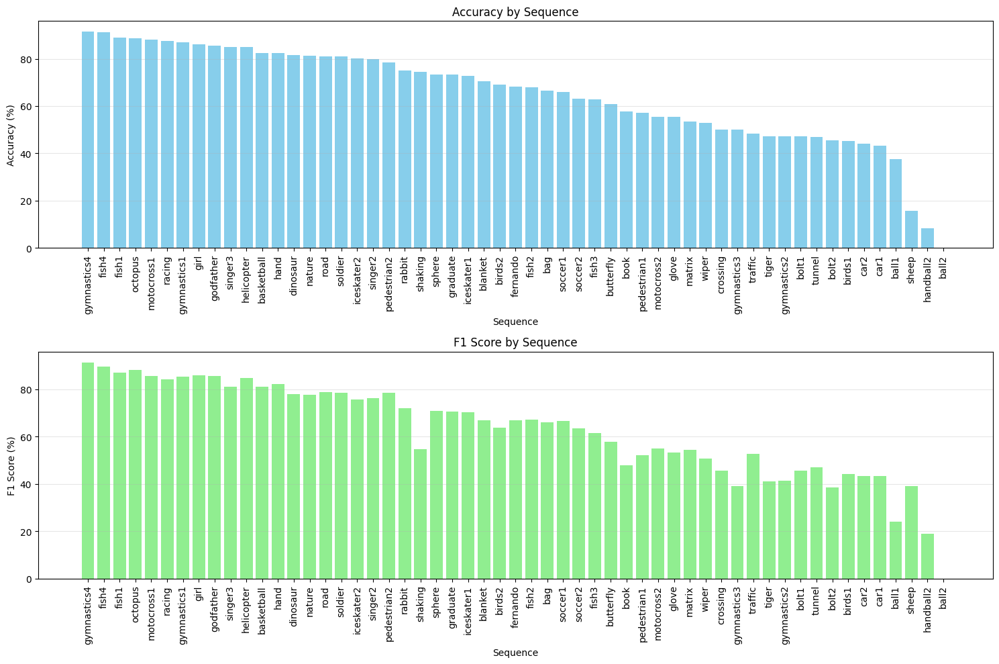

All results saved to results/snn_tracking_results_final_20250315_123723.csv


In [ ]:
# --- Main Class for SNN-based Movement Tracking ---
class SNNMovementTracker1:
  def __init__(self, sequence_name, image_resize=(128, 128), dwt_threshold=20,
                hidden_size=256, beta=0.1, lr=0.1):
      self.sequence_name = sequence_name
      self.image_resize = image_resize
      self.dwt_threshold = dwt_threshold
      self.hidden_size = hidden_size
      self.beta = beta
      self.lr = lr
      self.num_classes = 4  # Up, Down, Left, Right
      self.class_names = ["Up", "Down", "Left", "Right"]
      self.train_ratio = 0.7
      self.val_ratio = 0.15
      # Initialize paths
      self.sequence_dir = os.path.join("sequences", sequence_name)
      self.image_files = None
      self.ground_truth_file = None
      self.mini_video_size = 5
      # Initialize data containers
      self.frames = None
      self.ground_truth = None
      self.labels = None
      self.spike_inputs = None
      self.model = None
      self.video_size = 5 # Number of frames in each mini-video
      self.mini_videos = None
      self.train_videos = None
      self.val_videos = None
      self.test_videos = None
      self.train_labels = None
      self.val_labels = None
      self.test_labels = None
      self.train_loader = None
      self.val_loader = None
      self.test_loader = None

      # Training history
      self.train_loss_history = []
      self.val_loss_history = []
      self.train_acc_history = []
      self.val_acc_history = []

  def load_data(self):
    """Load image and groundtruth data for the sequence"""
    # Find image files
    self.image_files = sorted([f for f in os.listdir(self.sequence_dir)
                              if f.endswith(".jpg")])

    if not self.image_files:
        raise FileNotFoundError(f"No image files found in {self.sequence_dir}")

    # Find groundtruth file
    gt_files = [f for f in os.listdir(self.sequence_dir) if f.endswith("_groundtruth.txt")]
    if not gt_files:
        raise FileNotFoundError(f"No groundtruth file found in {self.sequence_dir}")
    self.ground_truth_file = os.path.join(self.sequence_dir, gt_files[0])

    # Load images
    frames = []
    frames1 =[]
    for img_file in self.image_files:
        img_path = os.path.join(self.sequence_dir, img_file)

        frame = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        frame = cv2.resize(frame, (128, 128))  # Resize for consistency
        frames.append(frame)
    frames2 = []
    spike_responses = []
    for i in range(len(frames)-1):
      frame_diff = np.abs(frames[i+1].astype(np.float32) - frames[i].astype(np.float32))

      # Apply DWT
      coeffs2 = pywt.dwt2(frame_diff, 'haar')
      LL, (LH, HL, HH) = coeffs2

      # Create richer representation by combining components
      # Scale them to enhance signal contrast
      LL_scaled = LL / LL.max() if LL.max() > 0 else LL
      LH_scaled = LH / LH.max() if LH.max() > 0 else LH
      HL_scaled = HL / HL.max() if HL.max() > 0 else HL
      combined = 0.4*LL_scaled+ 0.3*LH_scaled + 0.3*HL_scaled

      # This adjusts to the dynamic range of each frame
      adaptive_threshold = np.percentile(combined, 75)  # Top 25% of values become spikes

      spikes = np.where(combined > adaptive_threshold, 1.0, 0.0)
      spike_responses.append(spikes)
      frames2.append(combined)

    self.frames = np.array(frames2)
    self.spike_inputs = torch.tensor(spike_responses,
                                            dtype=torch.float)

    # Load ground truth
    self.ground_truth = np.loadtxt(self.ground_truth_file, delimiter=",")
    print(f'max {np.max(self.frames, axis = (0,1,2))}')
    print(f"Loaded {len(self.frames)} frames and {len(self.ground_truth)} groundtruth entries")


  def create_mini_videos(self):
    """Create mini-videos from sequential frames."""
    if self.ground_truth is None:
      raise ValueError("Ground truth data not loaded. Call load_data() first.")
    num_frames = len(self.frames)
    self.mini_videos = []
    self.labels = []

    for i in range(num_frames - self.mini_video_size):
        mini_video = self.frames[i:i + self.mini_video_size]
        self.mini_videos.append(mini_video)

        # Example labeling strategy: Based on motion direction
        prev_x = np.mean(self.ground_truth[i, [0, 2, 4, 6]])
        prev_y = np.mean(self.ground_truth[i, [1, 3, 5, 7]])
        curr_x = np.mean(self.ground_truth[i + self.mini_video_size - 1, [0, 2, 4, 6]])
        curr_y = np.mean(self.ground_truth[i + self.mini_video_size - 1, [1, 3, 5, 7]])

        dx = curr_x - prev_x
        dy = curr_y - prev_y

        if abs(dy) > abs(dx):  # Vertical motion
            label = 0 if dy < 0 else 1  # Up or Down
        else:  # Horizontal motion
            label = 2 if dx < 0 else 3  # Left or Right

        self.labels.append(label)

    self.mini_videos = np.array(self.mini_videos, dtype=np.float32)
    self.labels = np.array(self.labels, dtype=np.int64)
    print(f"Created {len(self.mini_videos)} mini-videos of {self.mini_video_size} frames each")

    # Print distribution of labels
    unique_labels, counts = np.unique(self.labels, return_counts=True)
    print("Label distribution:")
    for i, count in zip(unique_labels, counts):
        print(f"  {self.class_names[i]}: {count} ({count/len(self.labels)*100:.1f}%)")


  def split_dataset(self):
      """Split mini-videos into training, validation, and test sets."""
      train_videos, temp_videos, train_labels, temp_labels = train_test_split(
          self.mini_videos, self.labels, test_size=1 - self.train_ratio, random_state=42, stratify=self.labels)

      val_size = self.val_ratio / (1 - self.train_ratio)
      val_videos, test_videos, val_labels, test_labels = train_test_split(
          temp_videos, temp_labels, test_size=1 - val_size, random_state=42, stratify=temp_labels)

      # Convert to tensors
      self.train_videos = torch.tensor(train_videos, dtype=torch.float32)
      self.val_videos = torch.tensor(val_videos, dtype=torch.float32)
      self.test_videos = torch.tensor(test_videos, dtype=torch.float32)

      self.train_labels = torch.tensor(train_labels, dtype=torch.long)
      self.val_labels = torch.tensor(val_labels, dtype=torch.long)
      self.test_labels = torch.tensor(test_labels, dtype=torch.long)

      print(f"Dataset split: {len(self.train_videos)} train, {len(self.val_videos)} val, {len(self.test_videos)} test")

  def get_data_loaders(self, batch_size=16):
      """Create PyTorch DataLoaders."""

      # Print dataset sizes to help debug any issues
      print(f"Dataset sizes - Train: {len(self.train_videos)}, Val: {len(self.val_videos)}, Test: {len(self.test_videos)}")

      # Check if batch size is appropriate for dataset sizes
      if batch_size > len(self.val_videos):
        print(f"Warning: Batch size ({batch_size}) is larger than validation set size ({len(self.val_videos)}).")
        print(f"Consider reducing batch size or using different train/val split ratios.")

      train_dataset = torch.utils.data.TensorDataset(self.train_videos, self.train_labels)
      val_dataset = torch.utils.data.TensorDataset(self.val_videos, self.val_labels)
      test_dataset = torch.utils.data.TensorDataset(self.test_videos, self.test_labels)

      train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
      val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size, drop_last=False)
      test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, drop_last=False)

      return train_loader, val_loader, test_loader

  def compute_class_weights(self,lst):
    labels = lst[0]
    num_classes = lst[1]
    """Compute inverse frequency class weights"""
    class_counts = torch.bincount(labels, minlength=num_classes)
    total_samples = class_counts.sum()
    class_weights = total_samples / (class_counts + 1e-6)  # Avoid division by zero
    class_weights /= class_weights.sum()  # Normalize
    return class_weights

  def create_model(self, beta = 0.6, lr = 0.2 ):
    """Define the SNN model architecture"""

    # Account for the additional features (density and variance)
    #input_size = (self.image_resize[0] * self.image_resize[1]) + 2
    #print(input_size)
    class SNNModel(nn.Module):
        def __init__(self, input_size =(128*128)//4, hidden_size = 200, output_size = 4, beta = beta):
            super().__init__()
            # Input normalization
            #self.bn_input = nn.BatchNorm1d(4096)

            # Two hidden layers architecture
            #print(input_size)
            self.fc1 = nn.Linear(input_size, hidden_size)
            self.lif1 = snn.Leaky(beta=beta)
            self.bn1 = nn.BatchNorm1d(hidden_size)
            self.dropout1 = nn.Dropout(0.3)

            self.fc2 = nn.Linear(hidden_size, hidden_size // 2)
            self.lif2 = snn.Leaky(beta=beta)
            self.bn2 = nn.BatchNorm1d(hidden_size // 2)
            self.dropout2 = nn.Dropout(0.3)

            # Output layer
            self.fc3 = nn.Linear(hidden_size // 2, output_size)
            self.lif3 = snn.Leaky(beta=beta)

        def forward(self, x):
            # Initialize membrane potentials
            mem1 = self.lif1.init_leaky()
            mem2 = self.lif2.init_leaky()
            mem3 = self.lif3.init_leaky()

            batch_size = x.shape[0]

            for t in range(5):

              frame_batch = x[:, t, :, :]  # Shape: [batch_size, frame_no, H, W]

              flattened_tensor = frame_batch.view(batch_size, -1)

              # First hidden layer
              cur1 = self.fc1(flattened_tensor)
              spk1, mem1 = self.lif1(cur1, mem1)
              spk1 = self.bn1(spk1)
              spk1 = self.dropout1(spk1)

              # Second hidden layer
              cur2 = self.fc2(spk1)
              spk2, mem2 = self.lif2(cur2, mem2)
              spk2 = self.bn2(spk2)
              spk2 = self.dropout2(spk2)

              # Output layer
              cur3 = self.fc3(spk2)
              spk3, mem3 = self.lif3(cur3, mem3)
            return spk3, [mem3, spk3]


    weights = self.compute_class_weights([self.train_labels, 4])
    self.model = SNNModel()

    self.optimizer = optim.SGD(self.model.parameters(), lr=lr, momentum=0.9)
    self.loss_fn = nn.CrossEntropyLoss(label_smoothing=0.2, weight=weights)
    print(f"Created SNN model")

  def train(self, num_epochs=10, batch_size=16):
    """Train the SNN model with adaptive learning rate and model saving"""
    if self.model is None:
      raise ValueError("Model not created. Call create_model() first.")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Training on {device}")

    self.model.to(device)

    # Create data loaders
    self.train_loader, self.val_loader, self.test_loader = self.get_data_loaders(batch_size)
    train_loader = self.train_loader
    val_loader = self.val_loader

    # Initialize history trackers
    self.train_loss_history = []
    self.val_loss_history = []
    self.train_acc_history = []
    self.val_acc_history = []

    # Setup adaptive learning rate scheduler
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
      self.optimizer,
      mode='min',
      factor=0.75,
      patience=15,
      verbose=True,
      min_lr=1e-6
    )

    # Track best model and performance
    best_val_loss = float('inf')
    best_epoch = -1
    patience_counter = 0
    patience = 100  # Early stopping patience - will stop after 100 epochs without improvement

    for epoch in range(num_epochs):
      # Training
      self.model.train()
      train_loss = 0.0
      train_correct = 0
      train_total = 0

      for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        self.optimizer.zero_grad()

        # Forward pass
        spk_out, lst = self.model(inputs)

        logits = spk_out
        loss = self.loss_fn(logits, targets)

        # Backward pass
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)  # Prevent exploding gradients

        self.optimizer.step()

        # Calculate training accuracy
        _, preds = torch.max(spk_out, 1)
        train_correct += (preds == targets).sum().item()
        train_total += targets.size(0)
        train_loss += loss.item() * inputs.size(0)

      # Prevent division by zero
      if train_total > 0:
        train_loss /= train_total
        train_accuracy = 100.0 * train_correct / train_total
      else:
        train_loss = float('inf')
        train_accuracy = 0.0
        print("Warning: No training samples were processed. Batch size may be too large for training set.")
      self.train_loss_history.append(train_loss)
      self.train_acc_history.append(train_accuracy)

      # Validation
      self.model.eval()
      val_loss = 0.0
      val_correct = 0
      val_total = 0

      with torch.no_grad():
        for inputs, targets in val_loader:
          inputs, targets = inputs.to(device), targets.to(device)

          # Forward pass
          spk_out, _ = self.model(inputs)
          loss = self.loss_fn(spk_out, targets)

          # Calculate validation accuracy
          _, preds = torch.max(spk_out, 1)
          val_correct += (preds == targets).sum().item()
          val_total += targets.size(0)
          val_loss += loss.item() * inputs.size(0)

      # Prevent division by zero
      if val_total > 0:
        val_loss /= val_total
        val_accuracy = 100.0 * val_correct / val_total
      else:
        val_loss = float('inf')  # Set to infinity if no validation samples processed
        val_accuracy = 0.0
        print("Warning: No validation samples were processed. Batch size may be too large for validation set.")
      self.val_loss_history.append(val_loss)
      self.val_acc_history.append(val_accuracy)

      # Update learning rate based on validation loss
      scheduler.step(val_loss)

      # Print epoch results (one line, every 5 epochs)
      current_lr = self.optimizer.param_groups[0]['lr']
      if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{num_epochs} - Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.2f}%, Val Loss: {val_loss:.4f}, Val Acc: {val_accuracy:.2f}%, LR: {current_lr:.6f}")

      # Early stopping check and best model saving
      if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        patience_counter = 0

        # Create model save directory if it doesn't exist
        os.makedirs("models", exist_ok=True)

        # Save model with descriptive filename including sequence name
        model_path = f"models/{self.sequence_name}_snn_model_epoch{epoch+1}_valLoss{val_loss:.4f}.pth"
        torch.save({
          'epoch': epoch,
          'model_state_dict': self.model.state_dict(),
          'optimizer_state_dict': self.optimizer.state_dict(),
          'scheduler_state_dict': scheduler.state_dict(),
          'train_loss': train_loss,
          'val_loss': val_loss,
          'train_acc': train_accuracy,
          'val_acc': val_accuracy,
          'best_val_loss': best_val_loss,
          'sequence_name': self.sequence_name
        }, model_path)

        # Save a permanent "best" version for easier reference
        best_model_path = f"models/{self.sequence_name}_snn_model_best.pth"
        torch.save({
          'epoch': epoch,
          'model_state_dict': self.model.state_dict(),
          'optimizer_state_dict': self.optimizer.state_dict(),
          'scheduler_state_dict': scheduler.state_dict(),
          'train_loss': train_loss,
          'val_loss': val_loss,
          'train_acc': train_accuracy,
          'val_acc': val_accuracy,
          'best_val_loss': best_val_loss,
          'sequence_name': self.sequence_name
        }, best_model_path)
      else:
        patience_counter += 1
        if patience_counter >= patience:
          print(f"Early stopping at epoch {epoch+1}. No improvement for {patience} epochs.")
          break

    print(f"\nTraining complete. Best model saved at epoch {best_epoch} with validation loss: {best_val_loss:.4f}")

    # Load the best model for evaluation
    best_model_path = f"models/{self.sequence_name}_snn_model_best.pth"
    checkpoint = torch.load(best_model_path)
    self.model.load_state_dict(checkpoint['model_state_dict'])
    print(f"Loaded best model from epoch {checkpoint['epoch']+1} for evaluation.")

  def evaluate(self):
    """Evaluate the model on test data and produce visualizations

    Returns:
        dict: Dictionary containing all evaluation metrics
    """
    if self.model is None:
        raise ValueError("Model not trained. Call train() first.")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    self.model.to(device)
    self.model.eval()
    test_loader = self.test_loader


    # Compute accuracy and gather predictions
    correct = 0
    total = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass
            spk_out, _ = self.model(inputs)
            #print(f' test out: {spk_out}')
            # Get predictions
            _, preds = torch.max(spk_out, 1)

            # Update statistics
            total += targets.size(0)
            correct += (preds == targets).sum().item()

            # Store for confusion matrix
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

     # Calculate accuracy, precision, recall, and F1-score
        accuracy = 100.0 * correct / total
        precision, recall, f1, _ = precision_recall_fscore_support(
            all_targets, all_preds, average=None, labels=range(self.num_classes)
        )

        # Overall metrics (macro average)
        overall_precision = np.mean(precision)
        overall_recall = np.mean(recall)
        overall_f1 = np.mean(f1)

        # Calculate confusion matrix
        cm = confusion_matrix(all_targets, all_preds)

        # Print results
        print(f"Test Accuracy: {accuracy:.2f}%")
        print(f"Overall Precision: {overall_precision*100:.2f}%")
        print(f"Overall Recall: {overall_recall*100:.2f}%")
        print(f"Overall F1 Score: {overall_f1*100:.2f}%")

        print("\nPer-class metrics:")
        for i in range(self.num_classes):
            print(f"  {self.class_names[i]}:")
            print(f"    Precision: {precision[i]*100:.2f}%")
            print(f"    Recall: {recall[i]*100:.2f}%")
            print(f"    F1 Score: {f1[i]*100:.2f}%")

        # Plot results
        plt.figure(figsize=(20, 12))

        # Add sequence name to the main figure title
        plt.suptitle(f"Movement Tracking Results for Sequence: {self.sequence_name}", fontsize=16, y=0.98)

        # Plot training and validation loss & accuracy
        plt.subplot(2, 2, 1)
        plt.plot(self.train_loss_history, 'b-', label='Training Loss')
        plt.plot(self.val_loss_history, 'r-', label='Validation Loss')
        plt.title('Learning Curves')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, alpha=0.3)

        plt.subplot(2, 2, 2)
        plt.plot(self.train_acc_history, 'b-', label='Training Accuracy')
        plt.plot(self.val_acc_history, 'r-', label='Validation Accuracy')
        plt.title('Accuracy Curves')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy (%)')
        plt.legend()
        plt.grid(True, alpha=0.3)

        # Plot confusion matrix
        plt.subplot(2, 2, 3)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=self.class_names,
                    yticklabels=self.class_names)
        plt.title(f'Confusion Matrix\nAcc: {accuracy:.1f}%, Prec: {overall_precision*100:.1f}%\nRec: {overall_recall*100:.1f}%, F1: {overall_f1*100:.1f}%')
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')

        # Plot precision, recall, and F1-score
        plt.subplot(2, 2, 4)
        x = np.arange(len(self.class_names))
        width = 0.25

        # Calculate per-class accuracy from confusion matrix
        per_class_accuracy = np.zeros(self.num_classes)
        for i in range(self.num_classes):
            per_class_accuracy[i] = 100.0 * cm[i, i] / np.sum(cm[i, :]) if np.sum(cm[i, :]) > 0 else 0

        # Create grouped bar chart with 4 metrics
        bar_width = 0.2  # Narrower bars to fit 4 groups
        plt.bar(x - 1.5*bar_width, per_class_accuracy, bar_width, label='Accuracy')
        plt.bar(x - 0.5*bar_width, precision * 100, bar_width, label='Precision')
        plt.bar(x + 0.5*bar_width, recall * 100, bar_width, label='Recall')
        plt.bar(x + 1.5*bar_width, f1 * 100, bar_width, label='F1 Score')

        plt.title('Classification Metrics by Class')
        plt.xlabel('Class')
        plt.ylabel('Score (%)')
        plt.xticks(x, self.class_names)
        plt.ylim(0, 100)
        plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=4)
        plt.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.savefig(f"{self.sequence_name}_sandra_results.png", dpi=300, bbox_inches='tight')
        plt.show()

        # Calculate metrics dictionary for return
        metrics = {
            'accuracy': accuracy,
            'precision': precision * 100,
            'recall': recall * 100,
            'f1': f1 * 100,
            'confusion_matrix': cm
        }

    return metrics

# --- Main Execution Logic ---
def main():
  # Import necessary modules for this function
  import pandas as pd
  from datetime import datetime

  # Step 1: Setup directories
  os.makedirs("sequences", exist_ok=True)
  os.makedirs("temp", exist_ok=True)
  os.makedirs("models", exist_ok=True)
  os.makedirs("results", exist_ok=True)

  # Step 2: Get all sequence names
  sequence_names = fetch_vot_sequence_names()

  if not sequence_names:
    print("Failed to retrieve sequence names. Exiting.")
    return

  print(f"Found {len(sequence_names)} sequences to process")

  # Create DataFrame to store results
  results_df = pd.DataFrame(columns=[
    'sequence_name', 'total_frames', 'count_up', 'count_down', 'count_left', 'count_right',
    'accuracy', 'precision_up', 'precision_down', 'precision_left', 'precision_right',
    'recall_up', 'recall_down', 'recall_left', 'recall_right',
    'f1_up', 'f1_down', 'f1_left', 'f1_right',
    'overall_precision', 'overall_recall', 'overall_f1'
  ])

  # Get current timestamp for unique results file
  timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

  # Process each sequence
  for i, sequence_name in enumerate(sequence_names):
    try:
      print(f"\n[{i+1}/{len(sequence_names)}] Processing sequence: {sequence_name}")

      # Download the dataset JSON
      json_url = "https://data.votchallenge.net/vot2015/dataset/description.json"
      data = download_json(json_url)

      if not data:
        print(f"Failed to download dataset description for {sequence_name}. Skipping.")
        continue

      # Find the sequence in the data
      seq = next((s for s in data['sequences'] if s['name'] == sequence_name), None)

      if not seq:
        print(f"Sequence {sequence_name} not found in dataset. Skipping.")
        continue

      # Process the sequence
      try:
        process_sequence(seq)
      except Exception as e:
        print(f"Error processing sequence {sequence_name}: {e}. Skipping.")
        continue

      # Create and train the movement tracker
      tracker = SNNMovementTracker1(sequence_name,
                                    image_resize=(128, 128),
                                    dwt_threshold=20,
                                    hidden_size=256)

      try:
        # Process the data
        tracker.load_data()
        tracker.create_mini_videos()
        tracker.split_dataset()

        # Train and evaluate the model
        tracker.create_model(beta=0.69, lr=0.07)
        tracker.train(num_epochs=50, batch_size=16)
        metrics = tracker.evaluate()

        # Calculate direction counts from the labels
        unique_labels, label_counts = np.unique(tracker.labels, return_counts=True)

        # Initialize counts for each direction
        counts_by_direction = {0: 0, 1: 0, 2: 0, 3: 0}  # Up, Down, Left, Right

        # Fill in the actual counts
        for label, count in zip(unique_labels, label_counts):
            counts_by_direction[label] = count

        # Extract metrics for DataFrame
        sequence_results = {
          'sequence_name': sequence_name,
          'total_frames': len(tracker.frames) + 1,  # Adding 1 because frames is derived from frame differences
          'count_up': counts_by_direction[0],
          'count_down': counts_by_direction[1],
          'count_left': counts_by_direction[2],
          'count_right': counts_by_direction[3],
          'accuracy': metrics['accuracy'],
          'precision_up': metrics['precision'][0],
          'precision_down': metrics['precision'][1],
          'precision_left': metrics['precision'][2],
          'precision_right': metrics['precision'][3],
          'recall_up': metrics['recall'][0],
          'recall_down': metrics['recall'][1],
          'recall_left': metrics['recall'][2],
          'recall_right': metrics['recall'][3],
          'f1_up': metrics['f1'][0],
          'f1_down': metrics['f1'][1],
          'f1_left': metrics['f1'][2],
          'f1_right': metrics['f1'][3],
          'overall_precision': np.mean(metrics['precision']),
          'overall_recall': np.mean(metrics['recall']),
          'overall_f1': np.mean(metrics['f1'])
        }

        # Add to results DataFrame
        results_df = pd.concat([results_df, pd.DataFrame([sequence_results])], ignore_index=True)

        # Save intermediate results after each sequence
        results_df.to_csv(f"results/snn_tracking_results_{timestamp}.csv", index=False)

        print(f"Sequence {sequence_name} completed with accuracy: {metrics['accuracy']:.2f}%")

      except Exception as e:
        print(f"Error training/evaluating sequence {sequence_name}: {e}. Skipping.")
        continue

    except Exception as e:
      print(f"Unexpected error with sequence {sequence_name}: {e}. Continuing with next sequence.")
      continue

  # After all sequences are processed, save and display final results
  results_df.to_csv(f"results/snn_tracking_results_final_{timestamp}.csv", index=False)

  print("\n===== FINAL RESULTS =====")
  print(results_df.describe())

  # Generate summary plot
  try:
    plt.figure(figsize=(15, 10))

    # Sort by accuracy
    sorted_df = results_df.sort_values('accuracy', ascending=False)

    # Plot accuracies
    plt.subplot(2, 1, 1)
    plt.bar(sorted_df['sequence_name'], sorted_df['accuracy'], color='skyblue')
    plt.xlabel('Sequence')
    plt.ylabel('Accuracy (%)')
    plt.title('Accuracy by Sequence')
    plt.xticks(rotation=90)
    plt.grid(axis='y', alpha=0.3)

    # Plot F1 scores
    plt.subplot(2, 1, 2)
    plt.bar(sorted_df['sequence_name'], sorted_df['overall_f1'], color='lightgreen')
    plt.xlabel('Sequence')
    plt.ylabel('F1 Score (%)')
    plt.title('F1 Score by Sequence')
    plt.xticks(rotation=90)
    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"results/overall_performance_summary_{timestamp}.png", dpi=300, bbox_inches='tight')
    plt.show()

  except Exception as e:
    print(f"Error creating summary plot: {e}")

  print(f"All results saved to results/snn_tracking_results_final_{timestamp}.csv")

import json
import requests

def fetch_vot_sequence_names(url="https://data.votchallenge.net/vot2015/dataset/description.json"):
    """
    Fetch sequence names from the VOT2015 Challenge JSON file URL.

    Args:
        url (str): URL to the VOT2015 dataset description JSON

    Returns:
        list: List of all sequence names
    """
    try:
        # Fetch the JSON data from the URL
        #response = requests.get(url)
        #response.raise_for_status()  # Raise an exception for HTTP errors

        # Parse the JSON data
        #data = response.json()

        # Extract sequence names from the sequences array
        #sequence_names = [sequence['name'] for sequence in data['sequences']]

        # Print in the format requested
        #print(f"sequence_names={sequence_names}")
        sequence_names = ['bmx', 'handball1', 'leaves', 'marching', 'singer1']
        return sequence_names

    except requests.exceptions.RequestException as e:
        print(f"Error fetching data: {e}")
        return []
    except json.JSONDecodeError as e:
        print(f"Error parsing JSON data: {e}")
        return []
    except KeyError as e:
        print(f"Error accessing JSON structure: {e}")
        return []

if __name__ == "__main__":
    main()

In [ ]:
import os
import glob
import zipfile
from google.colab import files

# Define the directory to search for PNG files
directory = '/content'

# Create a list of all PNG files in the directory
png_files = glob.glob(os.path.join(directory, '*.png'))

# Check if any PNG files were found
if png_files:
    # Create a zip file
    zip_filename = 'png_files.zip'

    with zipfile.ZipFile(zip_filename, 'w') as zipf:
        # Add each PNG file to the zip
        for png_file in png_files:
            # Add file to zip (arcname extracts just the filename, not the full path)
            zipf.write(png_file, arcname=os.path.basename(png_file))

    # Download the zip file
    files.download(zip_filename)
    print(f"Created and downloaded {zip_filename} with {len(png_files)} PNG files")
else:
    print("No PNG files found in /content directory")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Created and downloaded png_files.zip with 55 PNG files


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

In [28]:
def compute_nsd(df):
    # Extract relevant columns
    total_frames = df['total_frames']
    count_up = df['count_up']
    count_down = df['count_down']
    count_left = df['count_left']
    count_right = df['count_right']

    # Calculate ideal count per direction (μ)
    mu = total_frames / 4

    # Calculate squared differences from ideal
    squared_diff_up = (count_up - mu) ** 2
    squared_diff_down = (count_down - mu) ** 2
    squared_diff_left = (count_left - mu) ** 2
    squared_diff_right = (count_right - mu) ** 2

    # Calculate average squared difference
    avg_squared_diff = (squared_diff_up + squared_diff_down + squared_diff_left + squared_diff_right) / 4

    # Calculate standard deviation
    std_dev = np.sqrt(avg_squared_diff)

    # Calculate NSD
    nsd = std_dev / mu

    # Add NSD to dataframe
    df['nsd'] = nsd

    return df

def compute_entropy(df):
    """
    Calculate entropy for each row in the dataframe based on direction counts
    """
    # Create a new dataframe to store results
    result_df = df.copy()

    # Function to safely calculate p*log2(p)
    def safe_entropy_term(p):
        return np.where(p > 0, -p * np.log2(p), 0)

    # Calculate probabilities (element-wise)
    p_up = df['count_up'] / df['total_frames']
    p_down = df['count_down'] / df['total_frames']
    p_left = df['count_left'] / df['total_frames']
    p_right = df['count_right'] / df['total_frames']

    # Calculate entropy terms and sum them
    entropy = safe_entropy_term(p_up) + safe_entropy_term(p_down) + \
              safe_entropy_term(p_left) + safe_entropy_term(p_right)

    # Add entropy to dataframe
    result_df['entropy'] = entropy

    return result_df


##########################################3

# Path to your tracking results CSV
csv_path = '/content/results/snn_tracking_results_final_20250315_123723.csv'
#csv_path = '/content/snn_tracking_results_final_20250315_123723.csv'


# Load the CSV file
df = pd.read_csv(csv_path)

# Print the column names
print(df.columns)

# Compute NSD and add it to the dataframe
df = compute_nsd(df)

# Compute entropy and add it to the dataframe
df = compute_entropy(df)

Index(['sequence_name', 'total_frames', 'count_up', 'count_down', 'count_left',
       'count_right', 'accuracy', 'precision_up', 'precision_down',
       'precision_left', 'precision_right', 'recall_up', 'recall_down',
       'recall_left', 'recall_right', 'f1_up', 'f1_down', 'f1_left',
       'f1_right', 'overall_precision', 'overall_recall', 'overall_f1'],
      dtype='object')


/usr/local/lib/python3.11/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


Number of rows in DataFrame: 55
Data types: accuracy             float64
overall_precision    float64
overall_recall       float64
overall_f1           float64
dtype: object
Data range: Min=0.0, Max=92.9891304347826


<ipython-input-30-831148b44776>:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='Metric', y='Value', data=melted_data,
<ipython-input-30-831148b44776>:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1 Score'], fontsize=14)


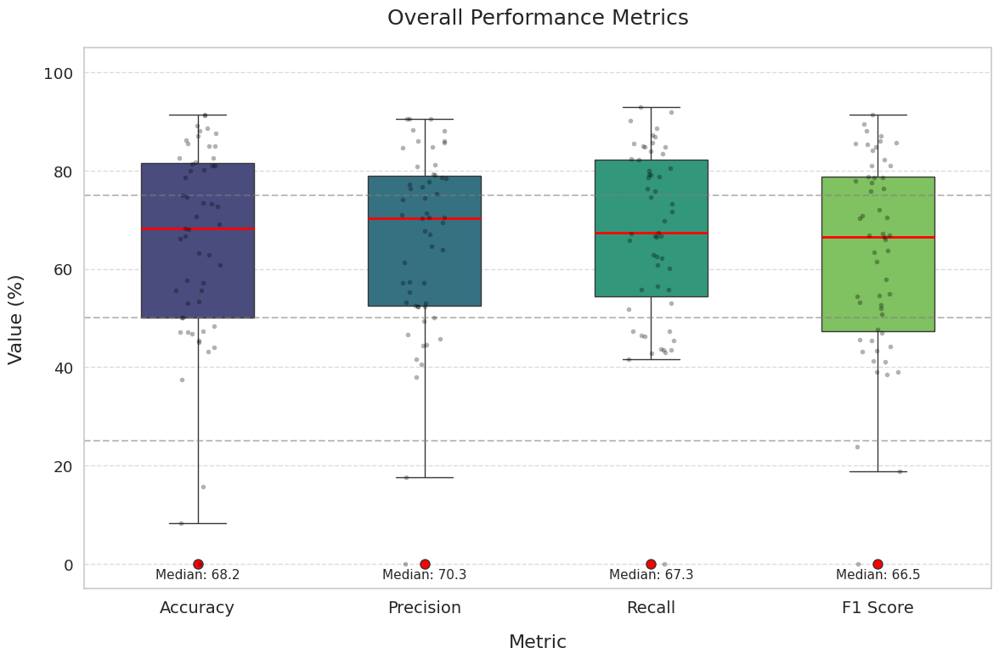

<ipython-input-30-831148b44776>:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(x='Metric', y='Value', data=melted_data,
<ipython-input-30-831148b44776>:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1 Score'], fontsize=14)


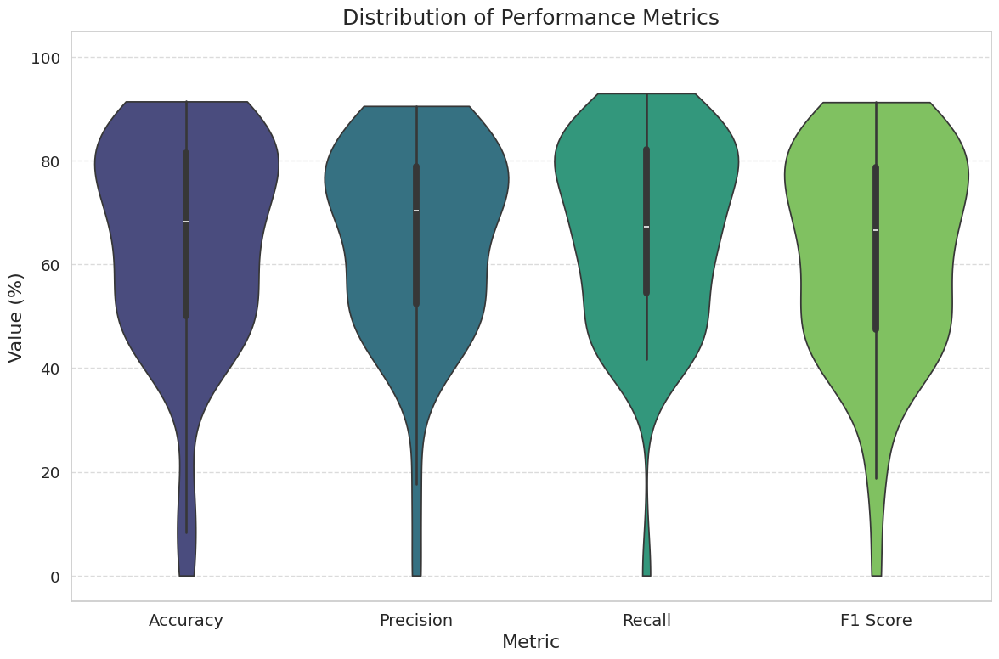

In [30]:
%matplotlib inline

metrics_to_plot = ['accuracy', 'overall_precision', 'overall_recall', 'overall_f1']

# Check data formatting
print(f"Number of rows in DataFrame: {len(df)}")
print(f"Data types: {df[metrics_to_plot].dtypes}")
print(f"Data range: Min={df[metrics_to_plot].min().min()}, Max={df[metrics_to_plot].max().max()}")

# Create a melted version of the data for seaborn boxplot
melted_data = pd.melt(df[metrics_to_plot], var_name='Metric', value_name='Value')

# Set the figure size and style
plt.figure(figsize=(12, 8))
sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=1.2)

# Create the boxplot - force the showfliers parameter to True to show outliers
ax = sns.boxplot(x='Metric', y='Value', data=melted_data,
                palette='viridis',
                width=0.5,
                showfliers=True,
                medianprops={"color": "red", "linewidth": 2},
                flierprops={"marker": "o", "markerfacecolor": "red", "markersize": 8})

# Add individual data points for better visibility
# Reduce the size and opacity so they don't overwhelm the plot
sns.stripplot(x='Metric', y='Value', data=melted_data,
              size=4, color='black', alpha=0.3, jitter=True)

# Customize the plot
plt.title('Overall Performance Metrics', fontsize=18, pad=20)
plt.xlabel('Metric', fontsize=16, labelpad=15)
plt.ylabel('Value (%)', fontsize=16, labelpad=15)

# Based on your summary statistics, your data ranges from 0 to approximately
# 92%, so set the y-axis limits to accommodate this with some padding
plt.ylim(-5, 105)

# Add horizontal lines for better reference
plt.axhline(y=50, color='gray', linestyle='--', alpha=0.5)
plt.axhline(y=75, color='gray', linestyle='--', alpha=0.5)
plt.axhline(y=25, color='gray', linestyle='--', alpha=0.5)

# Rename the x-axis labels to be more readable
ax.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1 Score'], fontsize=14)

# Annotate with summary statistics on the plot
for i, metric in enumerate(metrics_to_plot):
    median = df[metric].median()
    plt.text(i, -3, f"Median: {median:.1f}", ha='center', fontsize=11)

# Add grid for better readability, but only on the y-axis
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Ensure the plot is displayed with good spacing
plt.tight_layout()
plt.show()

# Let's also create a violin plot which might better show the distribution
plt.figure(figsize=(12, 8))
sns.set_style("whitegrid")

# Create violin plot with box plot inside
ax = sns.violinplot(x='Metric', y='Value', data=melted_data,
                   palette='viridis', inner='box', cut=0)

plt.title('Distribution of Performance Metrics', fontsize=18)
plt.xlabel('Metric', fontsize=16)
plt.ylabel('Value (%)', fontsize=16)
plt.ylim(-5, 105)
ax.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1 Score'], fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

<ipython-input-31-0a2fd080dea1>:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Metric', y='Value', data=melted_data,
<ipython-input-31-0a2fd080dea1>:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Precision', 'Recall', 'F1 Score'], fontsize=12)
<ipython-input-31-0a2fd080dea1>:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Metric', y='Value', data=melted_data,
<ipython-input-31-0a2fd080dea1>:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Precision', 'Recall', 'F1 Scor

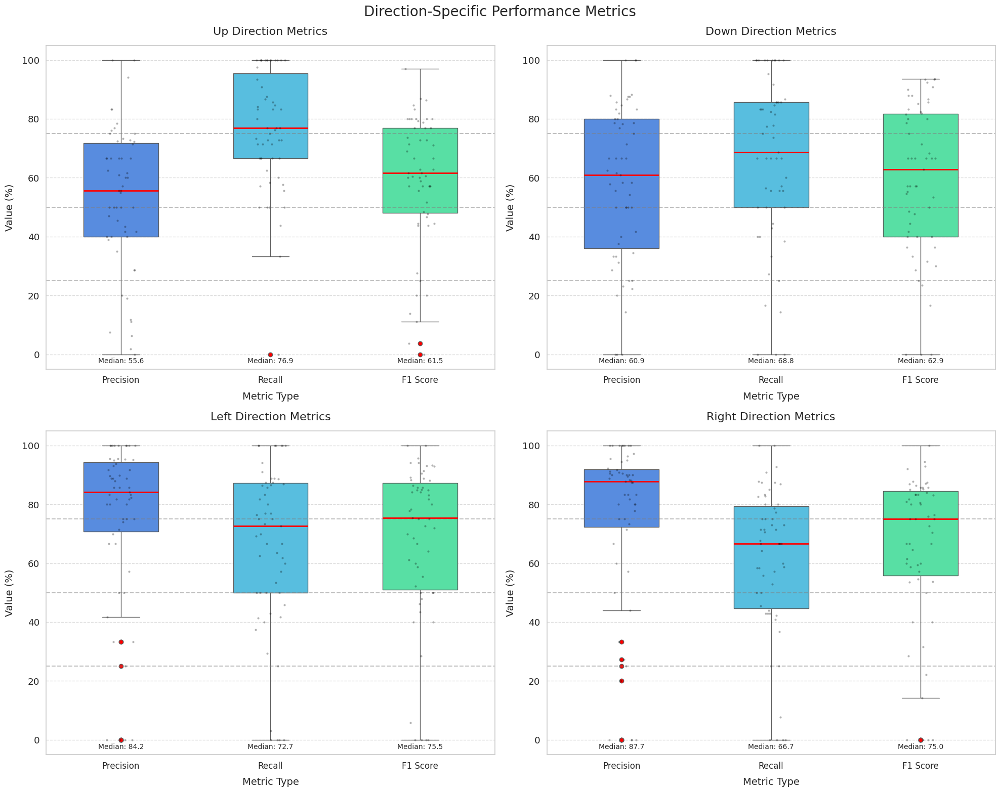

<ipython-input-31-0a2fd080dea1>:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Direction', y='Value', data=melted_data,
<ipython-input-31-0a2fd080dea1>:116: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Up', 'Down', 'Left', 'Right'], fontsize=12)
<ipython-input-31-0a2fd080dea1>:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Direction', y='Value', data=melted_data,
<ipython-input-31-0a2fd080dea1>:116: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Up', 'Down', 'Left', 'Righ

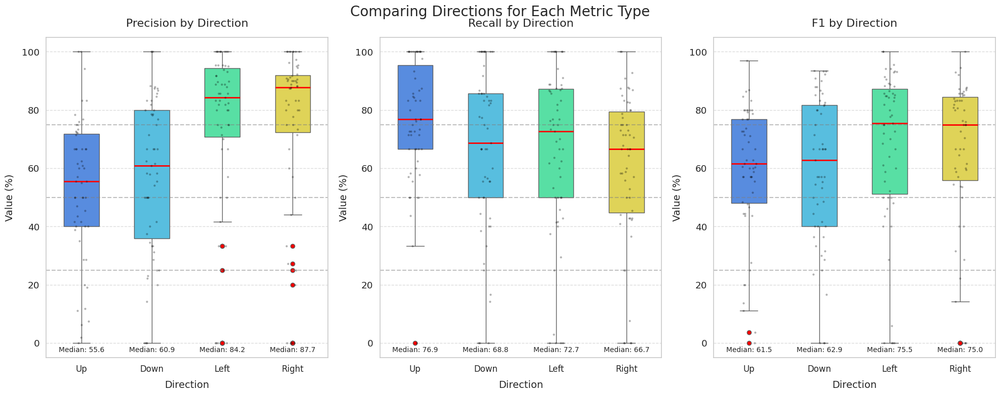

In [31]:
%matplotlib inline

# Create a figure with 4 subplots (2x2 grid)
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
plt.subplots_adjust(hspace=0.3, wspace=0.3)

# Define the directions and their corresponding metrics
directions = ['up', 'down', 'left', 'right']
metric_types = ['precision', 'recall', 'f1']

# Define colors for consistency
colors = ['#4287f5', '#42c9f5', '#42f5a7', '#f5e642']

# Loop through each direction and create subplot
for idx, direction in enumerate(directions):
    # Calculate subplot position (row, column)
    row = idx // 2
    col = idx % 2

    # Get current axis
    ax = axes[row, col]

    # Collect metrics for this direction
    direction_metrics = [f'{metric_type}_{direction}' for metric_type in metric_types]

    # Create melted data for this direction
    melted_data = pd.melt(df[direction_metrics], var_name='Metric', value_name='Value')

    # Create boxplot
    sns.boxplot(x='Metric', y='Value', data=melted_data,
                palette=colors[:len(metric_types)],
                width=0.5,
                showfliers=True,
                medianprops={"color": "red", "linewidth": 2},
                flierprops={"marker": "o", "markerfacecolor": "red", "markersize": 6},
                ax=ax)

    # Add individual data points
    sns.stripplot(x='Metric', y='Value', data=melted_data,
                  size=3, color='black', alpha=0.3, jitter=True, ax=ax)

    # Set labels and title for this subplot
    ax.set_title(f'{direction.capitalize()} Direction Metrics', fontsize=16, pad=15)
    ax.set_xlabel('Metric Type', fontsize=14, labelpad=10)
    ax.set_ylabel('Value (%)', fontsize=14, labelpad=10)

    # Set y-axis limits
    ax.set_ylim(-5, 105)

    # Add horizontal reference lines
    ax.axhline(y=50, color='gray', linestyle='--', alpha=0.5)
    ax.axhline(y=75, color='gray', linestyle='--', alpha=0.5)
    ax.axhline(y=25, color='gray', linestyle='--', alpha=0.5)

    # Rename x-tick labels to be more readable
    ax.set_xticklabels(['Precision', 'Recall', 'F1 Score'], fontsize=12)

    # Add grid
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    # Annotate with median values
    for i, metric in enumerate(direction_metrics):
        median = df[metric].median()
        ax.text(i, -3, f"Median: {median:.1f}", ha='center', fontsize=10)

# Add an overall title to the figure
fig.suptitle('Direction-Specific Performance Metrics', fontsize=20, y=0.98)

# Ensure the plot is displayed with good spacing
plt.tight_layout()
plt.subplots_adjust(top=0.93)  # Make room for the suptitle
plt.show()

# Set up a figure with 3 subplots (one for each metric type)
fig, axes = plt.subplots(1, 3, figsize=(20, 8))
plt.subplots_adjust(wspace=0.3)

# For each metric type (precision, recall, f1)
for i, metric_type in enumerate(metric_types):
    # Get current axis
    ax = axes[i]

    # Collect direction-specific metrics of this type
    type_metrics = [f'{metric_type}_{direction}' for direction in directions]

    # Create melted data for this metric type
    melted_data = pd.melt(df[type_metrics], var_name='Direction', value_name='Value')

    # Create boxplot
    sns.boxplot(x='Direction', y='Value', data=melted_data,
                palette=colors,
                width=0.5,
                showfliers=True,
                medianprops={"color": "red", "linewidth": 2},
                flierprops={"marker": "o", "markerfacecolor": "red", "markersize": 6},
                ax=ax)

    # Add individual data points
    sns.stripplot(x='Direction', y='Value', data=melted_data,
                  size=3, color='black', alpha=0.3, jitter=True, ax=ax)

    # Set labels and title
    ax.set_title(f'{metric_type.capitalize()} by Direction', fontsize=16, pad=15)
    ax.set_xlabel('Direction', fontsize=14, labelpad=10)
    ax.set_ylabel('Value (%)', fontsize=14, labelpad=10)

    # Set y-axis limits
    ax.set_ylim(-5, 105)

    # Add horizontal reference lines
    ax.axhline(y=50, color='gray', linestyle='--', alpha=0.5)
    ax.axhline(y=75, color='gray', linestyle='--', alpha=0.5)
    ax.axhline(y=25, color='gray', linestyle='--', alpha=0.5)

    # Update x-tick labels
    ax.set_xticklabels(['Up', 'Down', 'Left', 'Right'], fontsize=12)

    # Add grid
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    # Annotate with median values
    for j, metric in enumerate(type_metrics):
        median = df[metric].median()
        ax.text(j, -3, f"Median: {median:.1f}", ha='center', fontsize=10)

# Add an overall title
fig.suptitle('Comparing Directions for Each Metric Type', fontsize=20, y=0.98)

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

<ipython-input-26-55fe116b1efb>:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Metric', y='Value', data=melted_data,
<ipython-input-26-55fe116b1efb>:63: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Precision', 'Recall', 'F1 Score'], fontsize=12)
<ipython-input-26-55fe116b1efb>:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Metric', y='Value', data=melted_data,
<ipython-input-26-55fe116b1efb>:63: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Precision', 'Recall', 'F1 Scor

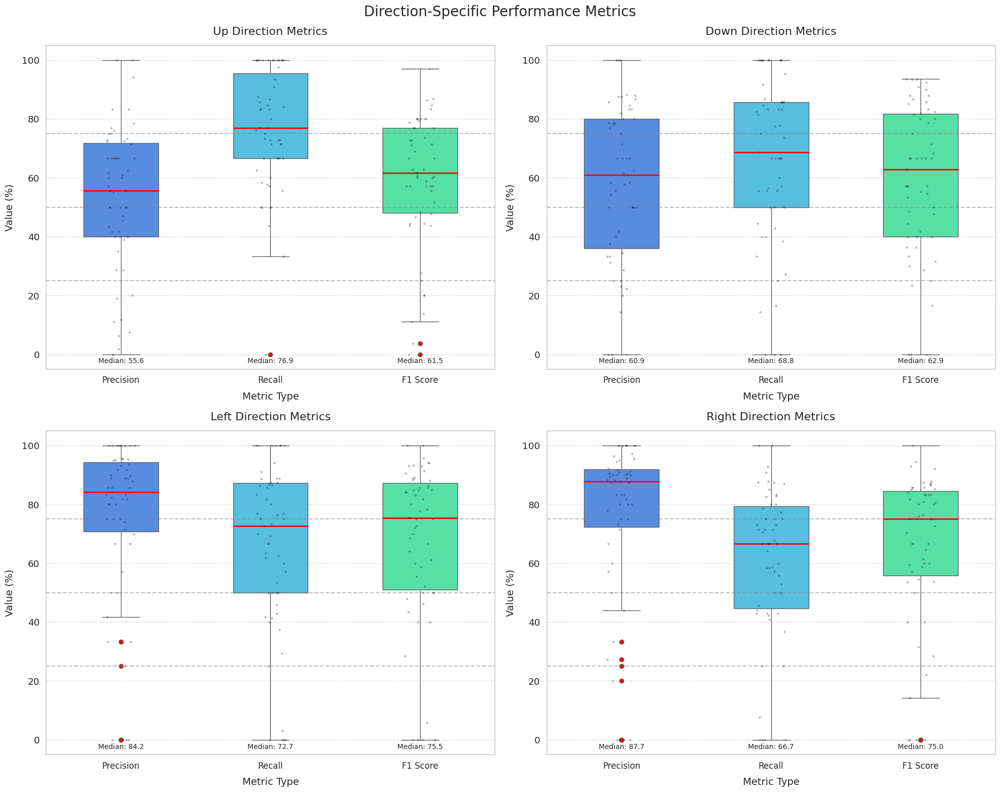


Summary Statistics for Direction Metrics:
       precision_up  recall_up  f1_up  precision_down  recall_down  f1_down  \
count          55.0       55.0   55.0            55.0         55.0     55.0   
mean           53.3       76.2   59.1            57.7         66.1     58.9   
std            24.4       20.6   22.5            26.9         28.6     25.7   
min             0.0        0.0    0.0             0.0          0.0      0.0   
25%            40.0       66.7   48.0            36.0         50.0     40.0   
50%            55.6       76.9   61.5            60.9         68.8     62.9   
75%            71.8       95.4   76.9            80.0         85.7     81.6   
max           100.0      100.0   97.0           100.0        100.0     93.5   

       precision_left  recall_left  f1_left  precision_right  recall_right  \
count            55.0         55.0     55.0             55.0          55.0   
mean             75.3         65.1     67.5             75.1          60.6   
std        

In [26]:
%matplotlib inline

# Create a figure with 4 subplots (2x2 grid)
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
plt.subplots_adjust(hspace=0.3, wspace=0.3)

# Define the directions and their corresponding metrics
directions = ['up', 'down', 'left', 'right']
metric_types = ['precision', 'recall', 'f1']

# Define colors for consistency
colors = ['#4287f5', '#42c9f5', '#42f5a7']

# Flatten the axes array for easier indexing
axes = axes.flatten()

# Loop through each direction and create subplot
for idx, direction in enumerate(directions):
    # Get current axis
    ax = axes[idx]

    # Collect metrics for this direction
    direction_metrics = [f'{metric_type}_{direction}' for metric_type in metric_types]

    # Create melted data for this direction
    melted_data = pd.melt(df[direction_metrics], var_name='Metric', value_name='Value')

    # Create boxplot
    sns.boxplot(x='Metric', y='Value', data=melted_data,
                palette=colors,
                width=0.5,
                showfliers=True,
                medianprops={"color": "red", "linewidth": 2},
                flierprops={"marker": "o", "markerfacecolor": "red", "markersize": 6},
                ax=ax)

    # Add individual data points
    sns.stripplot(x='Metric', y='Value', data=melted_data,
                  size=3, color='black', alpha=0.3, jitter=True, ax=ax)

    # Set labels and title for this subplot
    ax.set_title(f'{direction.capitalize()} Direction Metrics', fontsize=16, pad=15)
    ax.set_xlabel('Metric Type', fontsize=14, labelpad=10)
    ax.set_ylabel('Value (%)', fontsize=14, labelpad=10)

    # Set y-axis limits
    ax.set_ylim(-5, 105)

    # Add horizontal reference lines
    ax.axhline(y=50, color='gray', linestyle='--', alpha=0.5)
    ax.axhline(y=75, color='gray', linestyle='--', alpha=0.5)
    ax.axhline(y=25, color='gray', linestyle='--', alpha=0.5)

    # Rename x-tick labels to be more readable
    ax.set_xticklabels(['Precision', 'Recall', 'F1 Score'], fontsize=12)

    # Add grid
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    # Annotate with median values
    for i, metric in enumerate(direction_metrics):
        median = df[metric].median()
        ax.text(i, -3, f"Median: {median:.1f}", ha='center', fontsize=10)

# Add an overall title to the figure
fig.suptitle('Direction-Specific Performance Metrics', fontsize=20, y=0.98)

# Ensure the plot is displayed with good spacing
plt.tight_layout()
plt.subplots_adjust(top=0.93)  # Make room for the suptitle
plt.show()

# Print summary statistics for all direction metrics
print("\nSummary Statistics for Direction Metrics:")
direction_metrics_all = []
for direction in directions:
    for metric_type in metric_types:
        direction_metrics_all.append(f'{metric_type}_{direction}')

print(df[direction_metrics_all].describe().round(1))

/usr/local/lib/python3.11/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


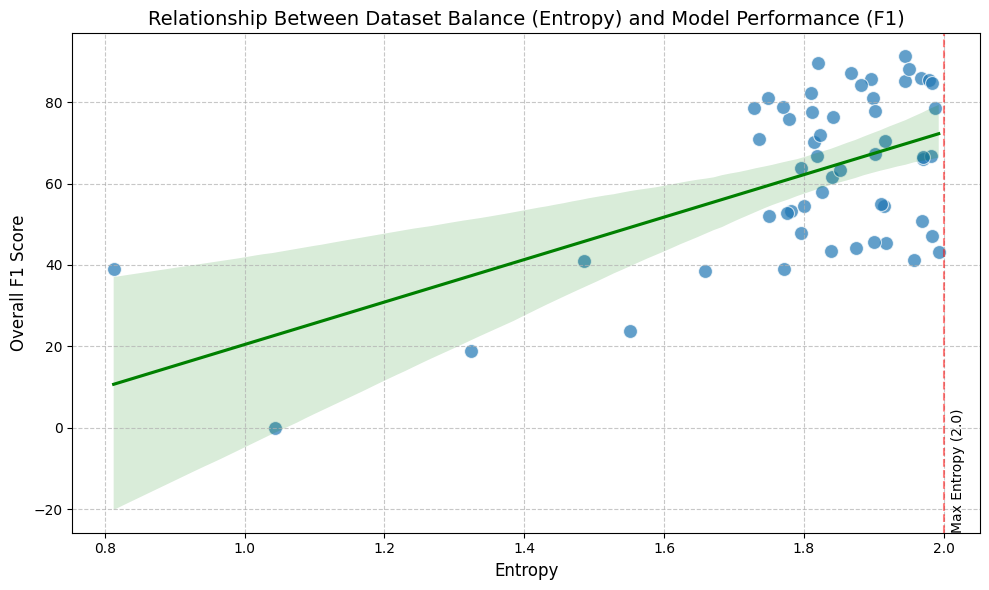

In [9]:
# Creating the scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x='entropy', y='overall_f1', data=df, s=100, alpha=0.7)

# Adding a trend line
sns.regplot(x='entropy', y='overall_f1', data=df, scatter=False, color='green')

# Adding labels and title
plt.xlabel('Entropy', fontsize=12)
plt.ylabel('Overall F1 Score', fontsize=12)
plt.title('Relationship Between Dataset Balance (Entropy) and Model Performance (F1)', fontsize=14)

# Add reference line for maximum entropy (2.0)
plt.axvline(x=2.0, color='red', linestyle='--', alpha=0.5)
plt.text(2.01, plt.ylim()[0] + 0.02, 'Max Entropy (2.0)', rotation=90, va='bottom')

# Improve the appearance
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Save the figure
plt.savefig('f1_vs_entropy.png', dpi=300)

# Show the plot
plt.show()

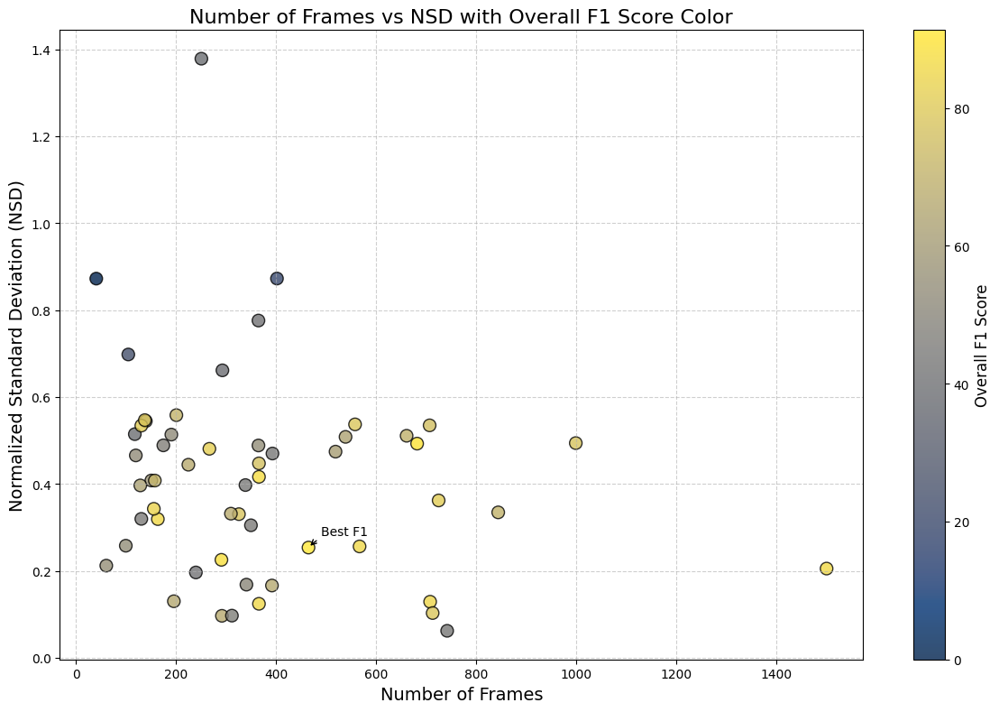

In [17]:
# Create the figure and axis
plt.figure(figsize=(12, 8))

# Create a scatter plot
scatter = plt.scatter(df['total_frames'], df['nsd'],
                      c=df['overall_f1'],
                      cmap='cividis',  # Using cividis colormap (colorblind friendly)
                      s=100,           # Size of markers
                      alpha=0.8,       # Transparency
                      edgecolors='black')

# Add a color bar
cbar = plt.colorbar(scatter)
cbar.set_label('Overall F1 Score', fontsize=12)

# Add labels and title
plt.xlabel('Number of Frames', fontsize=14)
plt.ylabel('Normalized Standard Deviation (NSD)', fontsize=14)
plt.title('Number of Frames vs NSD with Overall F1 Score Color', fontsize=16)

# Add grid
plt.grid(True, linestyle='--', alpha=0.6)

# Add annotations for key points
top_f1 = df['overall_f1'].idxmax()
plt.annotate('Best F1',
             xy=(df.loc[top_f1, 'total_frames'], df.loc[top_f1, 'nsd']),
             xytext=(10, 10),
             textcoords='offset points',
             arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=.2'))

# Improve layout
plt.tight_layout()

# Save the figure
plt.savefig('frames_nsd_f1_plot.png', dpi=300)

# Show the plot
plt.show()

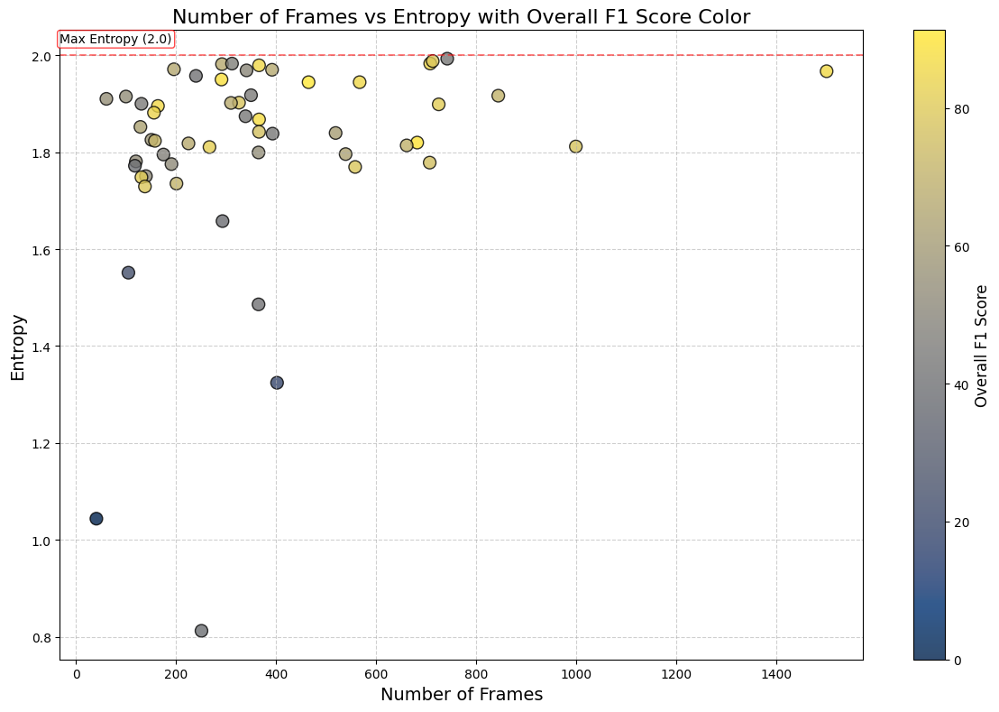

In [16]:
# Create the figure and axis
plt.figure(figsize=(12, 8))

# Create a scatter plot
scatter = plt.scatter(df['total_frames'], df['entropy'],
                      c=df['overall_f1'],
                      cmap='cividis',  # Using cividis colormap (colorblind friendly)
                      s=100,           # Size of markers
                      alpha=0.8,       # Transparency
                      edgecolors='black')

# Add a color bar
cbar = plt.colorbar(scatter)
cbar.set_label('Overall F1 Score', fontsize=12)

# Add labels and title
plt.xlabel('Number of Frames', fontsize=14)
plt.ylabel('Entropy', fontsize=14)
plt.title('Number of Frames vs Entropy with Overall F1 Score Color', fontsize=16)

# Add grid
plt.grid(True, linestyle='--', alpha=0.6)

# Add a horizontal line at maximum entropy (2.0)
plt.axhline(y=2.0, color='red', linestyle='--', alpha=0.5)
plt.text(plt.xlim()[0], 2.02, 'Max Entropy (2.0)', va='bottom', ha='left',
         bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="red", alpha=0.7))

# Improve layout
plt.tight_layout()

# Save the figure
plt.savefig('frames_entropy_f1_plot.png', dpi=300)

# Show the plot
plt.show()